<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/PEMBANGKITAN_DATA_SIMULASI%203%20(STRONG).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STRONG SPATIAL DEPENDENCE

In [1]:

# ================================================================
# FILE STRONG — rho = 0.80
# PEMBANGKITAN DATA SIMULASI SPASIAL
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import gc
import zipfile
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.sparse as sp

from scipy.spatial import cKDTree
from scipy.sparse.linalg import spsolve
from scipy.interpolate import UnivariateSpline

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor


# ================================================================
# SAMPLER TWEEDIE (1 < p < 2) : compound Poisson-Gamma
# ================================================================
TWEEDIE_POWER = 1.50
TWEEDIE_PHI = 0.08

TWEEDIE_INTERCEPT = 0.80
TWEEDIE_SIGNAL_SCALE = 0.35

BOBOT_POLA = 1.40
BOBOT_NONLINEAR = 0.80
BOBOT_ERROR_SAR = 0.50

def sample_tweedie(mu, phi, p, rng):
    mu = np.asarray(mu, dtype=float)
    phi = np.broadcast_to(np.asarray(phi, dtype=float), mu.shape)
    if not (1 < p < 2) or not np.all(mu > 0) or not np.all(phi > 0):
        raise ValueError("Butuh 1<p<2, mu>0, phi>0")
    lam = mu ** (2 - p) / (phi * (2 - p))
    count = rng.poisson(lam)
    shape = count * (2 - p) / (p - 1)
    scale = phi * (p - 1) * mu ** (p - 1)
    y = np.zeros_like(mu)
    active = count > 0
    y[active] = rng.gamma(shape=shape[active], scale=scale[active])
    return y


# ================================================================
# DISPLAY
# ================================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 3000)
pd.set_option("display.max_colwidth", None)


# ================================================================
# 1. KONFIGURASI STRONG
# ================================================================

RHO_STRONG = 0.80
ERROR_SD = 0.15
SPLINE_SMOOTH = 0.60

PATTERNS = ["Hotspot", "Koridor", "Gelombang"]
W_METHODS = ["KNN5", "DISTANCE", "IDW"]
ERROR_TYPES = ["Homogeneous", "Heterogeneous"]
MODEL_PREDICTORS = ["X1", "X2", "X3"]

BASE_OUTPUT_STRONG = Path("/content/SIMULASI_STRONG_RHO080_SEIMBANG_MULTIKOL")
BASE_OUTPUT_STRONG.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. BETA — DIBANGKITKAN SATU KALI, LALU DIKUNCI
#    Gunakan seed yang sama untuk WEAK, MODERATE, dan STRONG
# ================================================================

BETA_SEED = 2025
rng_beta = np.random.default_rng(BETA_SEED)

BETA_1, BETA_2, BETA_3 = rng_beta.uniform(
    -2,
    2,
    size=3
)

print("=" * 70)
print("KOEFISIEN NONLINEAR — DIPAKAI SAMA UNTUK SEMUA SKENARIO")
print("=" * 70)
print(f"beta1 = {BETA_1:.6f}")
print(f"beta2 = {BETA_2:.6f}")
print(f"beta3 = {BETA_3:.6f}")


# ================================================================
# 3. FUNGSI BANTU
# ================================================================

def standardize(v):
    v = np.asarray(v, dtype=float)
    sd = np.std(v, ddof=0)

    if sd <= 1e-12:
        return v - np.mean(v)

    return (v - np.mean(v)) / sd


def row_standardize(W):
    W = W.tocsr().astype(float)

    row_sum = np.asarray(
        W.sum(axis=1)
    ).ravel()

    inv = np.zeros_like(
        row_sum,
        dtype=float
    )

    valid = row_sum > 0
    inv[valid] = 1.0 / row_sum[valid]

    return (
        sp.diags(inv)
        @ W
    ).tocsr()


def gaussian_hotspot(
    u,
    v,
    cu,
    cv,
    sigma,
    amplitude=1.0
):
    return (
        amplitude
        *
        np.exp(
            -(
                (u-cu)**2
                +
                (v-cv)**2
            )
            /
            (2*sigma**2)
        )
    )


def smooth_spline_curve(
    x,
    y,
    smooth_fraction=0.60
):
    temp = pd.DataFrame({
        "x": np.asarray(x),
        "y": np.asarray(y)
    })

    temp["x_round"] = temp["x"].round(8)

    temp = (
        temp
        .groupby("x_round", as_index=False)
        .agg(
            x=("x", "mean"),
            y=("y", "mean")
        )
        .sort_values("x")
    )

    xs = temp["x"].to_numpy()
    ys = temp["y"].to_numpy()

    if len(xs) < 4:
        return xs, ys

    smoothing = (
        smooth_fraction
        *
        len(xs)
        *
        max(np.var(ys), 1e-6)
    )

    spline = UnivariateSpline(
        xs,
        ys,
        k=3,
        s=smoothing
    )

    xx = np.linspace(
        xs.min(),
        xs.max(),
        400
    )

    yy = spline(xx)

    return xx, yy


def moran_I(y, W):
    y = np.asarray(
        y,
        dtype=float
    )

    z = y - np.mean(y)

    denominator = float(
        z @ z
    )

    if denominator <= 0:
        return np.nan

    numerator = float(
        z @ (W @ z)
    )

    S0 = float(
        W.sum()
    )

    return float(
        (len(y)/S0)
        *
        (numerator/denominator)
    )


# ================================================================
# 4. FUNGSI UTAMA
# SATU GRID = SEMUA PROSES + VISUAL + VALIDASI
# ================================================================

def run_strong_grid(grid_size):

    rho = RHO_STRONG
    N = grid_size * grid_size

    OUTPUT_DIR = (
        BASE_OUTPUT_STRONG
        /
        f"GRID{grid_size}"
    )

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    print("\n")
    print("=" * 120)
    print(f"STRONG SPATIAL DEPENDENCE — rho={rho:.2f}")
    print(f"GRID {grid_size} × {grid_size}")
    print(f"N = {N}")
    print("=" * 120)


    # ============================================================
    # A. LOKASI / GRID
    # Koordinat asli = u_raw, v_raw
    # Koordinat normalisasi = u, v
    # ============================================================

    grid_row = np.repeat(
        np.arange(grid_size),
        grid_size
    )

    grid_col = np.tile(
        np.arange(grid_size),
        grid_size
    )

    u_raw = grid_col.astype(float)
    v_raw = grid_row.astype(float)

    coords_raw = np.column_stack([
        u_raw,
        v_raw
    ])

    u = (
        u_raw
        /
        (grid_size - 1)
    )

    v = (
        v_raw
        /
        (grid_size - 1)
    )

    GRID = pd.DataFrame({
        "Location_ID": np.arange(1, N+1),
        "Grid_Row": grid_row,
        "Grid_Col": grid_col,
        "u_raw": u_raw,
        "v_raw": v_raw,
        "u": u,
        "v": v
    })

    print("\n✅ A. GRID / KOORDINAT BERHASIL")


    # ============================================================
    # VISUAL 0 — TITIK LOKASI AWAL
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    ax.scatter(
        u_raw,
        v_raw,
        s=30
    )

    # Label ID hanya untuk grid kecil supaya tidak terlalu penuh
    if grid_size <= 20:
        for i in range(N):
            ax.text(
                u_raw[i],
                v_raw[i] + 0.08,
                str(i+1),
                fontsize=6,
                ha="center"
            )

    ax.set_title(
        (
            "Titik Lokasi Awal Sebelum Pembentukan Y\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Koordinat u (asli)")
    ax.set_ylabel("Koordinat v (asli)")
    ax.set_aspect("equal")
    ax.grid(alpha=.20)

    FILE_VIS0 = (
        OUTPUT_DIR
        /
        "00_TITIK_LOKASI_AWAL.png"
    )

    plt.tight_layout()
    plt.savefig(
        FILE_VIS0,
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


    # ============================================================
    # B. POLA SPASIAL LATEN Z(s)
    # ============================================================

    # ---------------- HOTSPOT ----------------

    hotspot_big = gaussian_hotspot(
        u,
        v,
        cu=0.32,
        cv=0.56,
        sigma=0.17,
        amplitude=1.80
    )

    hotspot_small = gaussian_hotspot(
        u,
        v,
        cu=0.74,
        cv=0.76,
        sigma=0.085,
        amplitude=1.30
    )

    hotspot_irregular = (
        0.08
        *
        np.sin(
            3*np.pi*u
        )
        *
        np.cos(
            2*np.pi*v
        )
    )

    HOTSPOT_PARTS = {
        "besar": standardize(hotspot_big),
        "kecil": standardize(hotspot_small),
        "gabungan": standardize(
            hotspot_big
            +
            hotspot_small
            +
            hotspot_irregular
        )
    }


    # ---------------- KORIDOR ----------------

    centerline = (
        0.20
        +
        0.54*u
        +
        0.10*np.sin(
            2.6*np.pi*u + 0.40
        )
        -
        0.045*np.sin(
            5.4*np.pi*u
        )
    )

    corridor_distance = np.abs(
        v - centerline
    )

    corridor_width = (
        0.065
        +
        0.020
        *
        (
            1
            +
            np.sin(
                3*np.pi*u
            )
        )
    )

    corridor_main = np.exp(
        -(corridor_distance**2)
        /
        (
            2
            *
            corridor_width**2
        )
    )

    taper_left = (
        1
        /
        (
            1
            +
            np.exp(
                -(u-0.10)/0.025
            )
        )
    )

    taper_right = (
        1
        /
        (
            1
            +
            np.exp(
                (u-0.90)/0.025
            )
        )
    )

    corridor_main = (
        corridor_main
        *
        taper_left
        *
        taper_right
    )

    corridor_bump1 = gaussian_hotspot(
        u,
        v,
        cu=0.28,
        cv=0.38,
        sigma=0.085,
        amplitude=0.45
    )

    corridor_bump2 = gaussian_hotspot(
        u,
        v,
        cu=0.72,
        cv=0.67,
        sigma=0.070,
        amplitude=0.35
    )

    corridor_local = (
        corridor_bump1
        +
        corridor_bump2
    )

    corridor_roughness = (
        0.08
        *
        np.sin(
            5*np.pi*u
            +
            1.2*v
        )
    )

    CORRIDOR_PARTS = {
        "utama": standardize(corridor_main),
        "lokal": standardize(corridor_local),
        "gabungan": standardize(
            1.15*corridor_main
            +
            corridor_local
            +
            corridor_roughness
        )
    }


    # ---------------- GELOMBANG ----------------

    wave_large = (
        1.15
        *
        np.sin(
            2.5*np.pi*u
            +
            0.30
        )
        +
        0.95
        *
        np.cos(
            2.1*np.pi*v
            -
            0.20
        )
    )

    wave_secondary = (
        0.55
        *
        np.sin(
            4.0*np.pi*u
            -
            1.7*np.pi*v
        )
    )

    wave_diagonal = (
        0.40
        *
        np.sin(
            2*np.pi*(u+v)
            +
            0.50
        )
    )

    WAVE_PARTS = {
        "besar": standardize(wave_large),
        "kecil": standardize(
            wave_secondary
            +
            wave_diagonal
        ),
        "gabungan": standardize(
            wave_large
            +
            wave_secondary
            +
            wave_diagonal
        )
    }

    Z_PATTERN = {
        "Hotspot": HOTSPOT_PARTS["gabungan"],
        "Koridor": CORRIDOR_PARTS["gabungan"],
        "Gelombang": WAVE_PARTS["gabungan"]
    }

    print("✅ B. Z(s) SELESAI")


    # ============================================================
    # VISUAL 1 — POLA Z(s)
    # ============================================================

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(12, 12)
    )

    visual_components = [
        (
            "Hotspot",
            HOTSPOT_PARTS["besar"],
            HOTSPOT_PARTS["kecil"],
            HOTSPOT_PARTS["gabungan"]
        ),
        (
            "Koridor",
            CORRIDOR_PARTS["utama"],
            CORRIDOR_PARTS["lokal"],
            CORRIDOR_PARTS["gabungan"]
        ),
        (
            "Gelombang",
            WAVE_PARTS["besar"],
            WAVE_PARTS["kecil"],
            WAVE_PARTS["gabungan"]
        )
    ]

    titles = [
        "Struktur Besar/Utama",
        "Struktur Kecil/Lokal",
        "Gabungan Z(s)"
    ]

    for r, (
        pattern,
        part1,
        part2,
        combined
    ) in enumerate(
        visual_components
    ):

        for c, values in enumerate(
            [
                part1,
                part2,
                combined
            ]
        ):

            matrix = values.reshape(
                grid_size,
                grid_size
            )

            im = axes[r, c].imshow(
                matrix,
                origin="lower",
                cmap="viridis",
                interpolation="nearest"
            )

            if r == 0:
                axes[r, c].set_title(
                    titles[c],
                    fontweight="bold"
                )

            if c == 0:
                axes[r, c].set_ylabel(
                    pattern,
                    fontweight="bold"
                )

            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])

            plt.colorbar(
                im,
                ax=axes[r, c],
                fraction=.046,
                pad=.04
            )

    fig.suptitle(
        (
            f"Latent Spatial Pattern Z(s)\n"
            f"Grid {grid_size}×{grid_size} | Strong rho=0.80"
        ),
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS1 = (
        OUTPUT_DIR
        /
        "01_LATENT_PATTERN.png"
    )

    plt.savefig(
        FILE_VIS1,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # C. X1, X2, X3 + g(X)
    # ============================================================

    rng_x = np.random.default_rng(
        2026 + grid_size
    )

    X_DATA = rng_x.normal(
        0,
        1,
        size=(N, 3)
    )

    for j in range(3):
        X_DATA[:, j] = standardize(
            X_DATA[:, j]
        )

    X1 = X_DATA[:, 0]
    X2 = X_DATA[:, 1]
    X3 = X_DATA[:, 2]


    # ------------------------------------------------------------
    # NONLINEAR COMPONENT — standardisasi tiap fungsi sebelum agregasi
    # g(X) = beta1 Std(X1^2) + beta2 Std(X2^2) + beta3 Std(sin(X3))
    # ------------------------------------------------------------
    F1 = standardize(X1**2)
    F2 = standardize(X2**2)
    F3 = standardize(np.sin(X3))
    K1 = BETA_1 * F1
    K2 = BETA_2 * F2
    K3 = BETA_3 * F3
    GX_RAW = K1 + K2 + K3
    GX = standardize(GX_RAW)

    print(f"\nDIAGNOSTIK GRID {grid_size}x{grid_size}")
    print(f"Beta 1 = {BETA_1:.4f}")
    print(f"Beta 2 = {BETA_2:.4f}")
    print(f"Beta 3 = {BETA_3:.4f}")

    print("\nSimpangan baku kontribusi:")
    print(f"X1 kuadratik = {np.std(K1):.4f}")
    print(f"X2 kuadratik = {np.std(K2):.4f}")
    print(f"X3 sinus     = {np.std(K3):.4f}")

    print("✅ C. X1, X2, X3 + g(X) SELESAI")

    print(
        (
            f"   beta = "
            f"({BETA_1:.4f}, "
            f"{BETA_2:.4f}, "
            f"{BETA_3:.4f})"
        )
    )


    print(
        f"   SD g(X) setelah standardisasi = {np.std(GX):.4f}"
    )


    # ============================================================
    # DIAGNOSTIK MULTIKOLINEARITAS — X1, X2, X3 (prediktor utama)
    # X sama untuk seluruh 18 skenario pada grid ini.
    # VIF < 5: rendah; 5 <= VIF < 10: perlu perhatian; >= 10: tinggi.
    # Ambang ini merupakan pedoman diagnostik, bukan uji hipotesis.
    # ============================================================
    X_MULTIKOL = pd.DataFrame(X_DATA, columns=MODEL_PREDICTORS)
    CORR_X = X_MULTIKOL.corr(method="pearson")
    X_VIF = sm.add_constant(X_MULTIKOL, has_constant="add")
    VIF_ROWS = []
    for j, name in enumerate(MODEL_PREDICTORS, start=1):
        vif = float(variance_inflation_factor(X_VIF.to_numpy(), j))
        VIF_ROWS.append({
            "Grid": f"{grid_size}x{grid_size}",
            "Predictor": name,
            "VIF": vif,
            "Tolerance": 1.0 / vif if vif > 0 else np.nan,
            "Status": "TINGGI" if vif >= 10 else (
                "PERHATIAN" if vif >= 5 else "RENDAH")
        })
    VIF_TABLE = pd.DataFrame(VIF_ROWS)
    print("\nCEK MULTIKOLINEARITAS PREDIKTOR UTAMA:")
    display(VIF_TABLE.round(4))
    print("Matriks korelasi Pearson:")
    display(CORR_X.round(4))
    VIF_TABLE.to_csv(OUTPUT_DIR / f"VIF_GRID{grid_size}.csv", index=False)
    CORR_X.to_csv(OUTPUT_DIR / f"KORELASI_X_GRID{grid_size}.csv")

    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(CORR_X.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(MODEL_PREDICTORS)), MODEL_PREDICTORS)
    ax.set_yticks(range(len(MODEL_PREDICTORS)), MODEL_PREDICTORS)
    for i in range(len(MODEL_PREDICTORS)):
        for j in range(len(MODEL_PREDICTORS)):
            val = CORR_X.iloc[i, j]
            ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                    color="white" if abs(val) > .65 else "black")
    fig.colorbar(im, ax=ax, label="Korelasi Pearson")
    ax.set_title(f"Korelasi Prediktor | Grid {grid_size}x{grid_size}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "02_KORELASI_MULTIKOL.png", dpi=200,
                bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Visualisasi nonlinier dipindahkan ke VISUAL 6,
    # setelah respons akhir Y dibangkitkan untuk seluruh skenario.


    # ============================================================
    # D. BUILD W
    # ============================================================

    tree = cKDTree(
        coords_raw
    )


    # ---------------- KNN5 ----------------

    _, indices_knn = tree.query(
        coords_raw,
        k=6
    )

    rows_knn = np.repeat(
        np.arange(N),
        5
    )

    cols_knn = (
        indices_knn[:, 1:6]
        .reshape(-1)
    )

    vals_knn = np.ones(
        len(rows_knn)
    )

    W_KNN5 = sp.csr_matrix(
        (
            vals_knn,
            (
                rows_knn,
                cols_knn
            )
        ),
        shape=(N, N)
    )

    W_KNN5 = row_standardize(
        W_KNN5
    )


    # ---------------- DISTANCE BAND <= 1.5 ----------------

    pairs_distance = np.array(
        list(
            tree.query_pairs(
                r=1.5
            )
        ),
        dtype=int
    )

    if len(pairs_distance) > 0:

        rows_d = np.concatenate([
            pairs_distance[:, 0],
            pairs_distance[:, 1]
        ])

        cols_d = np.concatenate([
            pairs_distance[:, 1],
            pairs_distance[:, 0]
        ])

        vals_d = np.ones(
            len(rows_d)
        )

    else:

        rows_d = np.array(
            [],
            dtype=int
        )

        cols_d = np.array(
            [],
            dtype=int
        )

        vals_d = np.array(
            [],
            dtype=float
        )

    W_DISTANCE = sp.csr_matrix(
        (
            vals_d,
            (
                rows_d,
                cols_d
            )
        ),
        shape=(N, N)
    )

    W_DISTANCE = row_standardize(
        W_DISTANCE
    )


    # ---------------- IDW radius 2.5 ----------------

    pairs_idw = np.array(
        list(
            tree.query_pairs(
                r=2.5
            )
        ),
        dtype=int
    )

    if len(pairs_idw) > 0:

        i1 = pairs_idw[:, 0]
        i2 = pairs_idw[:, 1]

        dist_idw = np.linalg.norm(
            coords_raw[i1]
            -
            coords_raw[i2],
            axis=1
        )

        weight_idw = (
            1.0
            /
            dist_idw
        )

        rows_i = np.concatenate([
            i1,
            i2
        ])

        cols_i = np.concatenate([
            i2,
            i1
        ])

        vals_i = np.concatenate([
            weight_idw,
            weight_idw
        ])

    else:

        rows_i = np.array(
            [],
            dtype=int
        )

        cols_i = np.array(
            [],
            dtype=int
        )

        vals_i = np.array(
            [],
            dtype=float
        )

    W_IDW = sp.csr_matrix(
        (
            vals_i,
            (
                rows_i,
                cols_i
            )
        ),
        shape=(N, N)
    )

    W_IDW = row_standardize(
        W_IDW
    )


    W_STORE = {
        "KNN5": W_KNN5,
        "DISTANCE": W_DISTANCE,
        "IDW": W_IDW
    }


    # ============================================================
    # INFORMASI W
    # ============================================================

    W_INFO_ROWS = []

    for method in W_METHODS:

        W = W_STORE[
            method
        ]

        counts = np.diff(
            W.indptr
        )

        W_INFO_ROWS.append({

            "Grid":
                f"{grid_size}x{grid_size}",

            "W_Method":
                method,

            "Min_Neighbor":
                int(
                    counts.min()
                ),

            "Mean_Neighbor":
                float(
                    counts.mean()
                ),

            "Max_Neighbor":
                int(
                    counts.max()
                )

        })

    W_INFO = pd.DataFrame(
        W_INFO_ROWS
    )

    print("✅ D. W SELESAI")
    display(
        W_INFO.round(2)
    )


    # ============================================================
    # VISUAL 3 — W
    # ============================================================

    target_index = np.argmin(
        (u-.5)**2
        +
        (v-.5)**2
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    for ax, method in zip(
        axes,
        W_METHODS
    ):

        W = W_STORE[
            method
        ].tocsr()

        start = W.indptr[
            target_index
        ]

        end = W.indptr[
            target_index+1
        ]

        neighbors = W.indices[
            start:end
        ]

        ax.scatter(
            u_raw,
            v_raw,
            s=12,
            alpha=.20
        )

        ax.scatter(
            u_raw[neighbors],
            v_raw[neighbors],
            s=70,
            label="Tetangga"
        )

        ax.scatter(
            u_raw[target_index],
            v_raw[target_index],
            marker="*",
            s=220,
            label="Lokasi pusat"
        )

        for j in neighbors:

            ax.plot(
                [
                    u_raw[target_index],
                    u_raw[j]
                ],
                [
                    v_raw[target_index],
                    v_raw[j]
                ],
                linewidth=.8,
                alpha=.50
            )

        title_w = {
            "KNN5": "KNN-5",
            "DISTANCE": "Distance Band",
            "IDW": "IDW"
        }[
            method
        ]

        ax.set_title(
            (
                f"{title_w}\n"
                f"k={len(neighbors)}"
            ),
            fontweight="bold"
        )

        ax.set_aspect("equal")
        ax.legend(
            fontsize=7
        )

    fig.suptitle(
        (
            "Struktur Ketetanggaan W\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS3 = (
        OUTPUT_DIR
        /
        "03_STRUKTUR_W.png"
    )

    plt.savefig(
        FILE_VIS3,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # E. ERROR
    # ============================================================

    rng_error = np.random.default_rng(
        2027 + grid_size
    )

    BASE_ERROR = rng_error.normal(
        0,
        1,
        N
    )

    def generate_error(
        error_type
    ):

        if (
            error_type
            ==
            "Homogeneous"
        ):

            variance = np.ones(
                N
            )

            error = (
                ERROR_SD
                *
                BASE_ERROR
            )

        else:

            # Dua zona berdasarkan koordinat u
            variance = np.where(
                u <= .5,
                .5,
                1.5
            )

            error = (
                ERROR_SD
                *
                np.sqrt(
                    variance
                )
                *
                BASE_ERROR
            )

        return (
            error,
            variance
        )


    # ============================================================
    # F. GENERATE 18 SKENARIO
    #
    # DGP FINAL:
    # eta = Z(s) + g(X) + error
    # sar_signal = (I - rho W)^(-1)*(b_z*Z(s) + b_g*g(X) + b_e*error)
    # mu = exp(intercept + scale*sar_signal)
    # Y ~ Tweedie(mu, phi, p)
    # ============================================================

    ALL_DATA = []

    for pattern in PATTERNS:

        Z_SPATIAL = Z_PATTERN[
            pattern
        ]

        for error_type in ERROR_TYPES:

            ERROR, ERROR_VARIANCE = (
                generate_error(
                    error_type
                )
            )

            ETA = (
                Z_SPATIAL
                +
                GX
                +
                ERROR
            )

            for w_method in W_METHODS:

                W = W_STORE[
                    w_method
                ]

                A = (
                    sp.eye(
                        N,
                        format="csr"
                    )
                    -
                    rho
                    *
                    W
                )


                # ====================================================
                # PEMBANGKITAN SAR-TWEEDIE
                # POLA Z(s) DIBERI KONTRIBUSI EKSPLISIT
                # ====================================================

                # Tetap mempertahankan ETA untuk diagnostik lama
                # ETA = Z_SPATIAL + GX + ERROR

                # Galat SAR tetap disimpan sebagai diagnostik.
                ETA_SAR = np.asarray(
                    spsolve(A, ERROR), dtype=float
                )

                # Operator SAR diterapkan pada SELURUH sinyal laten.
                # Hanya rho yang berbeda antar WEAK/MODERATE/STRONG.
                LATENT_INPUT = (
                    BOBOT_POLA * Z_SPATIAL
                    + BOBOT_NONLINEAR * GX
                    + BOBOT_ERROR_SAR * ERROR
                )
                # Standardisasi diperlukan agar rho tinggi tidak
                # menghasilkan lonjakan skala exp(log(mu)).
                SAR_SIGNAL = standardize(
                    np.asarray(spsolve(A, LATENT_INPUT), dtype=float)
                )
                LINEAR_PREDICTOR = (
                    TWEEDIE_INTERCEPT
                    + TWEEDIE_SIGNAL_SCALE * SAR_SIGNAL
                )
                if (not np.isfinite(LINEAR_PREDICTOR).all()
                        or np.max(LINEAR_PREDICTOR) > 20
                        or np.min(LINEAR_PREDICTOR) < -20):
                    raise ValueError("Prediktor Tweedie tidak stabil")

                MU = np.exp(LINEAR_PREDICTOR)

                # Dispersi mengikuti struktur zona
                PHI = TWEEDIE_PHI * ERROR_VARIANCE
                seed_y = (
                    2028 + grid_size * 10000
                    + PATTERNS.index(pattern) * 1000
                    + ERROR_TYPES.index(error_type) * 100
                    + W_METHODS.index(w_method)
                )
                Y = sample_tweedie(
                    MU, PHI, TWEEDIE_POWER,
                    np.random.default_rng(seed_y)
                )
                assert np.isfinite(Y).all() and (Y >= 0).all()

                MORAN_Y = moran_I(
                    Y,
                    W
                )

                CORR_ZY = float(
                    np.corrcoef(
                        Z_SPATIAL,
                        Y
                    )[0, 1]
                )
                CORR_ZMU = float(
                    np.corrcoef(Z_SPATIAL, MU)[0, 1]
                )

                scenario_id = (
                    f"G{grid_size}_"
                    f"{pattern.upper()}_"
                    f"{w_method}_"
                    f"{'HOMO' if error_type == 'Homogeneous' else 'HETERO'}_"
                    f"RHO80"
                )

                temp = GRID.copy()

                temp[
                    "Scenario_ID"
                ] = scenario_id

                temp[
                    "Grid"
                ] = (
                    f"{grid_size}x{grid_size}"
                )

                temp["N"] = N
                temp["Strength"] = "Strong"
                temp["Rho"] = rho
                temp["Pattern"] = pattern
                temp["W_Method"] = w_method
                temp["Error_Structure"] = error_type

                temp[
                    "Z_spatial_latent"
                ] = Z_SPATIAL

                temp["X1"] = X1
                temp["X2"] = X2
                temp["X3"] = X3

                temp[
                    "Beta1"
                ] = BETA_1

                temp[
                    "Beta2"
                ] = BETA_2

                temp[
                    "Beta3"
                ] = BETA_3

                temp[
                    "gX_raw"
                ] = GX_RAW

                temp[
                    "gX_nonlinear"
                ] = GX

                # Tetap disimpan untuk kompatibilitas tabel lama
                temp[
                    "Spatial_Signal"
                ] = Z_SPATIAL

                temp[
                    "Error"
                ] = ERROR

                temp[
                    "Error_Variance"
                ] = ERROR_VARIANCE

                temp[
                    "Eta"
                ] = ETA

                temp["Eta_SAR"] = ETA_SAR
                temp["SAR_Signal"] = SAR_SIGNAL
                temp["Linear_Predictor"] = LINEAR_PREDICTOR
                temp["Mu_Tweedie"] = MU
                temp["Phi_Tweedie"] = PHI
                temp["Tweedie_Power"] = TWEEDIE_POWER
                temp["Y"] = Y

                temp[
                    "Moran_I_Y"
                ] = MORAN_Y

                temp[
                    "Corr_Z_Y"
                ] = CORR_ZY

                temp["Corr_Z_Mu"] = CORR_ZMU

                ALL_DATA.append(
                    temp
                )

    DATA = pd.concat(
        ALL_DATA,
        ignore_index=True
    )

    assert (
        DATA[
            "Scenario_ID"
        ].nunique()
        ==
        18
    )

    print("✅ E. 18 SKENARIO Y TWEEDIE SELESAI")
    print(f"   Y minimum = {DATA['Y'].min():.6f}")
    print(f"   Proporsi nol = {(DATA['Y'] == 0).mean():.2%}")


    # ============================================================
    # VISUAL 4 — 18 Y
    # ============================================================

    rows_visual = [
        (
            p,
            e
        )
        for p in PATTERNS
        for e in ERROR_TYPES
    ]

    vmin = float(
        DATA[
            "Y"
        ].min()
    )

    vmax = float(
        DATA[
            "Y"
        ].max()
    )

    norm = mpl.colors.Normalize(
        vmin=vmin,
        vmax=vmax
    )

    fig, axes = plt.subplots(
        6,
        3,
        figsize=(14, 24)
    )

    last_im = None

    for r, (
        pattern,
        error_type
    ) in enumerate(
        rows_visual
    ):

        for c, w_method in enumerate(
            W_METHODS
        ):

            ax = axes[
                r,
                c
            ]

            d = (
                DATA[
                    (
                        DATA["Pattern"]
                        ==
                        pattern
                    )
                    &
                    (
                        DATA["Error_Structure"]
                        ==
                        error_type
                    )
                    &
                    (
                        DATA["W_Method"]
                        ==
                        w_method
                    )
                ]
                .sort_values(
                    "Location_ID"
                )
            )

            Y_MATRIX = (
                d["Y"]
                .to_numpy()
                .reshape(
                    grid_size,
                    grid_size
                )
            )

            last_im = ax.imshow(
                Y_MATRIX,
                origin="lower",
                cmap="viridis",
                norm=norm,
                interpolation="nearest"
            )

            if r == 0:

                ax.set_title(
                    {
                        "KNN5": "KNN-5",
                        "DISTANCE": "Distance Band",
                        "IDW": "IDW"
                    }[
                        w_method
                    ],
                    fontweight="bold"
                )

            if c == 0:

                error_short = (
                    "Homo"
                    if error_type
                    ==
                    "Homogeneous"
                    else
                    "Hetero"
                )

                ax.set_ylabel(
                    (
                        f"{pattern}\n"
                        f"{error_short}"
                    ),
                    fontweight="bold"
                )

            if (
                error_type
                ==
                "Heterogeneous"
            ):

                ax.axvline(
                    grid_size/2-.5,
                    linestyle="--",
                    linewidth=1.5
                )

            W = W_STORE[
                w_method
            ]

            kmean = np.diff(
                W.indptr
            ).mean()

            ax.text(
                .5,
                -.08,
                (
                    f"ρ={rho:.2f}"
                    f" | k̄={kmean:.2f}"
                    "\n"
                    f"Moran I={d['Moran_I_Y'].iloc[0]:.3f}"
                    f" | Corr(Z,Y)={d['Corr_Z_Y'].iloc[0]:.3f}"
                ),
                transform=ax.transAxes,
                ha="center",
                fontsize=7.5
            )

            ax.set_xticks([])
            ax.set_yticks([])

    fig.colorbar(
        last_im,
        ax=axes,
        fraction=.015,
        pad=.02,
        label="Nilai Y"
    )

    fig.suptitle(
        (
            f"18 Skenario Y — Grid {grid_size}×{grid_size}\n"
            "STRONG Spatial Dependence | rho=0.80"
        ),
        fontsize=17,
        fontweight="bold",
        y=.995
    )

    FILE_VIS4 = (
        OUTPUT_DIR
        /
        "04_Y_18_SKENARIO.png"
    )

    plt.savefig(
        FILE_VIS4,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # VISUAL 5 — Z(s) VS Y
    # ============================================================

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(8, 12)
    )

    for r, pattern in enumerate(
        PATTERNS
    ):

        d = (
            DATA[
                (
                    DATA["Pattern"]
                    ==
                    pattern
                )
                &
                (
                    DATA["W_Method"]
                    ==
                    "KNN5"
                )
                &
                (
                    DATA["Error_Structure"]
                    ==
                    "Homogeneous"
                )
            ]
            .sort_values(
                "Location_ID"
            )
        )

        ZMAT = (
            d[
                "Z_spatial_latent"
            ]
            .to_numpy()
            .reshape(
                grid_size,
                grid_size
            )
        )

        YMAT = (
            d["Y"]
            .to_numpy()
            .reshape(
                grid_size,
                grid_size
            )
        )

        im1 = axes[
            r,
            0
        ].imshow(
            ZMAT,
            origin="lower",
            cmap="viridis",
            interpolation="nearest"
        )

        axes[
            r,
            0
        ].set_title(
            (
                f"{pattern}\n"
                "Z(s) dibangkitkan"
            ),
            fontweight="bold"
        )

        plt.colorbar(
            im1,
            ax=axes[r, 0],
            fraction=.046,
            pad=.04
        )

        im2 = axes[
            r,
            1
        ].imshow(
            YMAT,
            origin="lower",
            cmap="viridis",
            interpolation="nearest"
        )

        axes[
            r,
            1
        ].set_title(
            (
                f"{pattern}\n"
                f"Y | Corr={d['Corr_Z_Y'].iloc[0]:.3f}"
            ),
            fontweight="bold"
        )

        plt.colorbar(
            im2,
            ax=axes[r, 1],
            fraction=.046,
            pad=.04
        )

        for c in range(2):
            axes[
                r,
                c
            ].set_xticks([])

            axes[
                r,
                c
            ].set_yticks([])

    fig.suptitle(
        (
            "Kesesuaian Pola Z(s) → Y\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS5 = (
        OUTPUT_DIR
        /
        "05_Z_VS_Y.png"
    )

    plt.savefig(
        FILE_VIS5,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # VISUAL 6 — X VS Y AKHIR: LINIER VS SPLINE KUBIK
    # Seluruh 18 skenario; visualisasi tidak mengubah data yang sudah dibangkitkan.
    # Garis hitam putus-putus: regresi linier OLS.
    # Garis merah: regresi spline kubik (df=5, seperti Visual 2C lama).
    # Perbandingan bersifat eksploratif/marginal, bukan uji formal
    # nonlinieritas yang memperhitungkan dependensi spasial Tweedie.
    # ============================================================

    from patsy import dmatrix, build_design_matrices

    for w_method in W_METHODS:
        for error_type in ERROR_TYPES:
            fig, axes = plt.subplots(3, 3, figsize=(15, 13))

            for r, pattern in enumerate(PATTERNS):
                d = DATA.loc[
                    (DATA["Pattern"] == pattern)
                    & (DATA["W_Method"] == w_method)
                    & (DATA["Error_Structure"] == error_type)
                ].sort_values("Location_ID")

                for c, xname in enumerate(MODEL_PREDICTORS):
                    ax = axes[r, c]
                    x = d[xname].to_numpy(dtype=float)
                    y = d["Y"].to_numpy(dtype=float)

                    # Model linier pada respons Y akhir
                    X_lin = sm.add_constant(x, has_constant="add")
                    model_lin = sm.OLS(y, X_lin).fit()

                    # Model spline kubik pada respons Y akhir yang sama
                    X_spl = dmatrix(
                        "bs(x, df=5, degree=3, include_intercept=False)",
                        {"x": x}, return_type="dataframe"
                    )
                    model_spl = sm.OLS(y, X_spl).fit()

                    x_grid = np.linspace(x.min(), x.max(), 300)
                    y_lin = model_lin.predict(
                        sm.add_constant(x_grid, has_constant="add")
                    )
                    X_spl_grid = build_design_matrices(
                        [X_spl.design_info], {"x": x_grid}
                    )[0]
                    y_spl = model_spl.predict(X_spl_grid)

                    ax.scatter(x, y, s=18, alpha=.25,
                               color="steelblue", edgecolors="none")
                    ax.plot(x_grid, y_lin, "k--", linewidth=1.7,
                            label="Linier")
                    ax.plot(x_grid, y_spl, color="red", linewidth=2.5,
                            label="Spline kubik")
                    ax.set_title(
                        f"{pattern} | {xname}\n"
                        f"R² linier={model_lin.rsquared:.3f} | "
                        f"R² spline={model_spl.rsquared:.3f}",
                        fontsize=10
                    )
                    ax.set_xlabel(xname)
                    ax.set_ylabel("Y akhir")
                    ax.grid(alpha=.20)
                    ax.legend(fontsize=8)

            fig.suptitle(
                f"Hubungan X terhadap Y Akhir: Linier vs Spline\n"
                f"Grid {grid_size}×{grid_size} | {w_method} | "
                f"{error_type} | rho={rho:.2f}",
                fontsize=15, fontweight="bold"
            )
            plt.tight_layout(rect=[0, 0, 1, .95])

            # Nama file lama dipertahankan untuk skenario representatif.
            if w_method == "KNN5" and error_type == "Homogeneous":
                FILE_VIS6 = OUTPUT_DIR / "06_SMOOTH_SPLINE_X_Y.png"
            else:
                FILE_VIS6 = OUTPUT_DIR / (
                    f"06_SMOOTH_SPLINE_X_Y_{w_method}_{error_type}.png"
                )

            plt.savefig(FILE_VIS6, dpi=200, bbox_inches="tight")
            plt.show()
            plt.close(fig)

    print("✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI")


    # ============================================================
    # G. VALIDASI
    # BP dan varians: galat LATEN; Moran dan korelasi: respons TWEEDIE
    # ============================================================

    VALIDATION_ROWS = []

    for scenario_id in (
        DATA[
            "Scenario_ID"
        ]
        .drop_duplicates()
    ):

        d = (
            DATA[
                DATA[
                    "Scenario_ID"
                ]
                ==
                scenario_id
            ]
            .sort_values(
                "Location_ID"
            )
            .reset_index(
                drop=True
            )
        )

        # Komponen laten sebelum error: Z(s) + g(X)
        true_mean = (
            d[
                "Z_spatial_latent"
            ].to_numpy()
            +
            d[
                "gX_nonlinear"
            ].to_numpy()
        )

        residual_dgp = (
            d[
                "Eta"
            ].to_numpy()
            -
            true_mean
        )

        residual_match = np.allclose(
            residual_dgp,
            d[
                "Error"
            ].to_numpy(),
            atol=1e-10
        )

        zone2 = (
            d[
                "u"
            ].to_numpy()
            >
            .5
        ).astype(int)

        X_BP = sm.add_constant(
            zone2
        )

        (
            BP_LM,
            BP_LM_pvalue,
            BP_F,
            BP_F_pvalue
        ) = het_breuschpagan(
            residual_dgp,
            X_BP
        )

        error_type = (
            d[
                "Error_Structure"
            ].iloc[0]
        )

        if (
            error_type
            ==
            "Homogeneous"
        ):

            BP_Expected = (
                "Homoskedastik"
            )

            BP_Status = (
                "PASS"
                if (
                    BP_LM_pvalue > .05
                    and
                    BP_F_pvalue > .05
                )
                else
                "CHECK"
            )

        else:

            BP_Expected = (
                "Heteroskedastik"
            )

            BP_Status = (
                "PASS"
                if (
                    BP_LM_pvalue < .05
                    and
                    BP_F_pvalue < .05
                )
                else
                "CHECK"
            )

        BP_Decision = (
            "Heteroskedastik"
            if BP_LM_pvalue < .05
            else
            "Homoskedastik"
        )

        Var_Zone1 = np.var(
            residual_dgp[
                zone2 == 0
            ],
            ddof=1
        )

        Var_Zone2 = np.var(
            residual_dgp[
                zone2 == 1
            ],
            ddof=1
        )

        Var_Ratio = (
            Var_Zone2
            /
            Var_Zone1
        )

        if (
            error_type
            ==
            "Homogeneous"
        ):

            Variance_Status = (
                "PASS"
                if (
                    .50
                    <=
                    Var_Ratio
                    <=
                    2.00
                )
                else
                "CHECK"
            )

        else:

            Variance_Status = (
                "PASS"
                if Var_Ratio > 1.50
                else
                "CHECK"
            )

        moran_value = float(
            d[
                "Moran_I_Y"
            ].iloc[0]
        )

        corr_value = float(
            d[
                "Corr_Z_Y"
            ].iloc[0]
        )
        corr_mu_value = float(d["Corr_Z_Mu"].iloc[0])

        Moran_Status = (
            "PASS"
            if moran_value > 0
            else
            "CHECK"
        )

        # Sekarang Corr diperlakukan sebagai diagnostik.
        # Threshold 0.60 cukup untuk menunjukkan jejak pola Z(s)
        Pattern_Status = (
            "PASS"
            if corr_value >= .60
            else
            "CHECK"
        )

        VALIDATION_ROWS.append({

            "Pattern":
                d[
                    "Pattern"
                ].iloc[0],

            "W_Method":
                d[
                    "W_Method"
                ].iloc[0],

            "Error_Structure":
                error_type,

            "Rho":
                rho,

            "BP_LM":
                BP_LM,

            "BP_LM_pvalue":
                BP_LM_pvalue,

            "BP_F":
                BP_F,

            "BP_F_pvalue":
                BP_F_pvalue,

            "BP_Expected":
                BP_Expected,

            "BP_Decision":
                BP_Decision,

            "BP_Status":
                BP_Status,

            "Var_Zone1":
                Var_Zone1,

            "Var_Zone2":
                Var_Zone2,

            "Var_Ratio":
                Var_Ratio,

            "Variance_Status":
                Variance_Status,

            "Moran_I_Y":
                moran_value,

            "Moran_Status":
                Moran_Status,

            "Corr_Z_Y":
                corr_value,

            "Corr_Z_Mu":
                corr_mu_value,

            "Pattern_Status":
                Pattern_Status,

            "Residual_Match":
                residual_match

        })

    VALIDATION = pd.DataFrame(
        VALIDATION_ROWS
    )


    # ============================================================
    # BP TABLE
    # ============================================================

    BP_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "BP_LM",
                "BP_LM_pvalue",
                "BP_F",
                "BP_F_pvalue",
                "BP_Expected",
                "BP_Decision",
                "BP_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 130)
    print(
        f"CEK BREUSCH-PAGAN — GRID {grid_size}×{grid_size} — STRONG rho=0.80:"
    )
    print("=" * 130)

    print(
        BP_CHECK
        .round({
            "BP_LM": 4,
            "BP_LM_pvalue": 6,
            "BP_F": 4,
            "BP_F_pvalue": 6
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # VARIANS
    # ============================================================

    VAR_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Var_Zone1",
                "Var_Zone2",
                "Var_Ratio",
                "Variance_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\nCEK VARIANS ZONA:")

    print(
        VAR_CHECK
        .round({
            "Var_Zone1": 6,
            "Var_Zone2": 6,
            "Var_Ratio": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # MORAN
    # ============================================================

    MORAN_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Rho",
                "Moran_I_Y",
                "Moran_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 100)
    print(
        f"CEK MORAN — GRID {grid_size}×{grid_size} — STRONG:"
    )
    print("=" * 100)

    print(
        MORAN_CHECK
        .round({
            "Rho": 2,
            "Moran_I_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # Z(s) -> Y
    # ============================================================

    PATTERN_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Corr_Z_Y",
                "Pattern_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 100)
    print(
        f"KESESUAIAN POLA Z(s) → Y — GRID {grid_size}×{grid_size}:"
    )
    print("=" * 100)

    print(
        PATTERN_CHECK
        .round({
            "Corr_Z_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # FINAL STATUS
    # ============================================================

    BP_ALL_PASS = (
        VALIDATION[
            "BP_Status"
        ]
        .eq("PASS")
        .all()
    )

    VAR_ALL_PASS = (
        VALIDATION[
            "Variance_Status"
        ]
        .eq("PASS")
        .all()
    )

    MORAN_ALL_PASS = (
        VALIDATION[
            "Moran_Status"
        ]
        .eq("PASS")
        .all()
    )

    PATTERN_ALL_PASS = (
        VALIDATION[
            "Pattern_Status"
        ]
        .eq("PASS")
        .all()
    )


    # ============================================================
    # SUMMARY GRID
    # ============================================================

    homo = (
        VALIDATION[
            VALIDATION[
                "Error_Structure"
            ]
            ==
            "Homogeneous"
        ]
        .iloc[0]
    )

    hetero = (
        VALIDATION[
            VALIDATION[
                "Error_Structure"
            ]
            ==
            "Heterogeneous"
        ]
        .iloc[0]
    )

    SUMMARY_GRID = pd.DataFrame({

        "Grid": [
            f"{grid_size}x{grid_size}"
        ],

        "N": [
            N
        ],

        "Rho": [
            rho
        ],

        "Scenario": [
            18
        ],

        "Beta1": [
            BETA_1
        ],

        "Beta2": [
            BETA_2
        ],

        "Beta3": [
            BETA_3
        ],

        "BP_Homo_LM": [
            homo[
                "BP_LM"
            ]
        ],

        "BP_Homo_p": [
            homo[
                "BP_LM_pvalue"
            ]
        ],

        "BP_Homo_Decision": [
            homo[
                "BP_Decision"
            ]
        ],

        "BP_Hetero_LM": [
            hetero[
                "BP_LM"
            ]
        ],

        "BP_Hetero_p": [
            hetero[
                "BP_LM_pvalue"
            ]
        ],

        "BP_Hetero_Decision": [
            hetero[
                "BP_Decision"
            ]
        ],

        "Homo_Var_Ratio": [
            homo[
                "Var_Ratio"
            ]
        ],

        "Hetero_Var_Ratio": [
            hetero[
                "Var_Ratio"
            ]
        ],

        "Mean_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].mean()
        ],

        "Min_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].min()
        ],

        "Max_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].max()
        ],

        "Mean_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].mean()
        ],

        "Min_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].min()
        ],

        "Max_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].max()
        ],

        "BP_All_PASS": [
            BP_ALL_PASS
        ],

        "Variance_All_PASS": [
            VAR_ALL_PASS
        ],

        "Moran_All_PASS": [
            MORAN_ALL_PASS
        ],

        "Pattern_All_PASS": [
            PATTERN_ALL_PASS
        ]

    })


    print("\n")
    print("=" * 150)
    print(
        f"SUMMARY FINAL GRID {grid_size}×{grid_size}"
    )
    print("=" * 150)

    print(
        SUMMARY_GRID
        .round({
            "Rho": 2,
            "Beta1": 4,
            "Beta2": 4,
            "Beta3": 4,
            "BP_Homo_LM": 4,
            "BP_Homo_p": 6,
            "BP_Hetero_LM": 4,
            "BP_Hetero_p": 6,
            "Homo_Var_Ratio": 4,
            "Hetero_Var_Ratio": 4,
            "Mean_Moran_I": 4,
            "Min_Moran_I": 4,
            "Max_Moran_I": 4,
            "Mean_Corr_Z_Y": 4,
            "Min_Corr_Z_Y": 4,
            "Max_Corr_Z_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # SAVE
    # ============================================================

    # Koordinat lokasi awal
    GRID.to_csv(
        OUTPUT_DIR
        /
        f"KOORDINAT_UV_GRID{grid_size}.csv",
        index=False
    )

    DATA_FILE = (
        OUTPUT_DIR
        /
        f"DATA_STRONG_GRID{grid_size}_RHO080.csv"
    )

    DATA.to_csv(
        DATA_FILE,
        index=False
    )

    VALIDATION_FILE = (
        OUTPUT_DIR
        /
        f"VALIDASI_STRONG_GRID{grid_size}_RHO080.csv"
    )

    VALIDATION.to_csv(
        VALIDATION_FILE,
        index=False
    )

    BP_FILE = (
        OUTPUT_DIR
        /
        f"BREUSCH_PAGAN_GRID{grid_size}.csv"
    )

    BP_CHECK.to_csv(
        BP_FILE,
        index=False
    )

    SUMMARY_FILE = (
        OUTPUT_DIR
        /
        f"SUMMARY_STRONG_GRID{grid_size}.csv"
    )

    SUMMARY_GRID.to_csv(
        SUMMARY_FILE,
        index=False
    )

    W_INFO.to_csv(
        OUTPUT_DIR
        /
        f"INFO_W_GRID{grid_size}.csv",
        index=False
    )

    for method in W_METHODS:

        sp.save_npz(
            OUTPUT_DIR
            /
            f"W_GRID{grid_size}_{method}.npz",
            W_STORE[
                method
            ]
        )


    print("\n")
    print("=" * 100)
    print(
        f"🎉 GRID {grid_size}×{grid_size} STRONG SELESAI"
    )
    print("=" * 100)

    print(
        "Breusch-Pagan :",
        "PASS ✅"
        if BP_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Varians Zona  :",
        "PASS ✅"
        if VAR_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Moran's I     :",
        "PASS ✅"
        if MORAN_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Pola Z(s)→Y   :",
        "PASS ✅"
        if PATTERN_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "\n📁",
        OUTPUT_DIR
    )

    gc.collect()

    return {

        "grid":
            grid_size,

        "data":
            DATA,

        "validation":
            VALIDATION,

        "bp":
            BP_CHECK,

        "moran":
            MORAN_CHECK,

        "pattern_check":
            PATTERN_CHECK,

        "summary":
            SUMMARY_GRID,

        "vif": VIF_TABLE,
        "correlation_x": CORR_X,
        "output":
            OUTPUT_DIR

    }




# CONTOH EKSEKUSI (hapus tanda # untuk grid yang ingin dijalankan):
# hasil10 = run_strong_grid(10)
# hasil20 = run_strong_grid(20)
# hasil30 = run_strong_grid(30)
# hasil40 = run_strong_grid(40)
# hasil50 = run_strong_grid(50)


KOEFISIEN NONLINEAR — DIPAKAI SAMA UNTUK SEMUA SKENARIO
beta1 = 1.977831
beta2 = -0.471961
beta3 = 1.308592




STRONG SPATIAL DEPENDENCE — rho=0.80
GRID 10 × 10
N = 100

✅ A. GRID / KOORDINAT BERHASIL


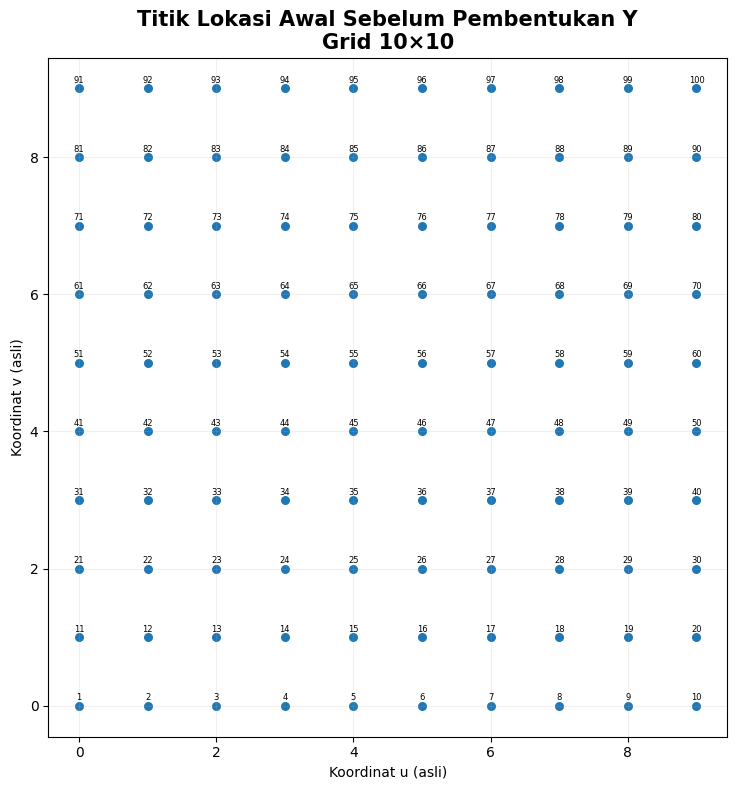

✅ B. Z(s) SELESAI


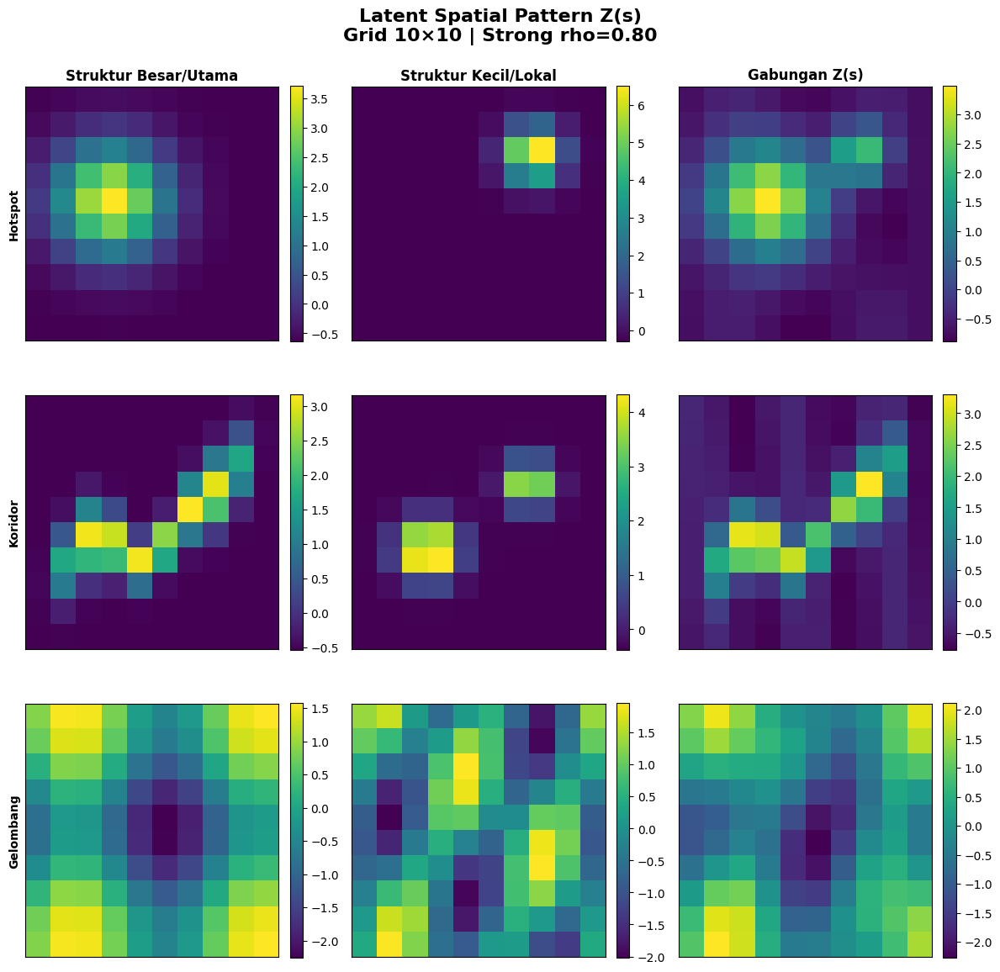


DIAGNOSTIK GRID 10x10
Beta 1 = 1.9778
Beta 2 = -0.4720
Beta 3 = 1.3086

Simpangan baku kontribusi:
X1 kuadratik = 1.9778
X2 kuadratik = 0.4720
X3 sinus     = 1.3086
✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000

CEK MULTIKOLINEARITAS PREDIKTOR UTAMA:


,Grid,Predictor,VIF,Tolerance,Status
0,10x10,X1,1.0634,0.9404,RENDAH
1,10x10,X2,1.0321,0.9689,RENDAH
2,10x10,X3,1.0685,0.9359,RENDAH


Matriks korelasi Pearson:


,X1,X2,X3
X1,1.0000,0.0998,0.2090
X2,0.0998,1.0000,-0.1213
X3,0.2090,-0.1213,1.0000


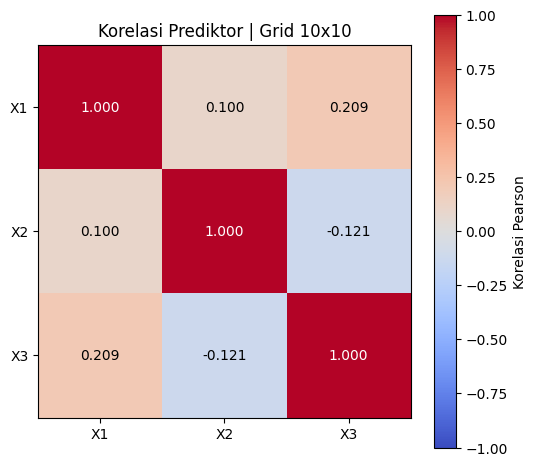

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,10x10,KNN5,5,5.00,5
1,10x10,DISTANCE,3,6.84,8
2,10x10,IDW,7,15.80,20


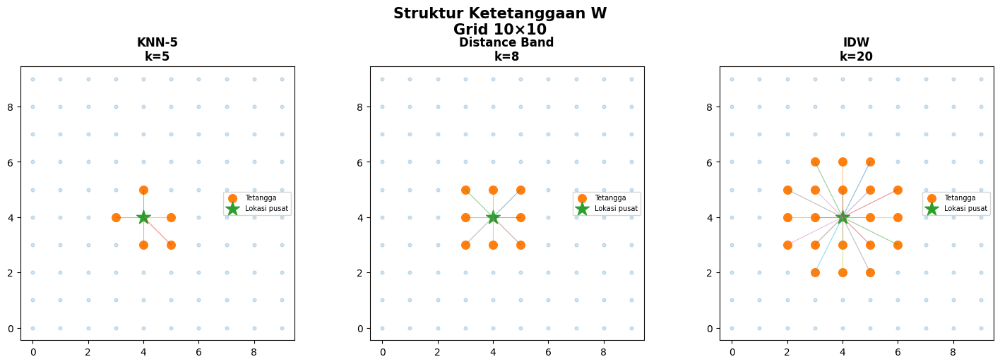

✅ E. 18 SKENARIO Y TWEEDIE SELESAI
   Y minimum = 0.450061
   Proporsi nol = 0.00%


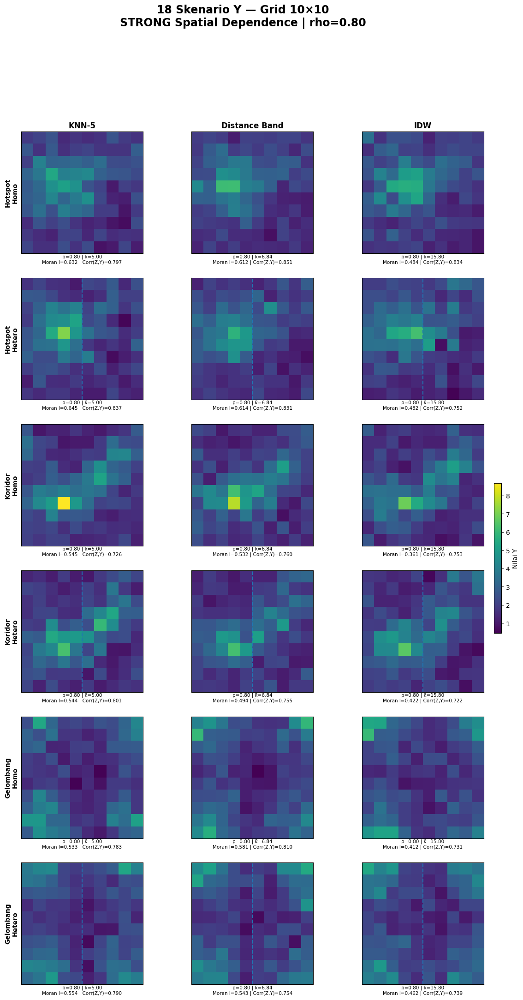

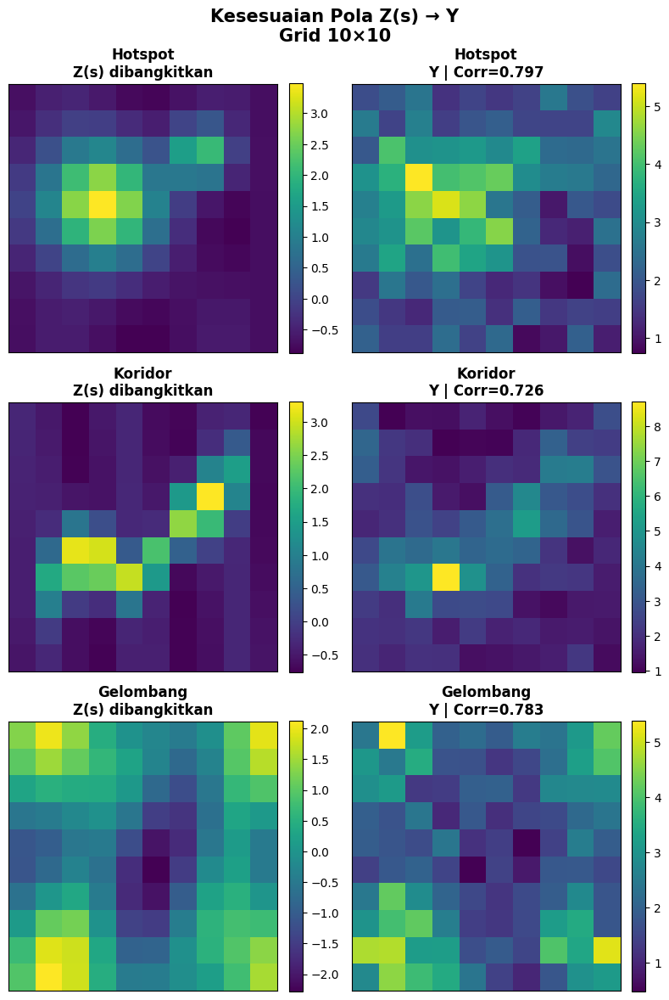

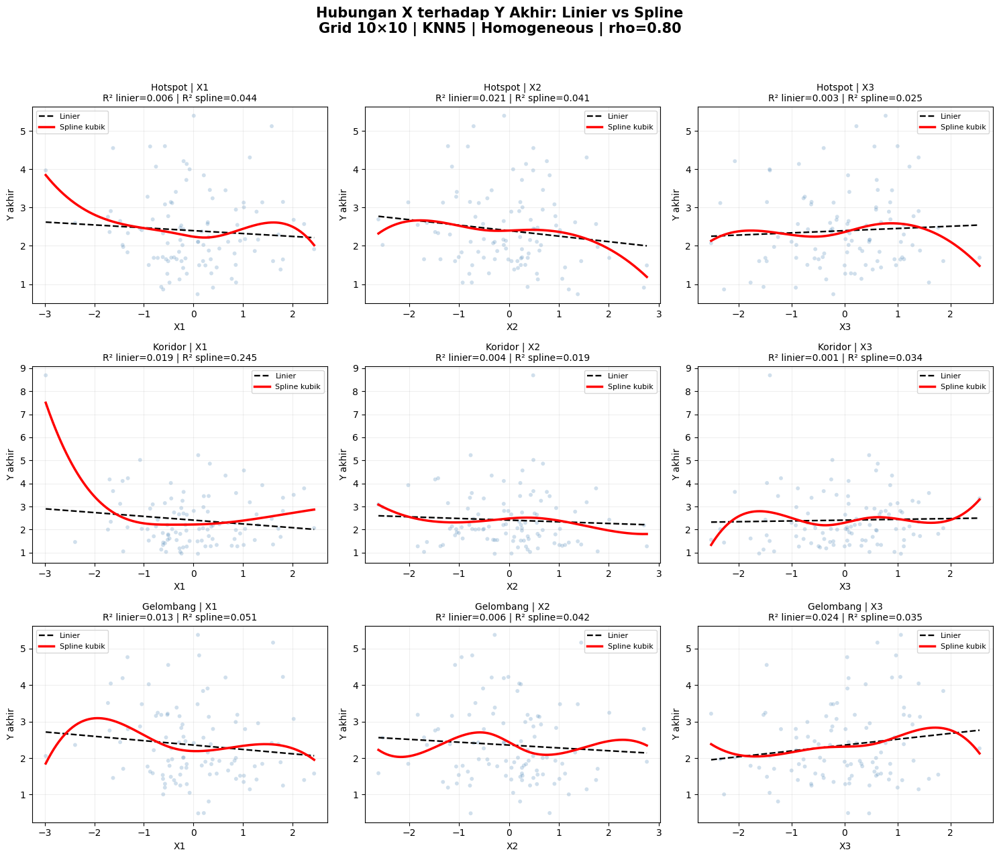

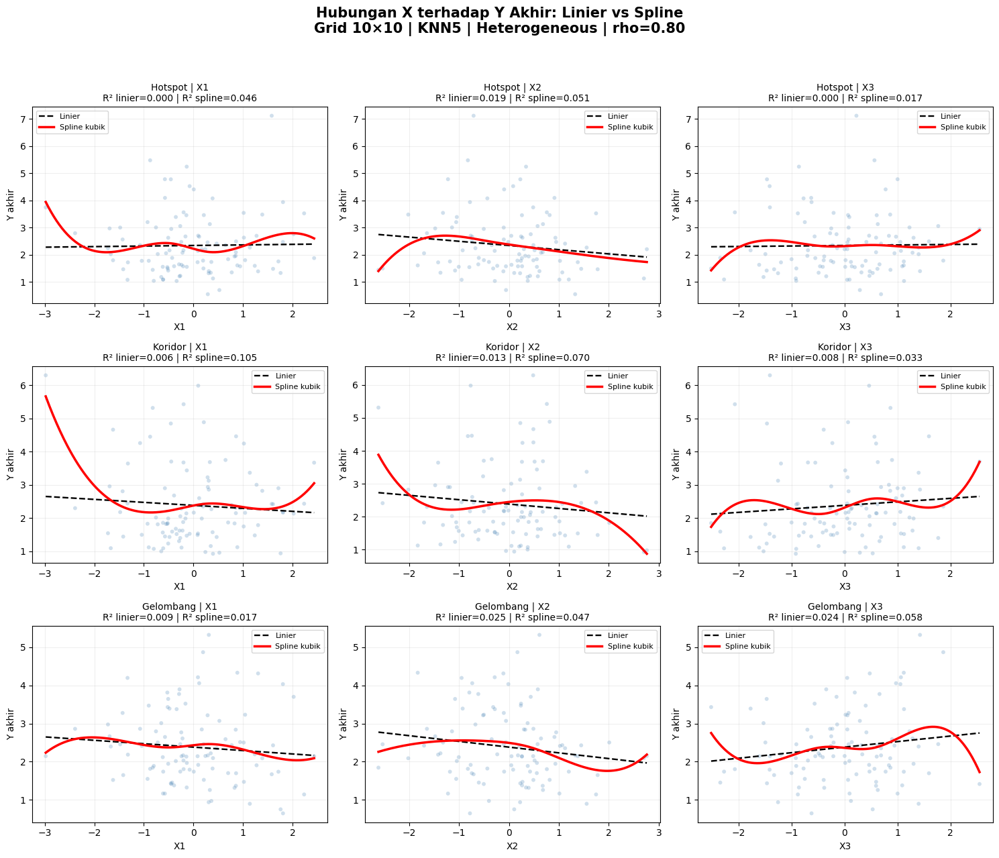

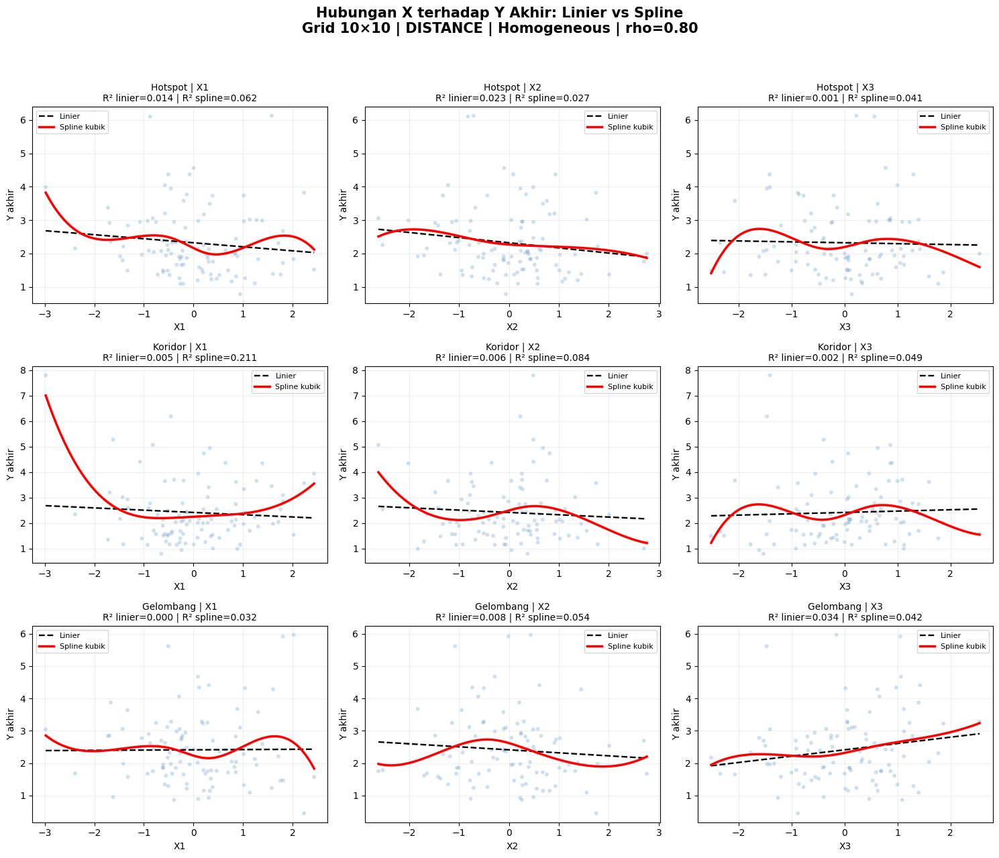

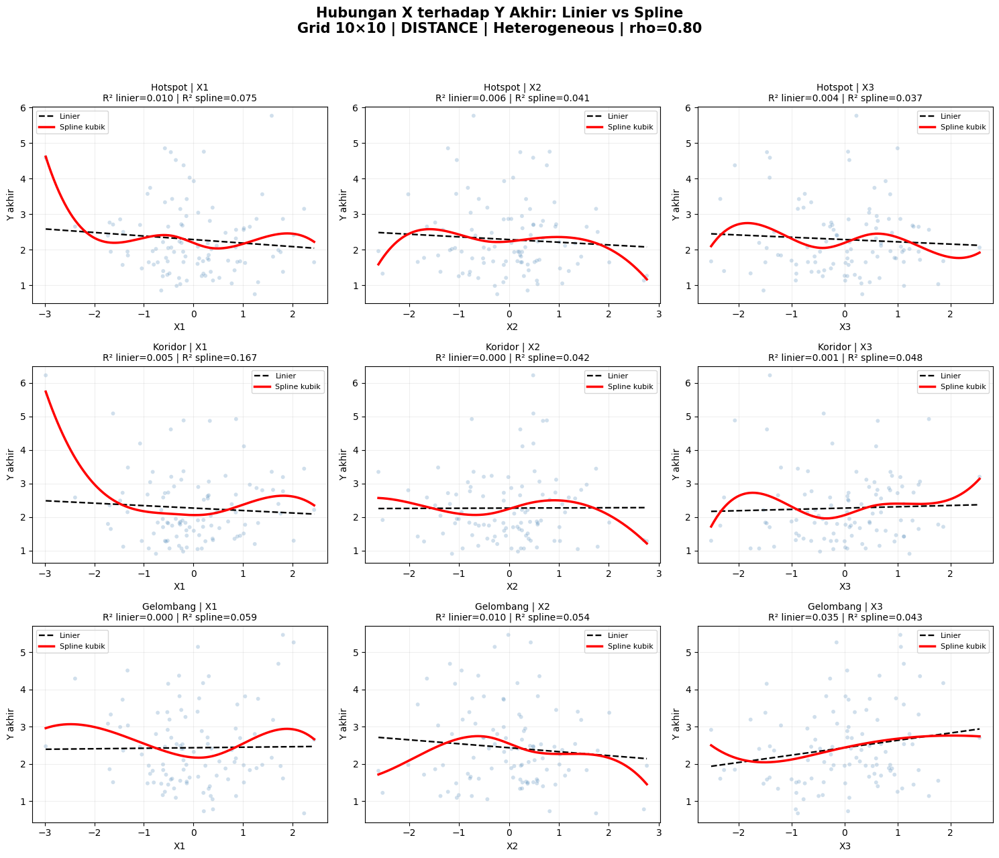

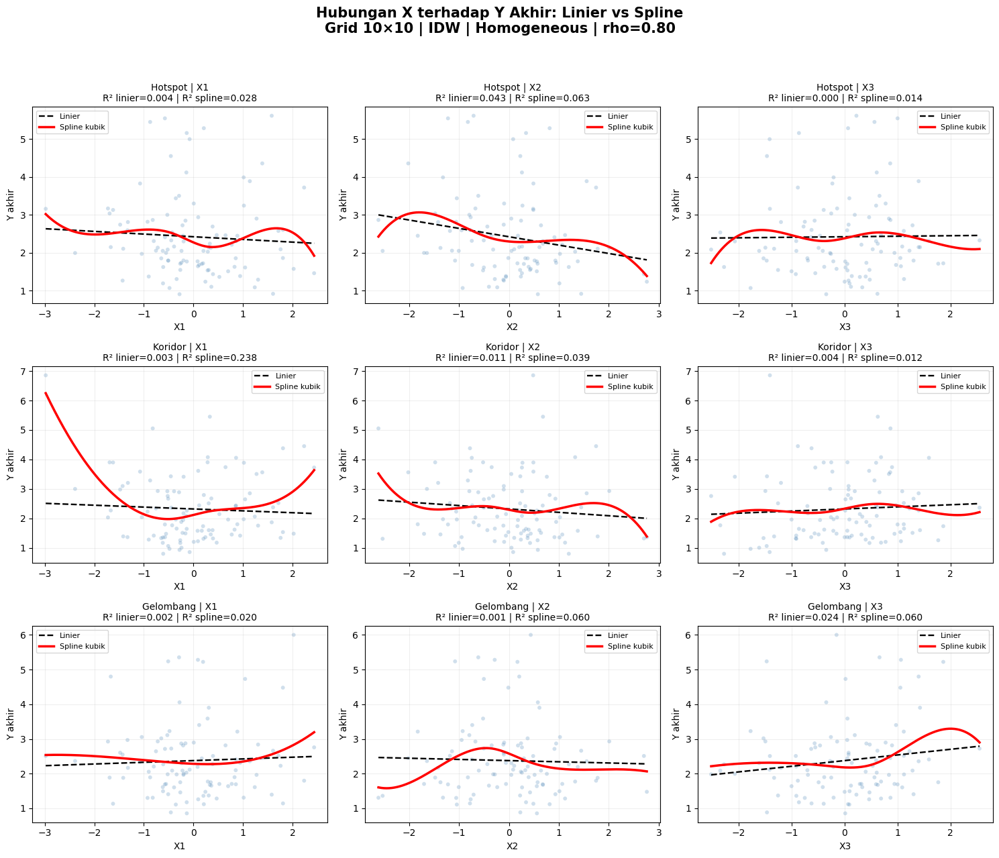

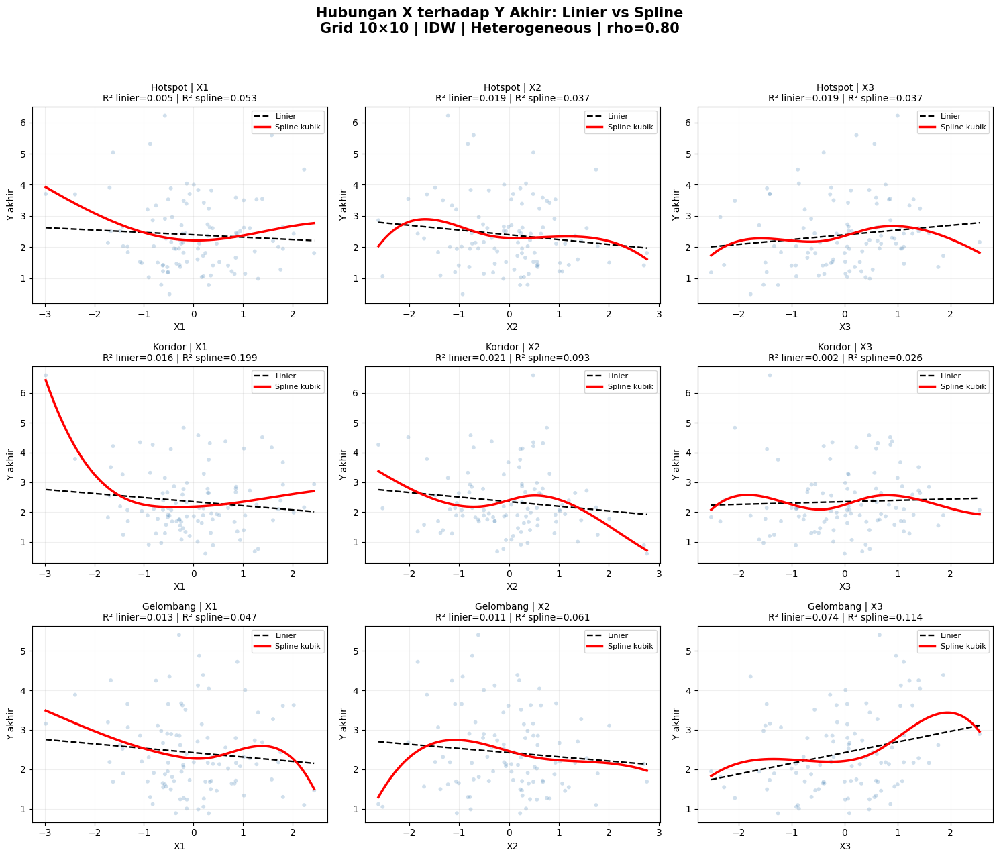

✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI


CEK BREUSCH-PAGAN — GRID 10×10 — STRONG rho=0.80:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue    BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 18.8247      0.000014

In [2]:
# ================================================================
# JALANKAN GRID10
# ================================================================

STRONG_GRID10 = run_strong_grid(
    10
)



STRONG SPATIAL DEPENDENCE — rho=0.80
GRID 20 × 20
N = 400

✅ A. GRID / KOORDINAT BERHASIL


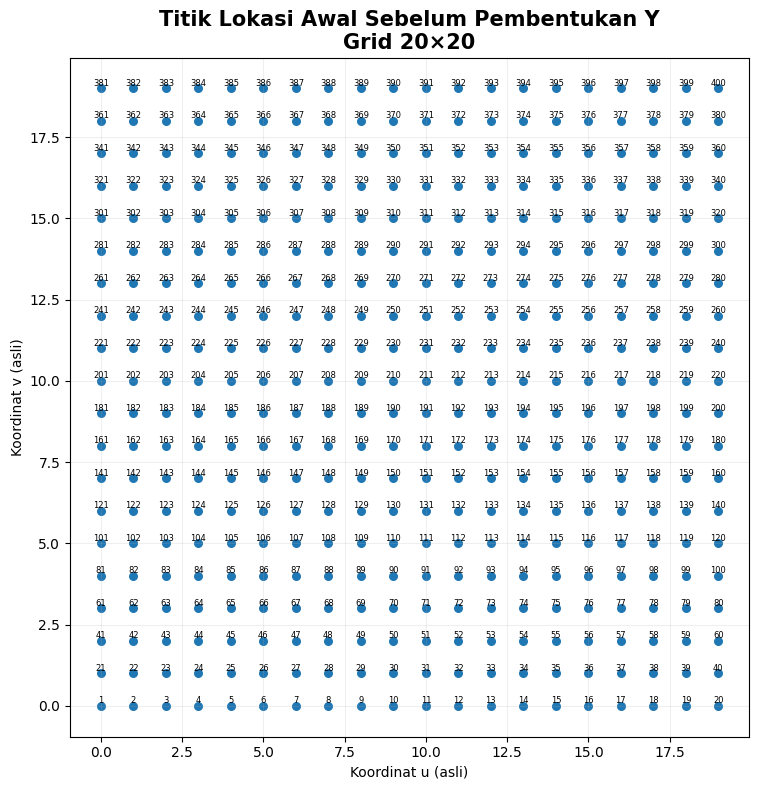

✅ B. Z(s) SELESAI


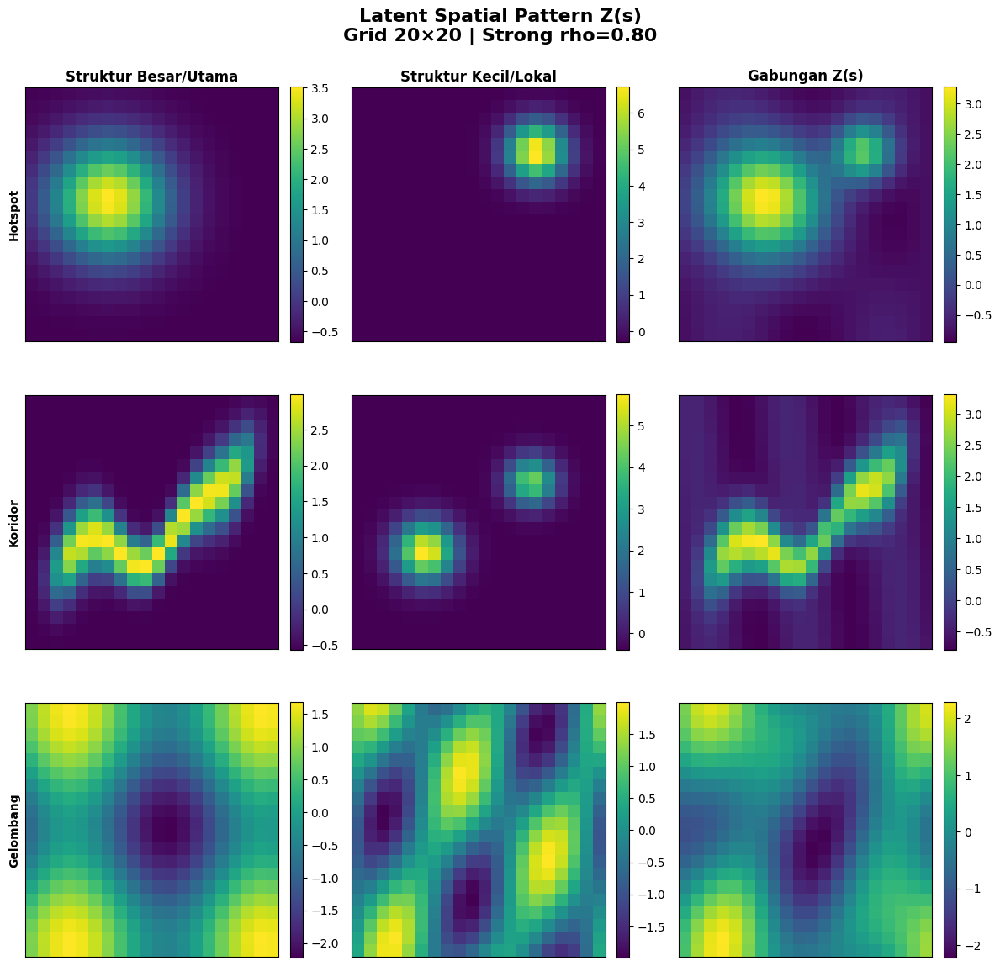


DIAGNOSTIK GRID 20x20
Beta 1 = 1.9778
Beta 2 = -0.4720
Beta 3 = 1.3086

Simpangan baku kontribusi:
X1 kuadratik = 1.9778
X2 kuadratik = 0.4720
X3 sinus     = 1.3086
✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000

CEK MULTIKOLINEARITAS PREDIKTOR UTAMA:


,Grid,Predictor,VIF,Tolerance,Status
0,20x20,X1,1.0026,0.9974,RENDAH
1,20x20,X2,1.0038,0.9962,RENDAH
2,20x20,X3,1.0056,0.9944,RENDAH


Matriks korelasi Pearson:


,X1,X2,X3
X1,1.0000,0.0215,0.0474
X2,0.0215,1.0000,0.0588
X3,0.0474,0.0588,1.0000


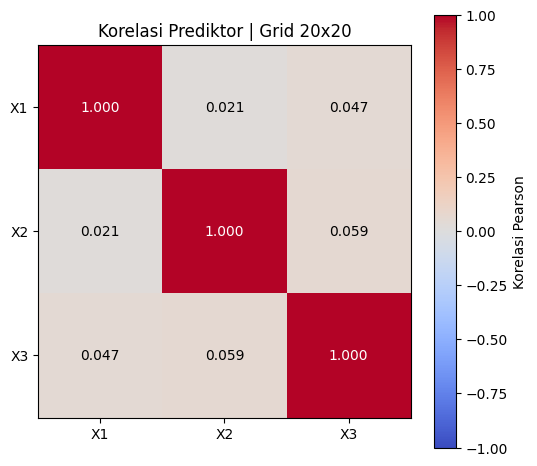

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,20x20,KNN5,5,5.00,5
1,20x20,DISTANCE,3,7.41,8
2,20x20,IDW,7,17.85,20


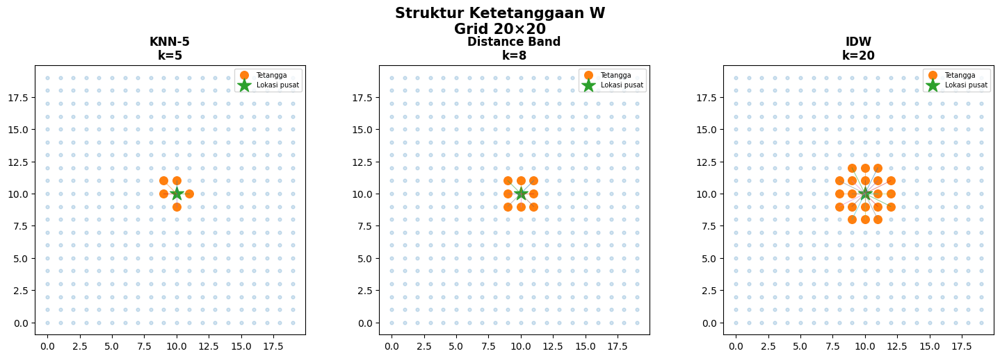

✅ E. 18 SKENARIO Y TWEEDIE SELESAI
   Y minimum = 0.392522
   Proporsi nol = 0.00%


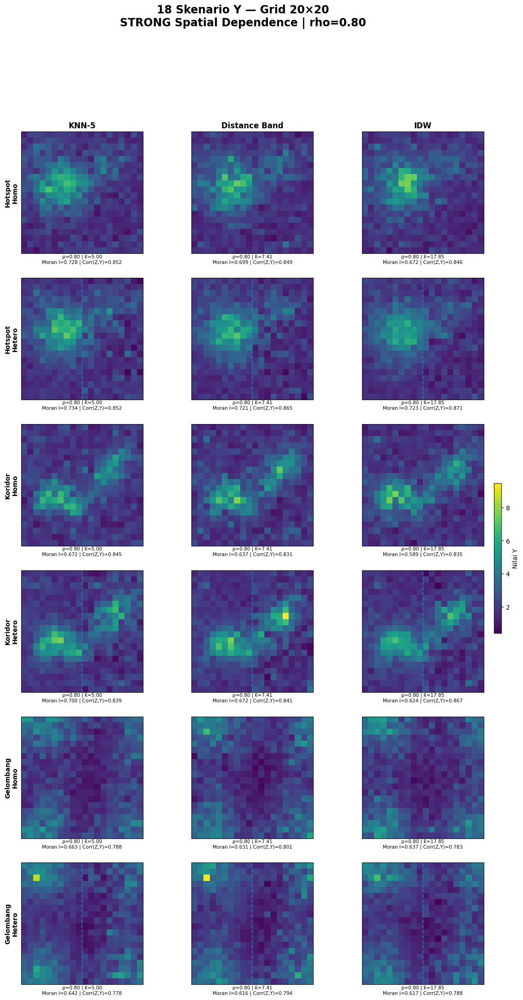

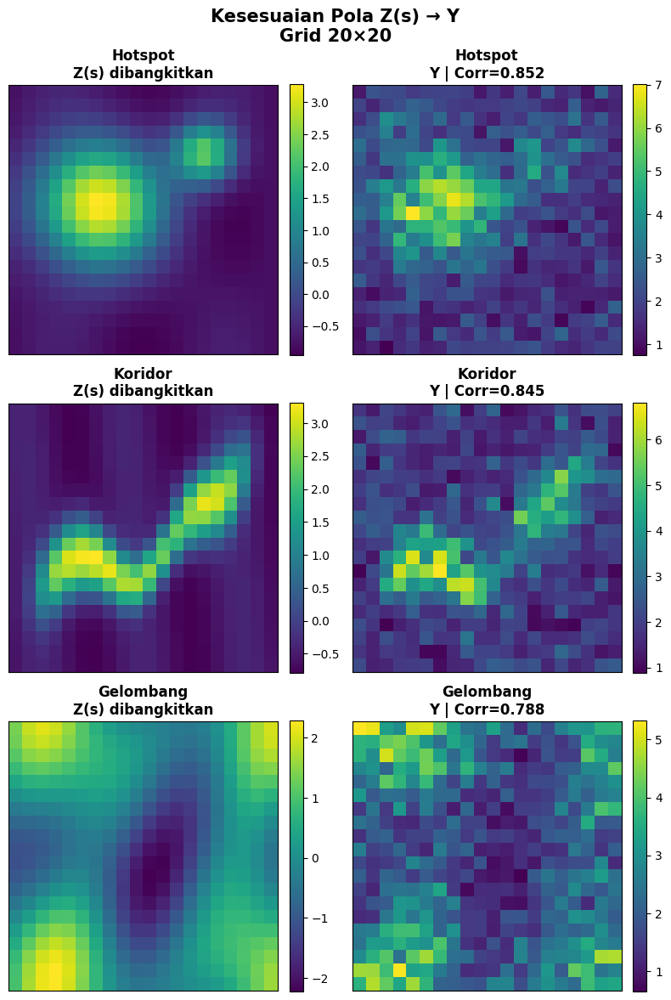

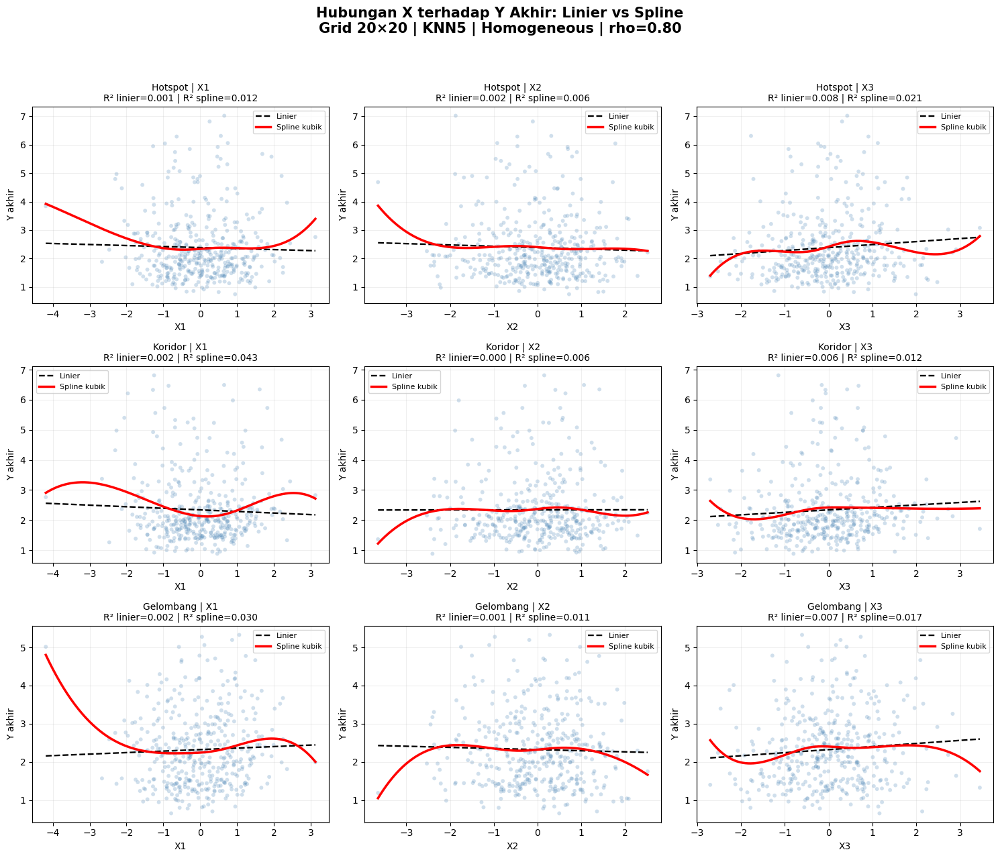

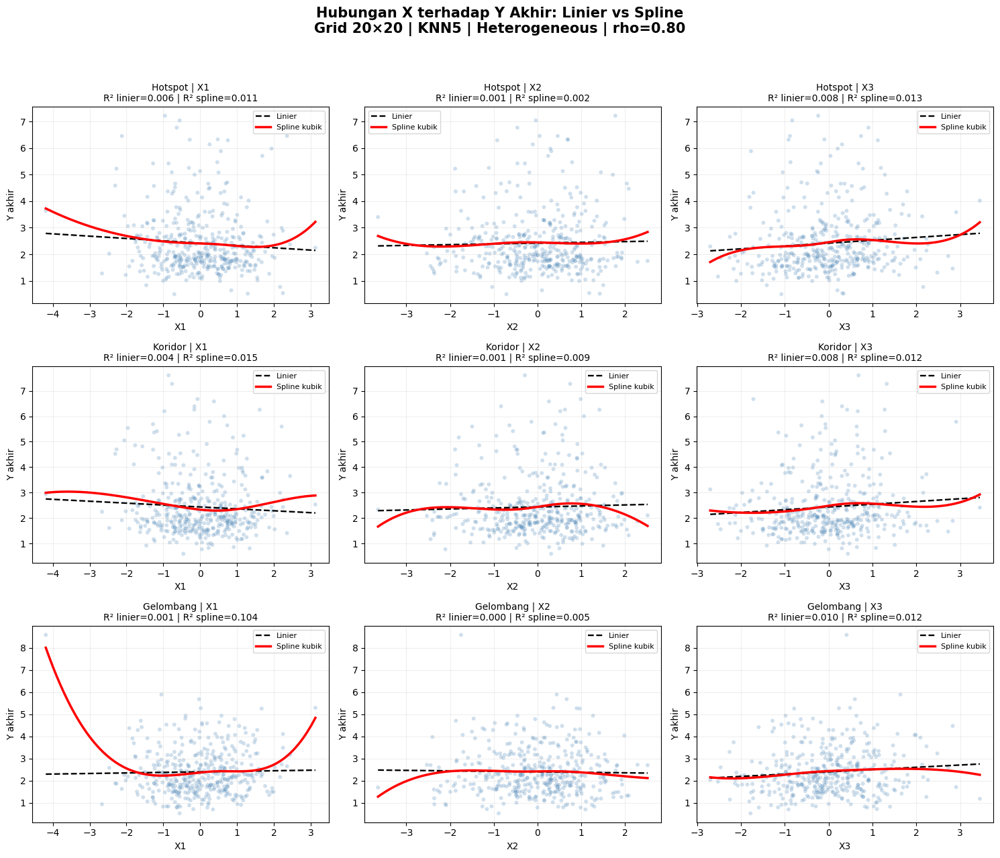

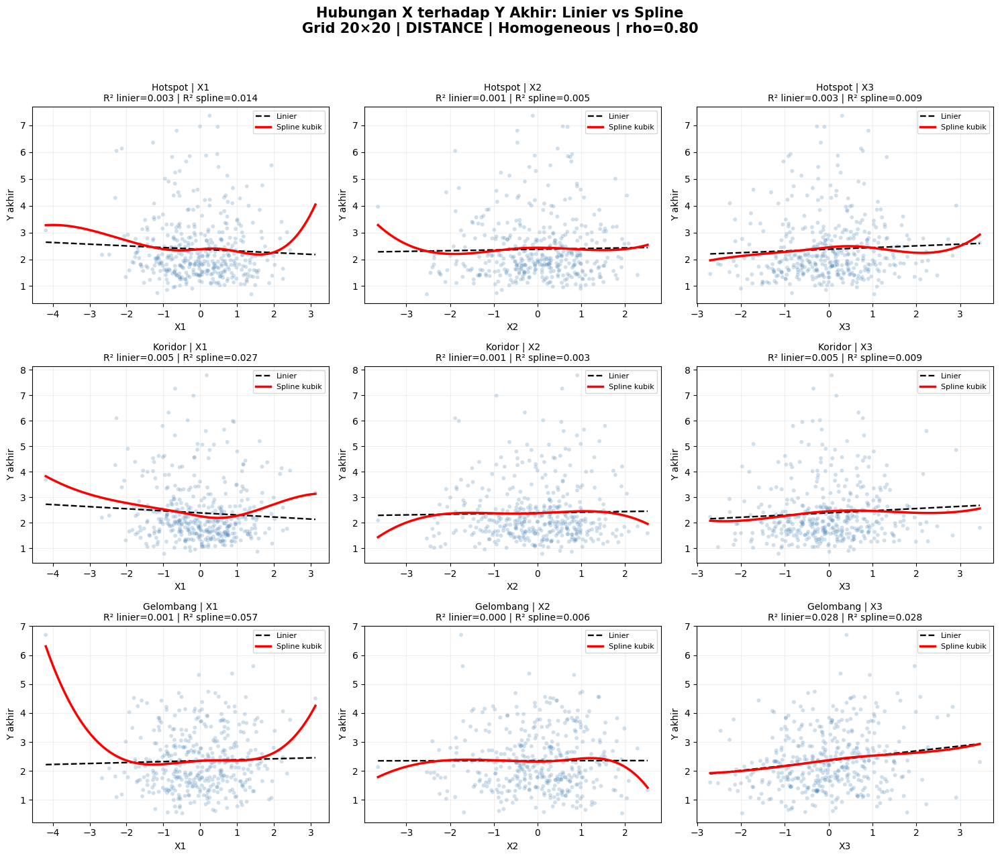

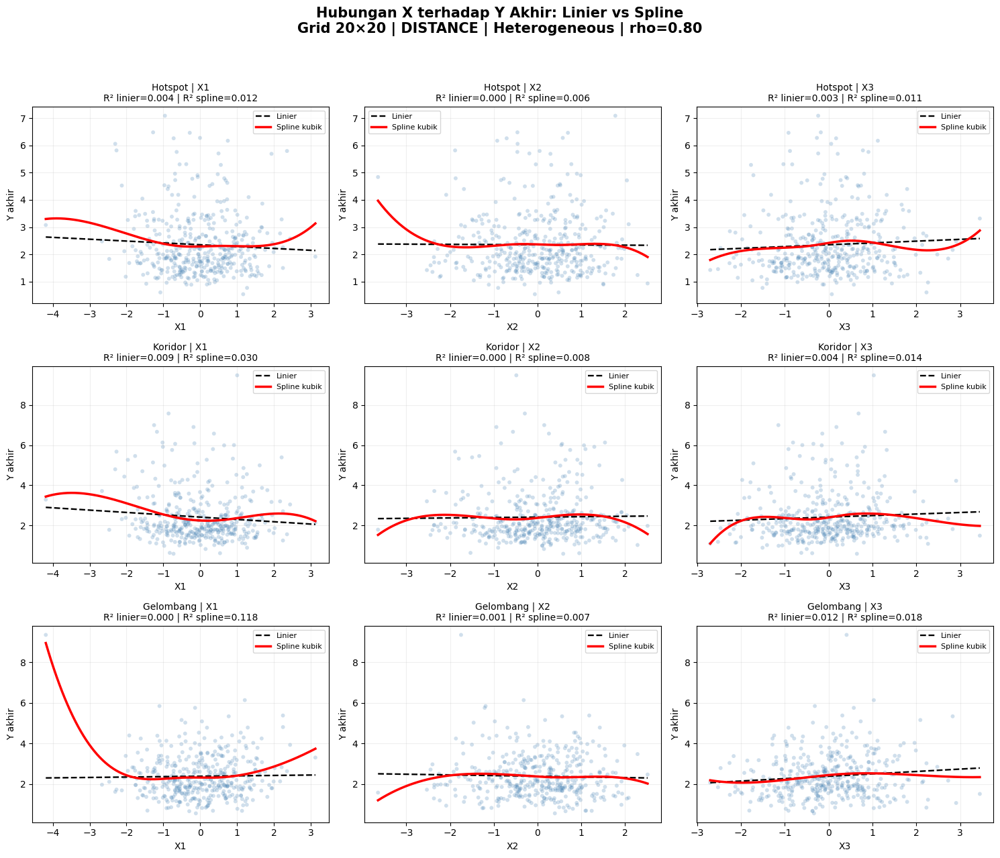

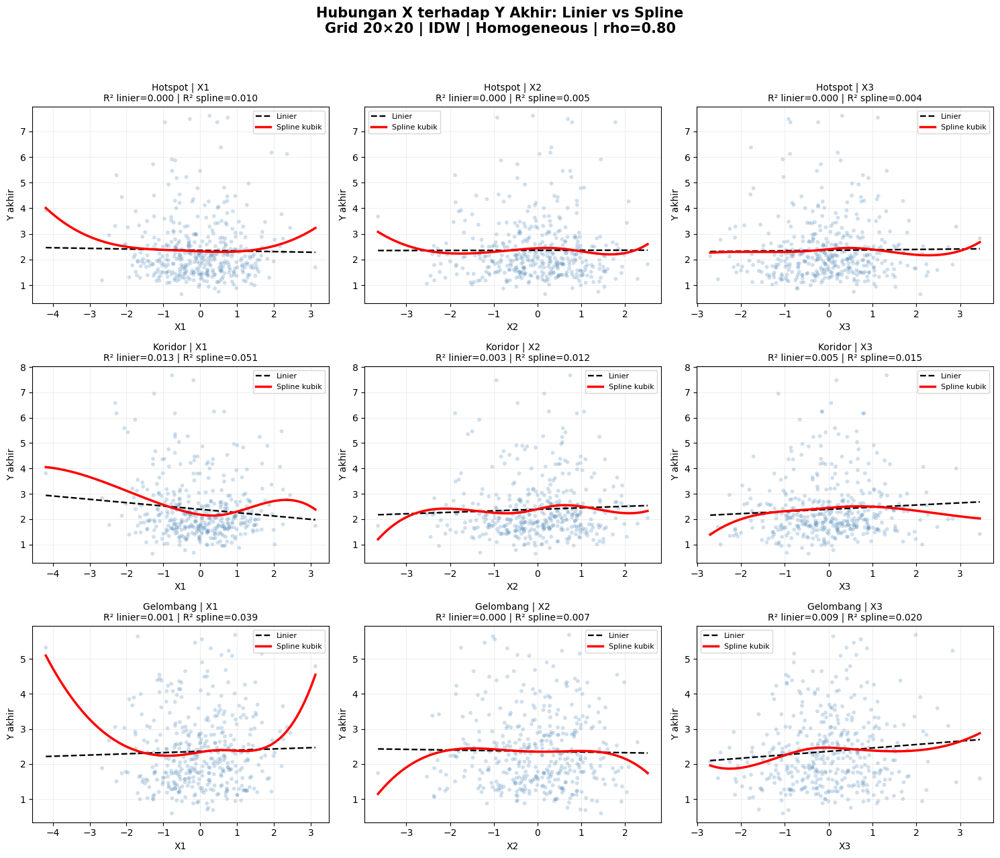

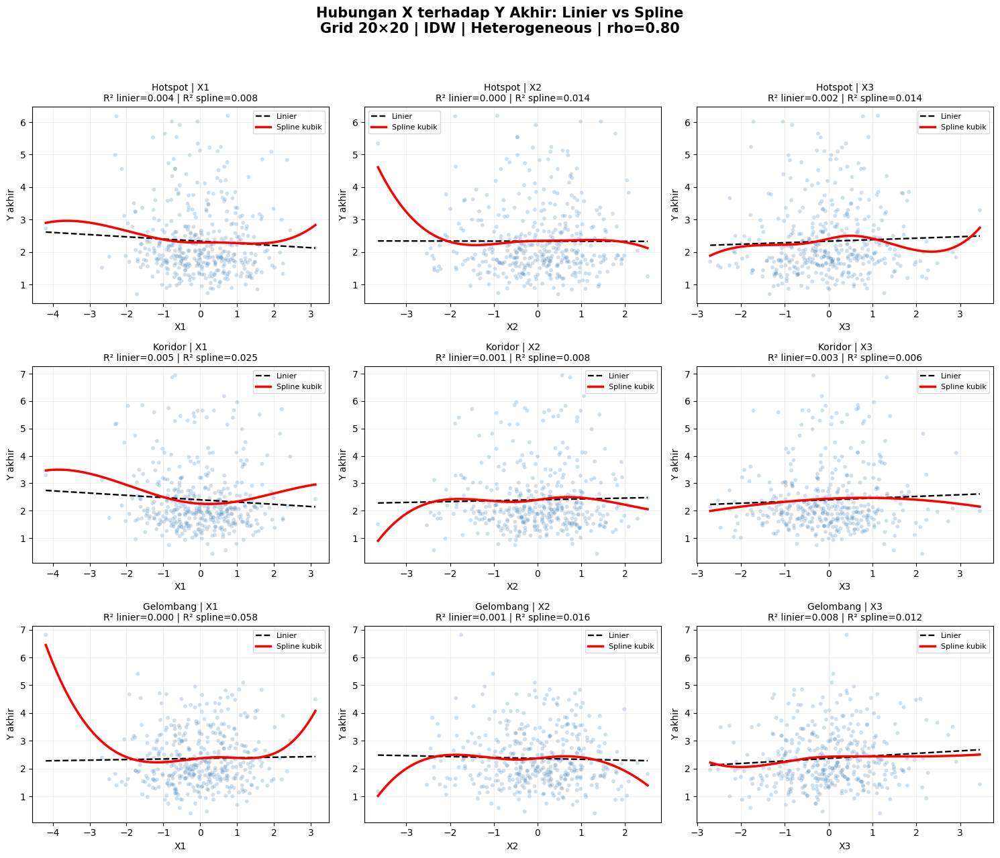

✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI


CEK BREUSCH-PAGAN — GRID 20×20 — STRONG rho=0.80:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue    BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 50.3429      0.000000

In [3]:
# ================================================================
# STRONG rho = 0.80
# GRID 20×20
# ================================================================

STRONG_GRID20 = run_strong_grid(
    20
)



STRONG SPATIAL DEPENDENCE — rho=0.80
GRID 30 × 30
N = 900

✅ A. GRID / KOORDINAT BERHASIL


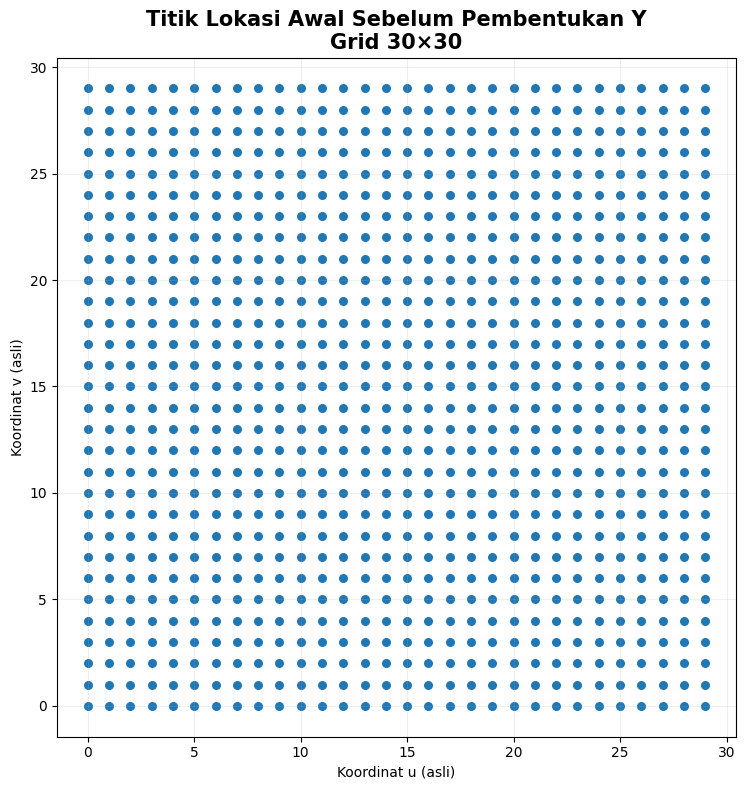

✅ B. Z(s) SELESAI


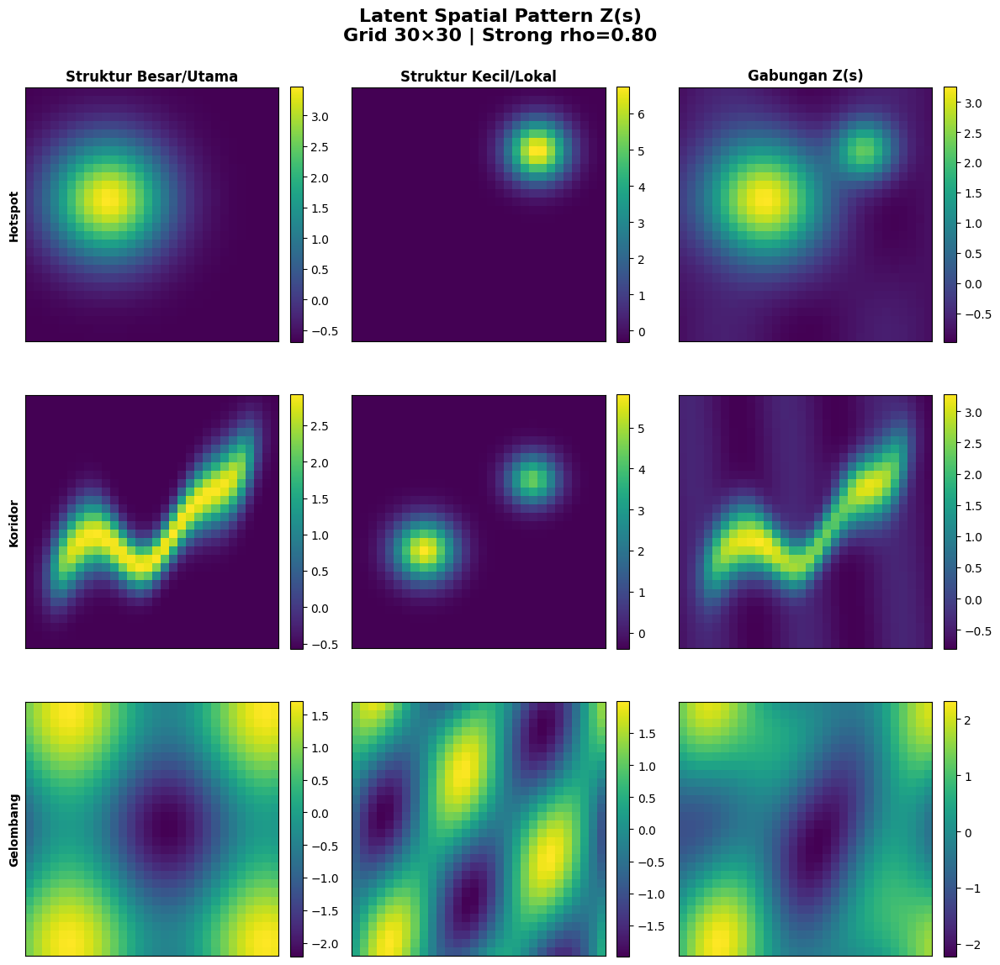


DIAGNOSTIK GRID 30x30
Beta 1 = 1.9778
Beta 2 = -0.4720
Beta 3 = 1.3086

Simpangan baku kontribusi:
X1 kuadratik = 1.9778
X2 kuadratik = 0.4720
X3 sinus     = 1.3086
✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000

CEK MULTIKOLINEARITAS PREDIKTOR UTAMA:


,Grid,Predictor,VIF,Tolerance,Status
0,30x30,X1,1.0030,0.9970,RENDAH
1,30x30,X2,1.0017,0.9983,RENDAH
2,30x30,X3,1.0013,0.9987,RENDAH


Matriks korelasi Pearson:


,X1,X2,X3
X1,1.0000,-0.0416,0.0353
X2,-0.0416,1.0000,0.0023
X3,0.0353,0.0023,1.0000


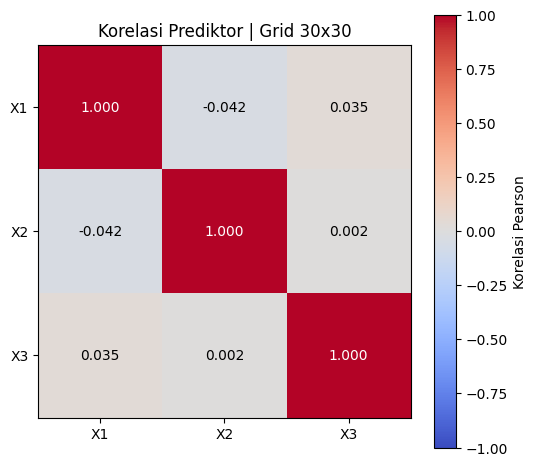

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,30x30,KNN5,5,5.00,5
1,30x30,DISTANCE,3,7.60,8
2,30x30,IDW,7,18.56,20


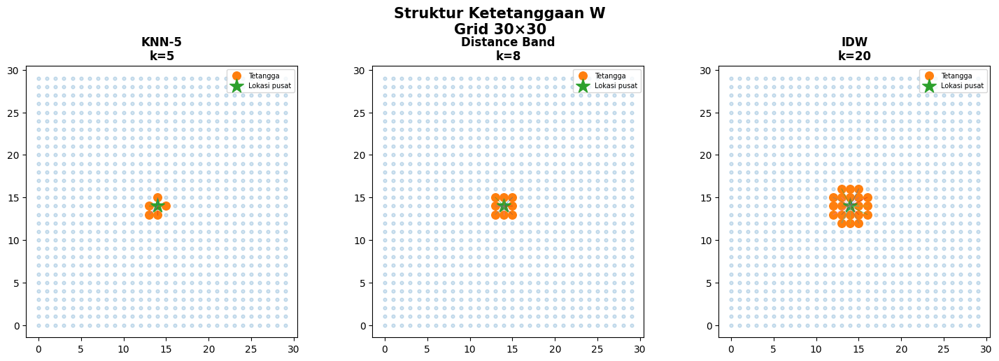

✅ E. 18 SKENARIO Y TWEEDIE SELESAI
   Y minimum = 0.345339
   Proporsi nol = 0.00%


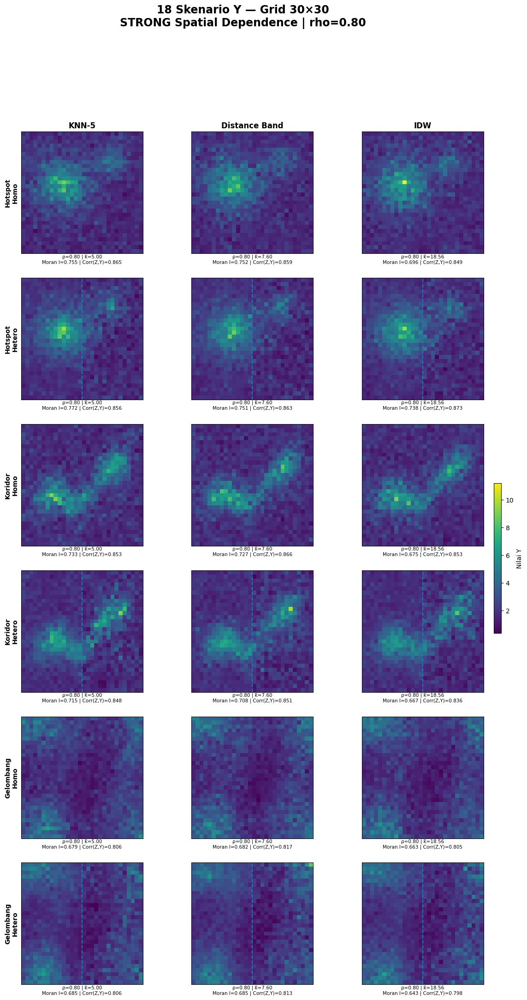

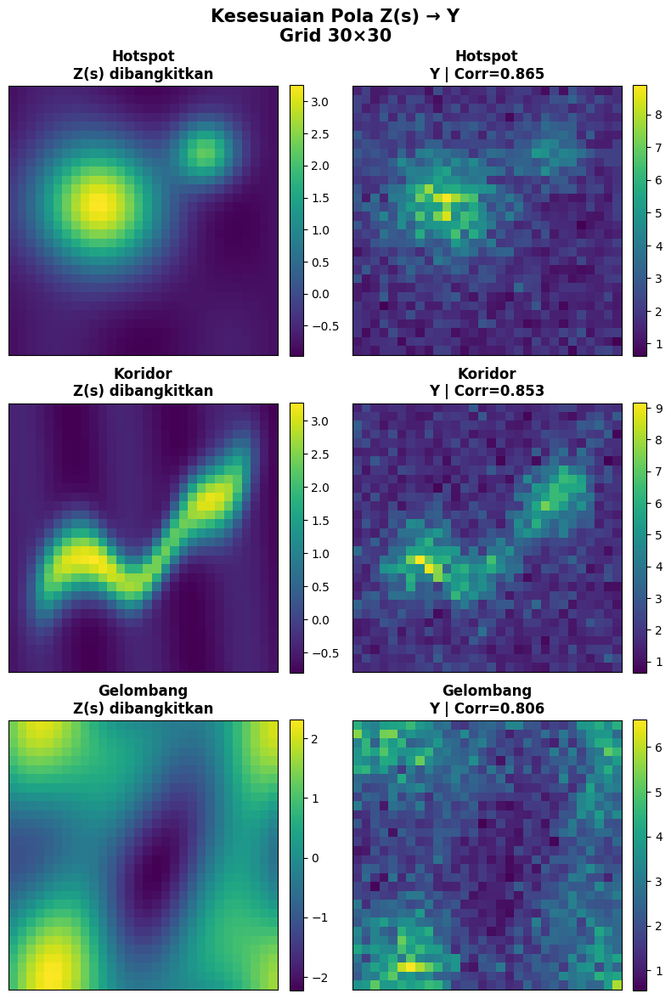

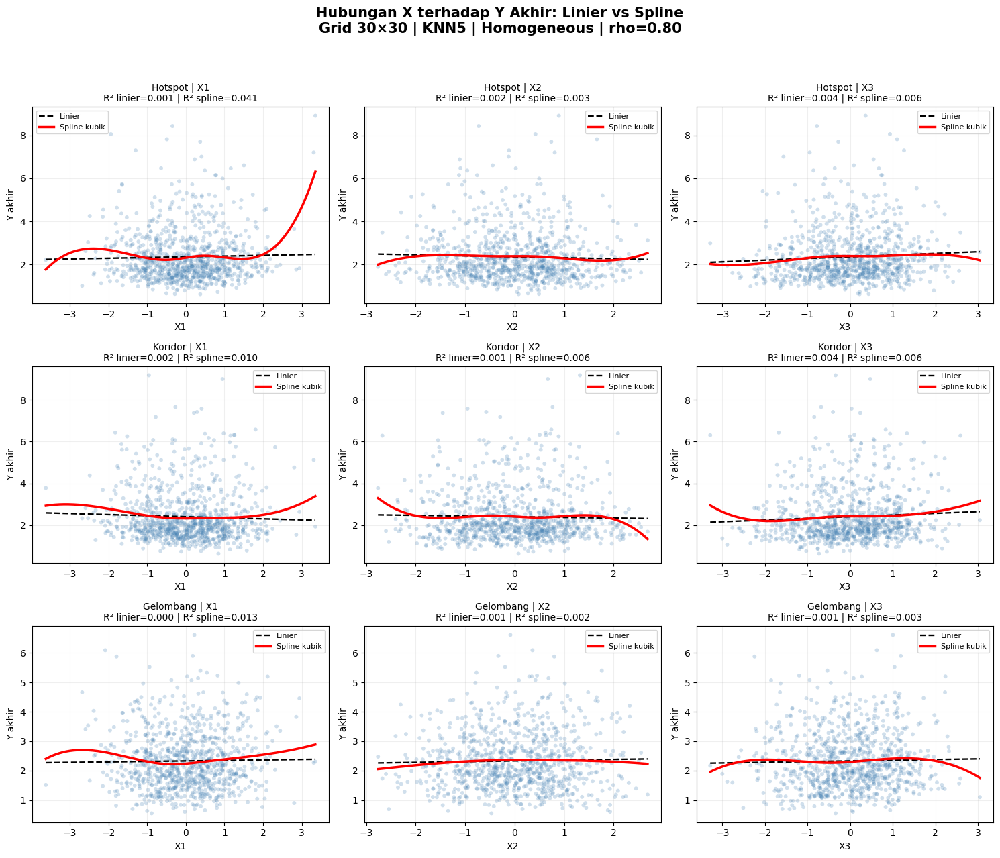

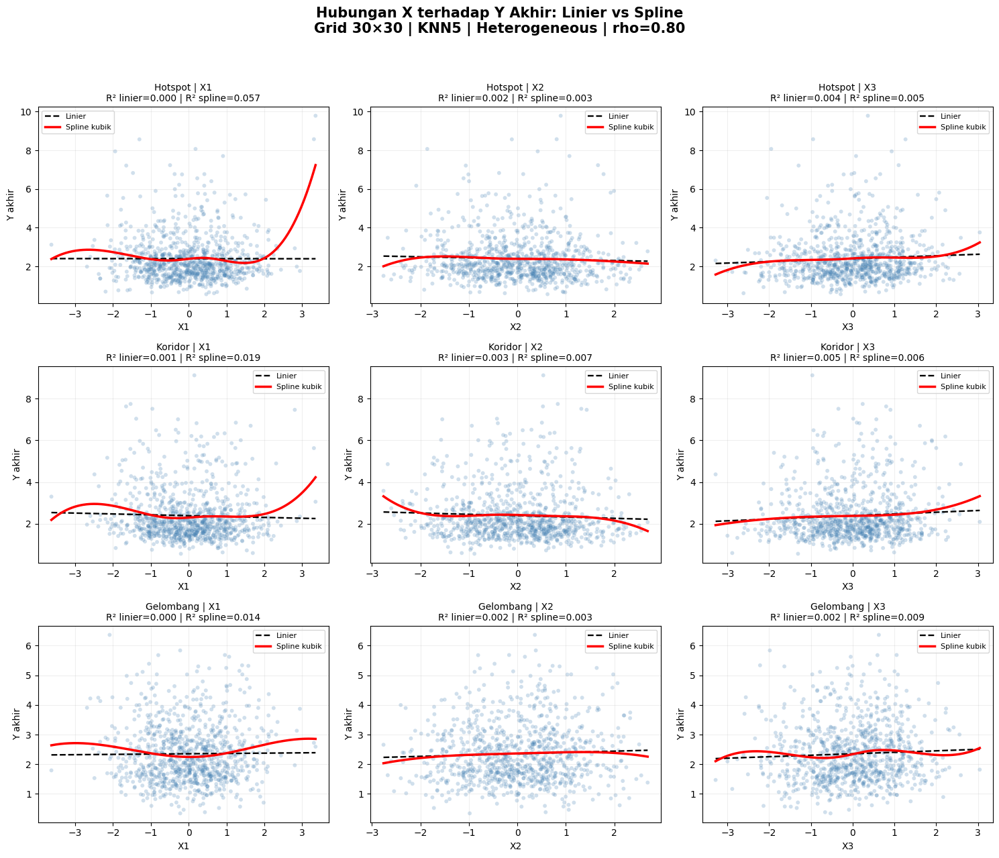

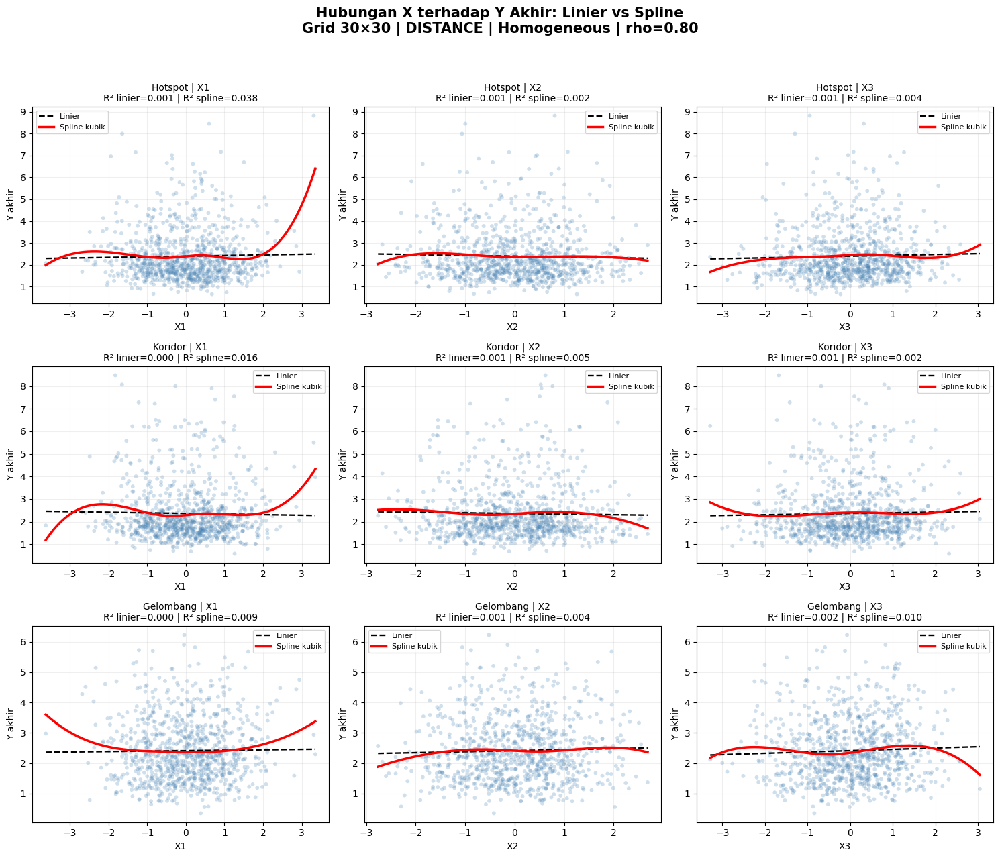

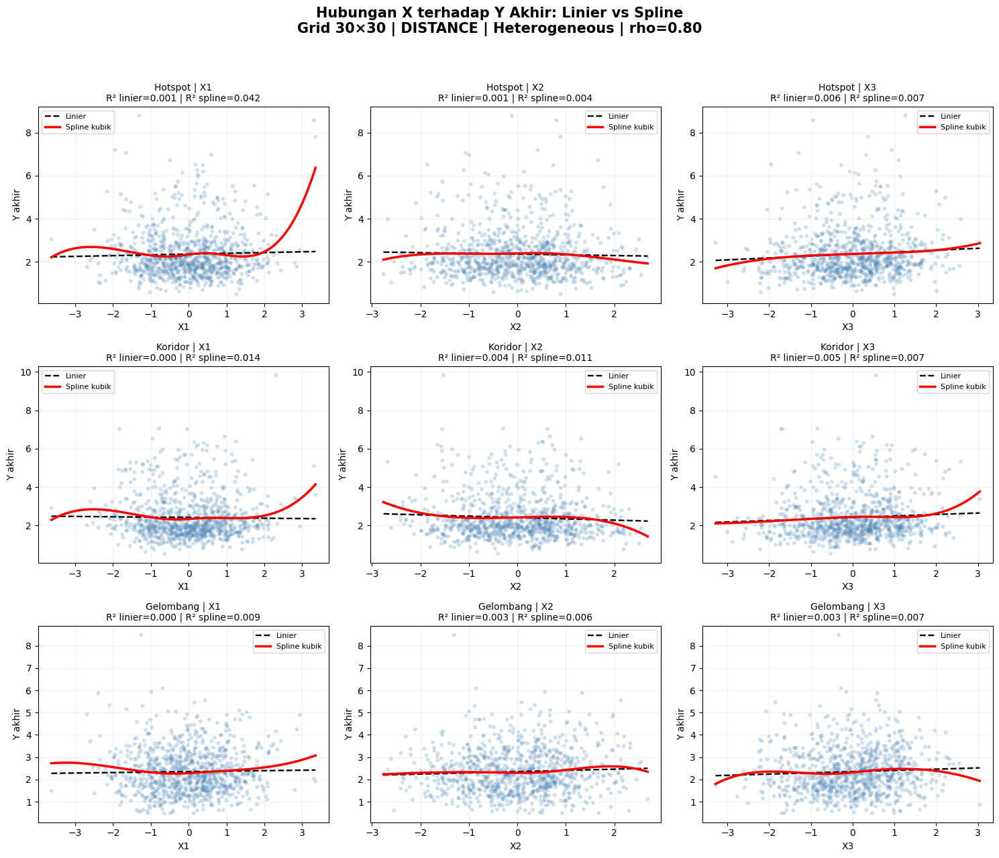

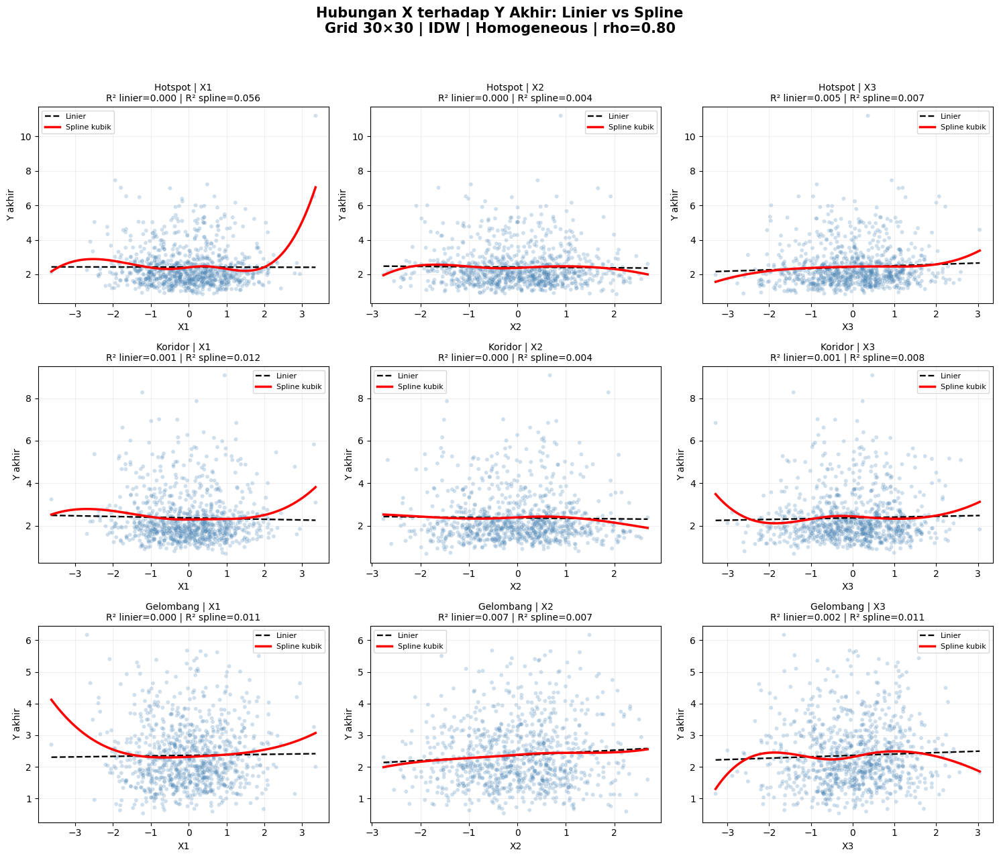

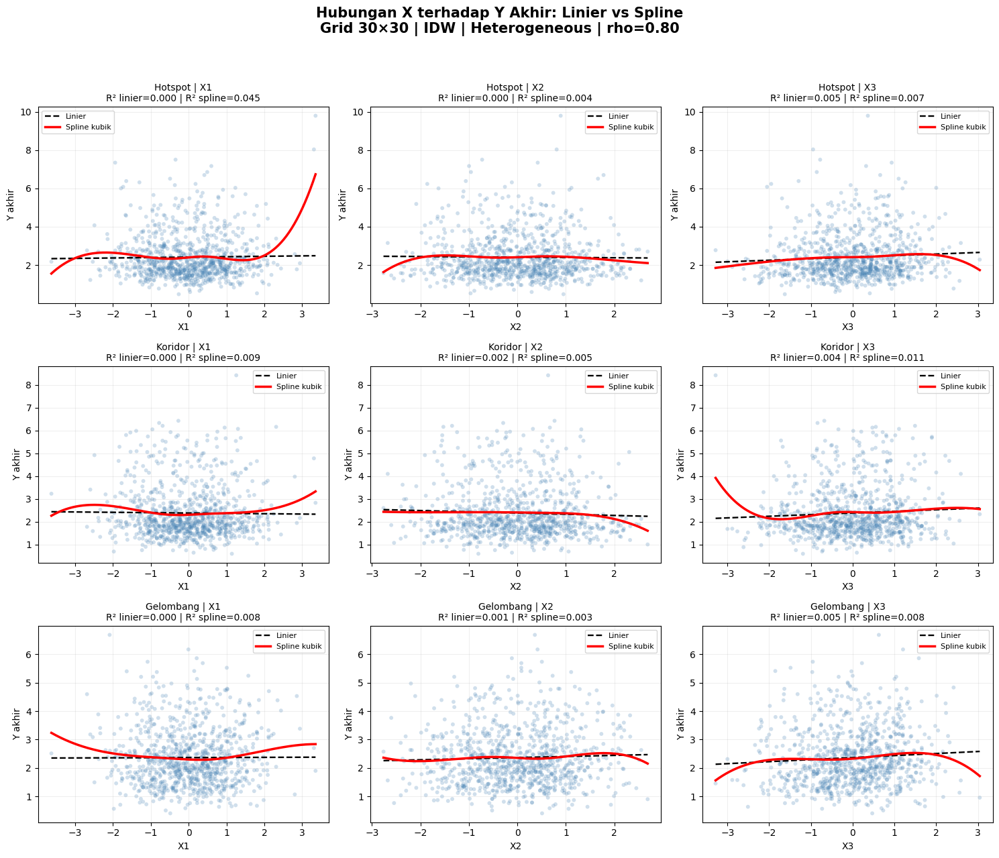

✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI


CEK BREUSCH-PAGAN — GRID 30×30 — STRONG rho=0.80:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 95.4304      0

In [4]:
# ================================================================
# STRONG rho = 0.80
# GRID 30×30
# ================================================================

STRONG_GRID30 = run_strong_grid(
    30
)



STRONG SPATIAL DEPENDENCE — rho=0.80
GRID 40 × 40
N = 1600

✅ A. GRID / KOORDINAT BERHASIL


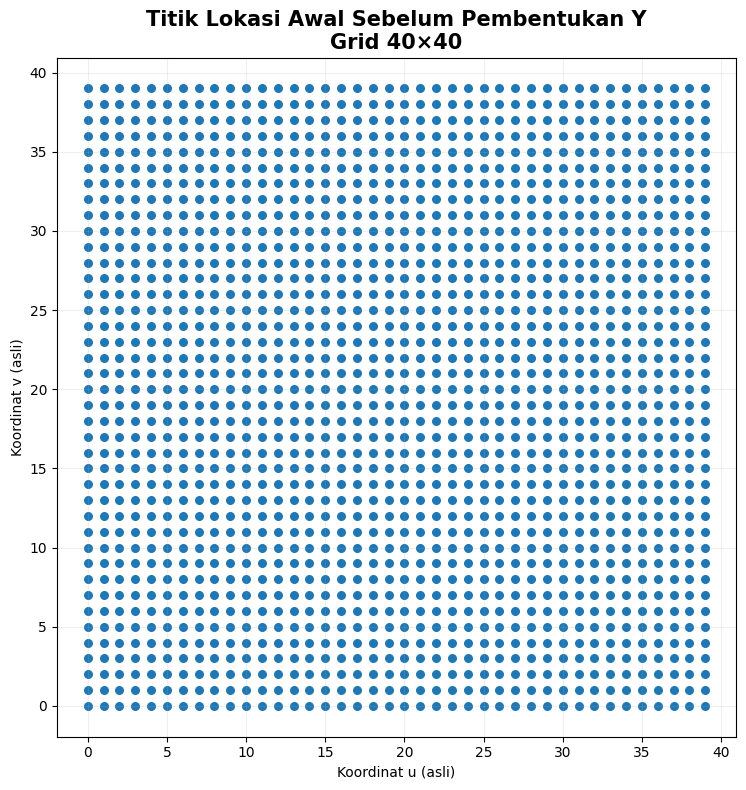

✅ B. Z(s) SELESAI


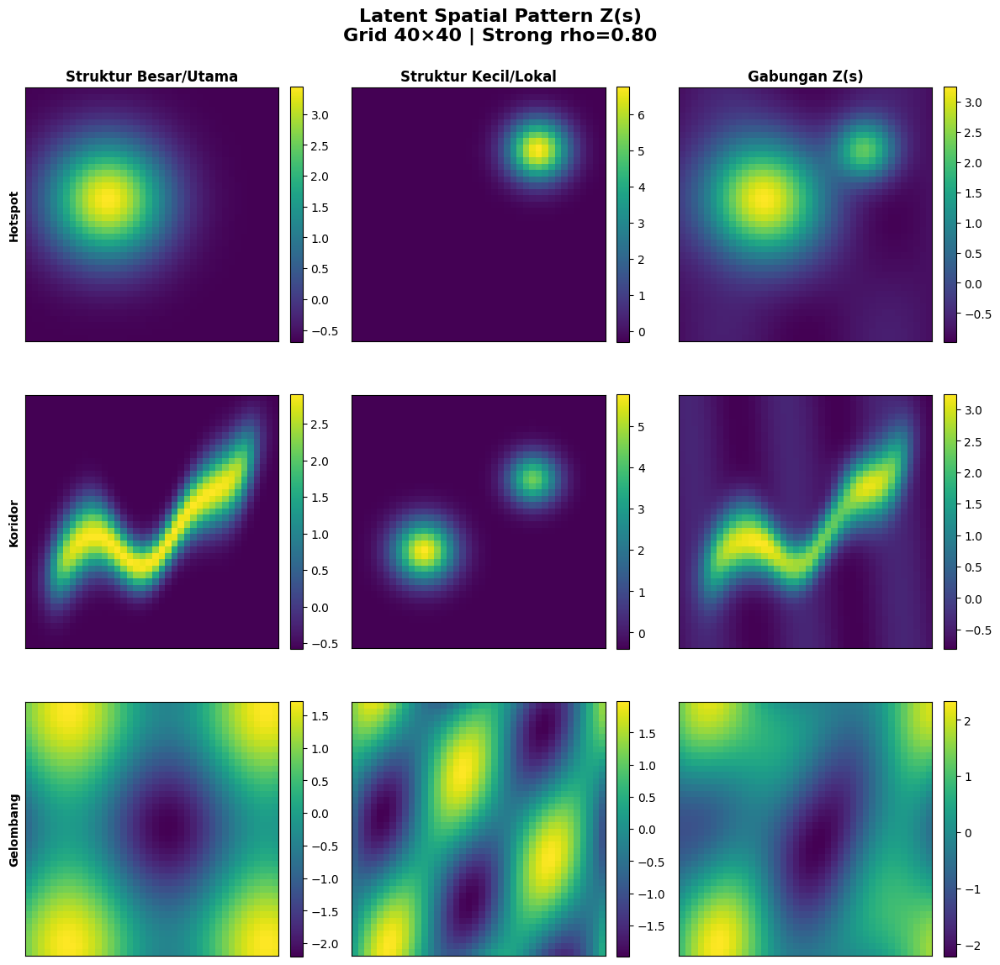


DIAGNOSTIK GRID 40x40
Beta 1 = 1.9778
Beta 2 = -0.4720
Beta 3 = 1.3086

Simpangan baku kontribusi:
X1 kuadratik = 1.9778
X2 kuadratik = 0.4720
X3 sinus     = 1.3086
✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000

CEK MULTIKOLINEARITAS PREDIKTOR UTAMA:


,Grid,Predictor,VIF,Tolerance,Status
0,40x40,X1,1.0002,0.9998,RENDAH
1,40x40,X2,1.0034,0.9966,RENDAH
2,40x40,X3,1.0035,0.9965,RENDAH


Matriks korelasi Pearson:


,X1,X2,X3
X1,1.0000,0.0048,-0.0115
X2,0.0048,1.0000,0.0580
X3,-0.0115,0.0580,1.0000


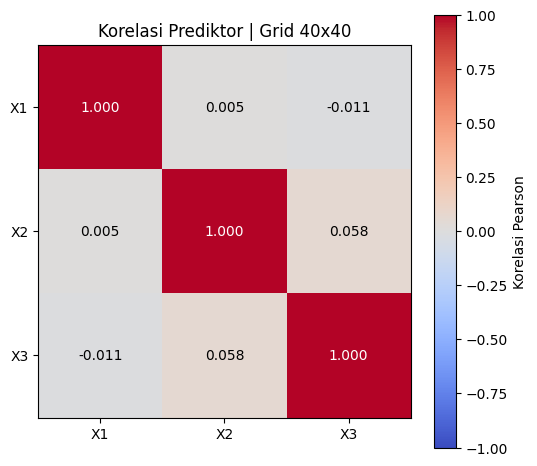

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,40x40,KNN5,5,5.00,5
1,40x40,DISTANCE,3,7.70,8
2,40x40,IDW,7,18.91,20


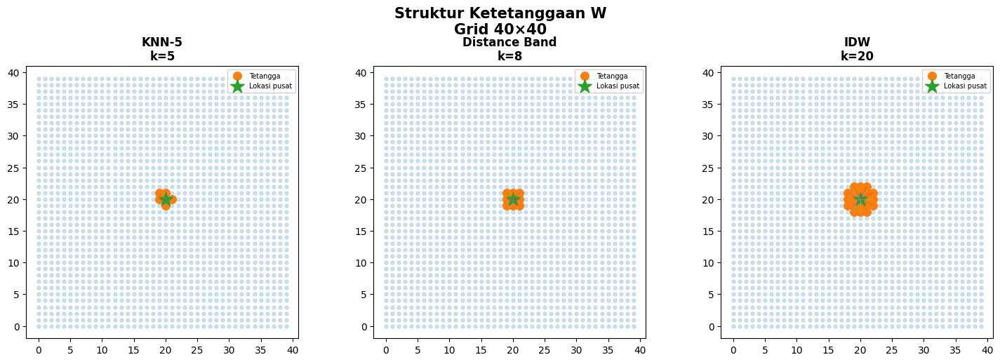

✅ E. 18 SKENARIO Y TWEEDIE SELESAI
   Y minimum = 0.358968
   Proporsi nol = 0.00%


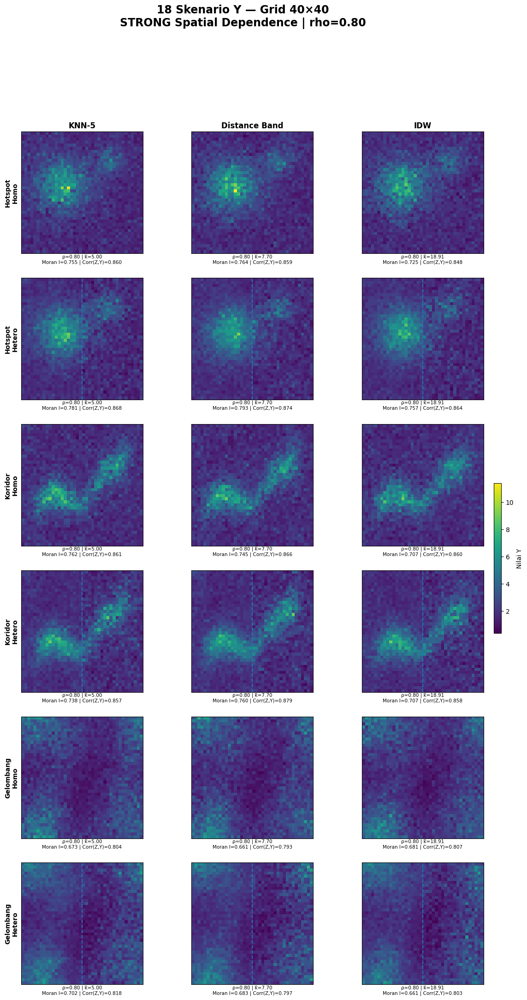

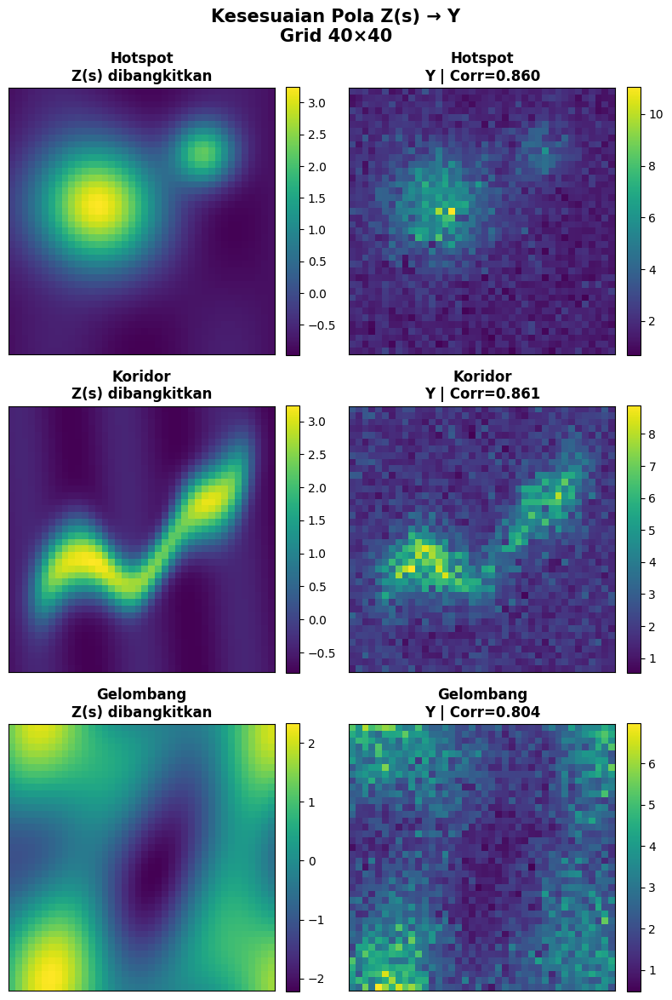

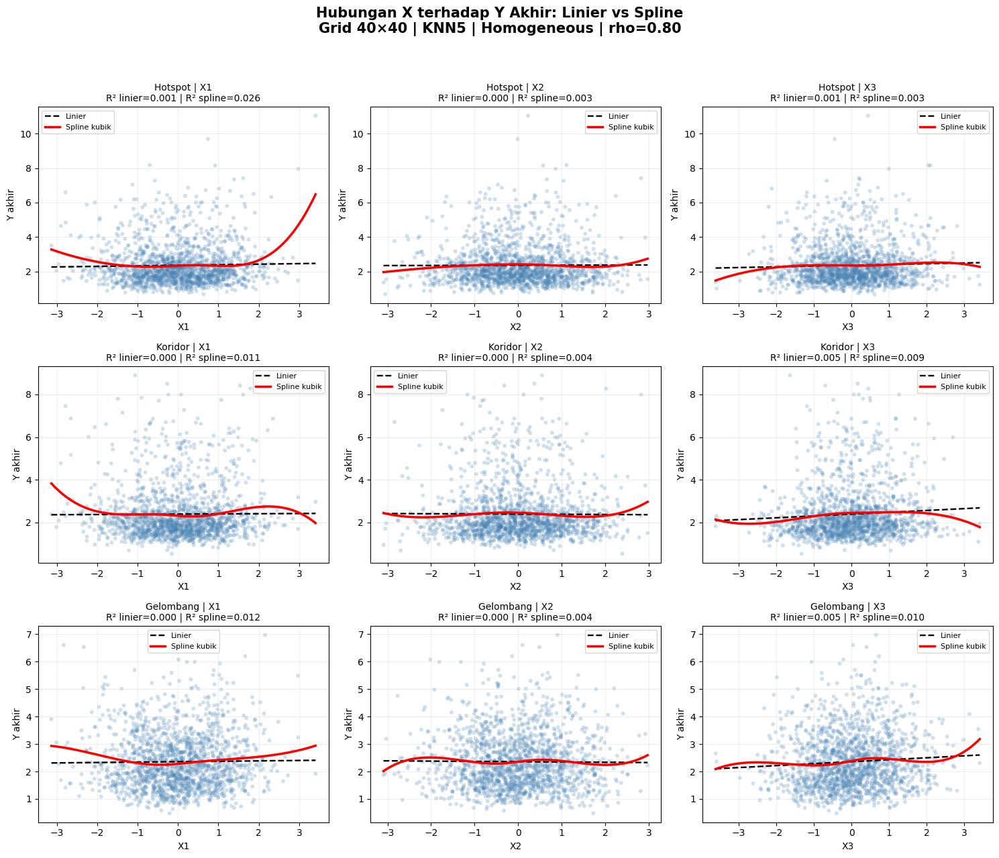

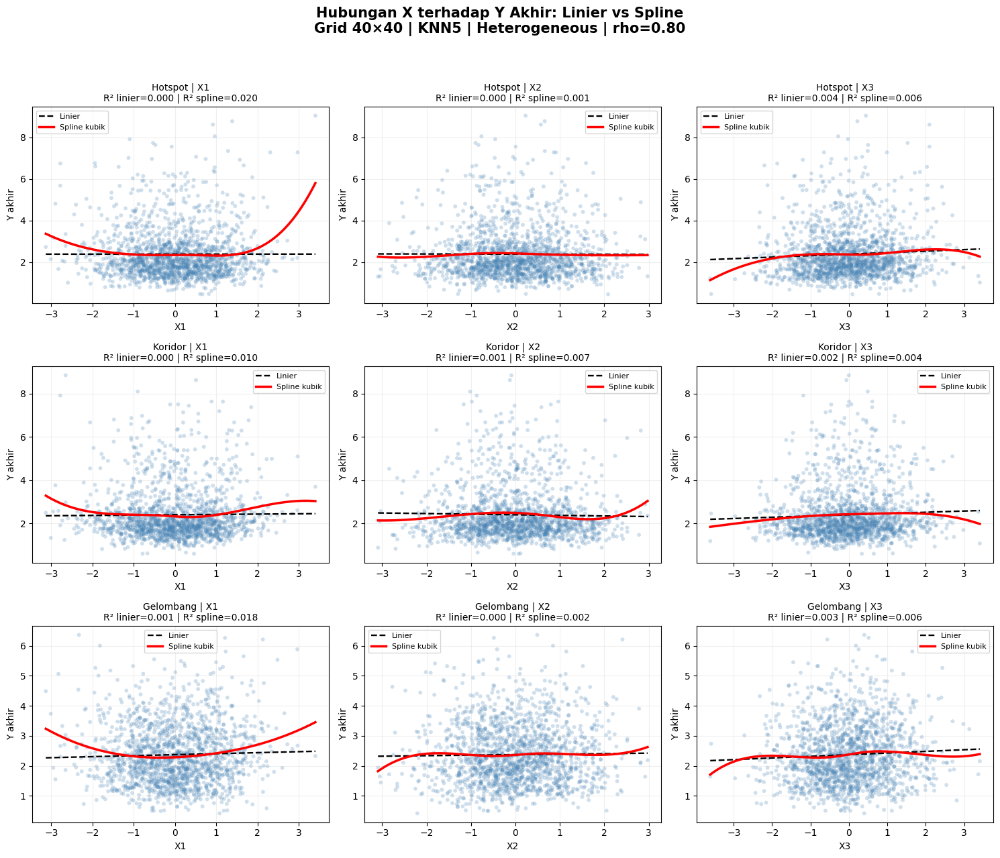

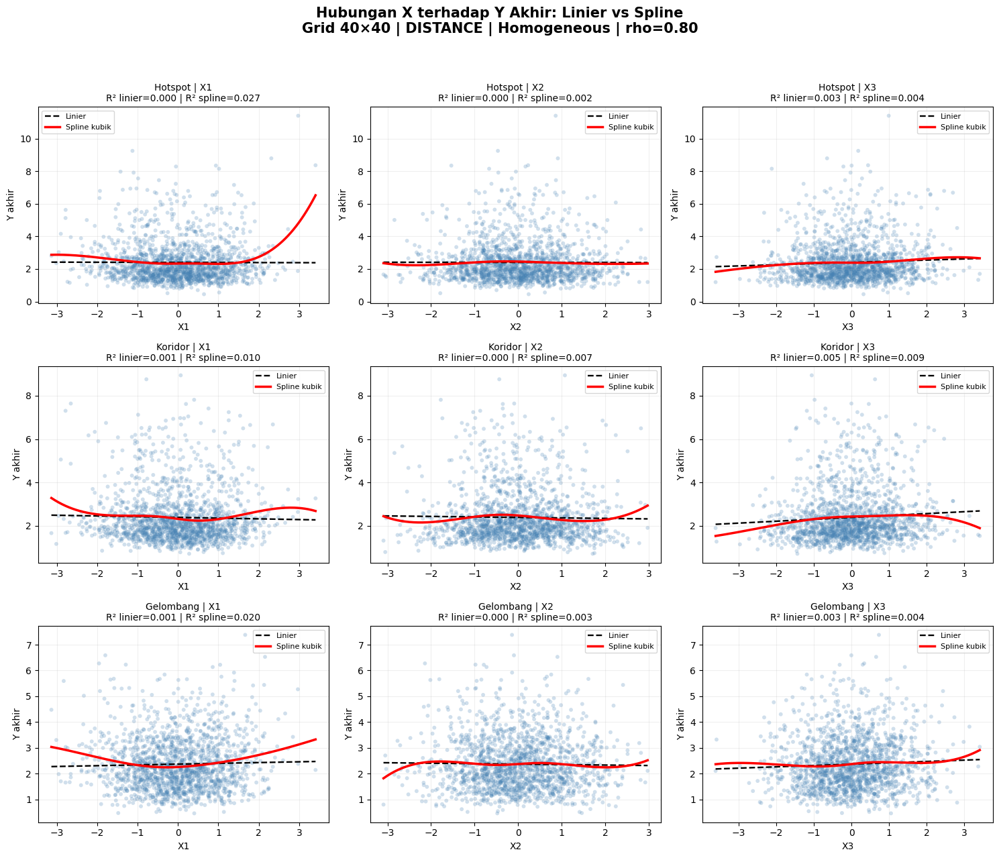

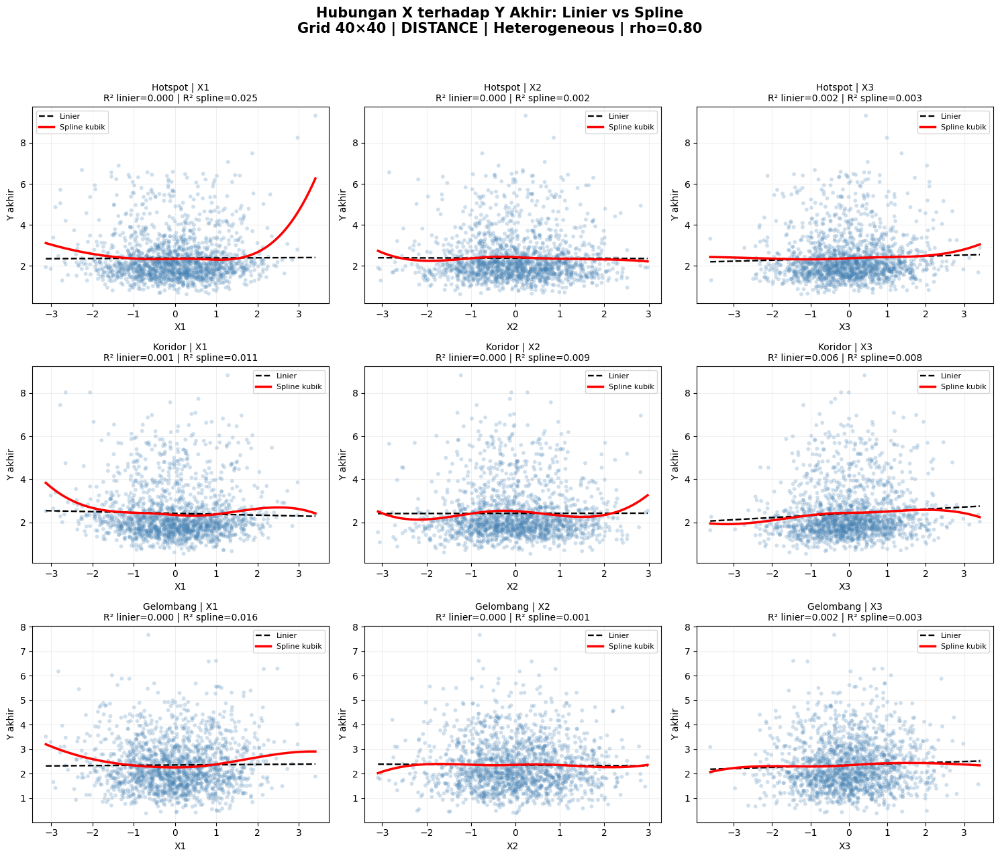

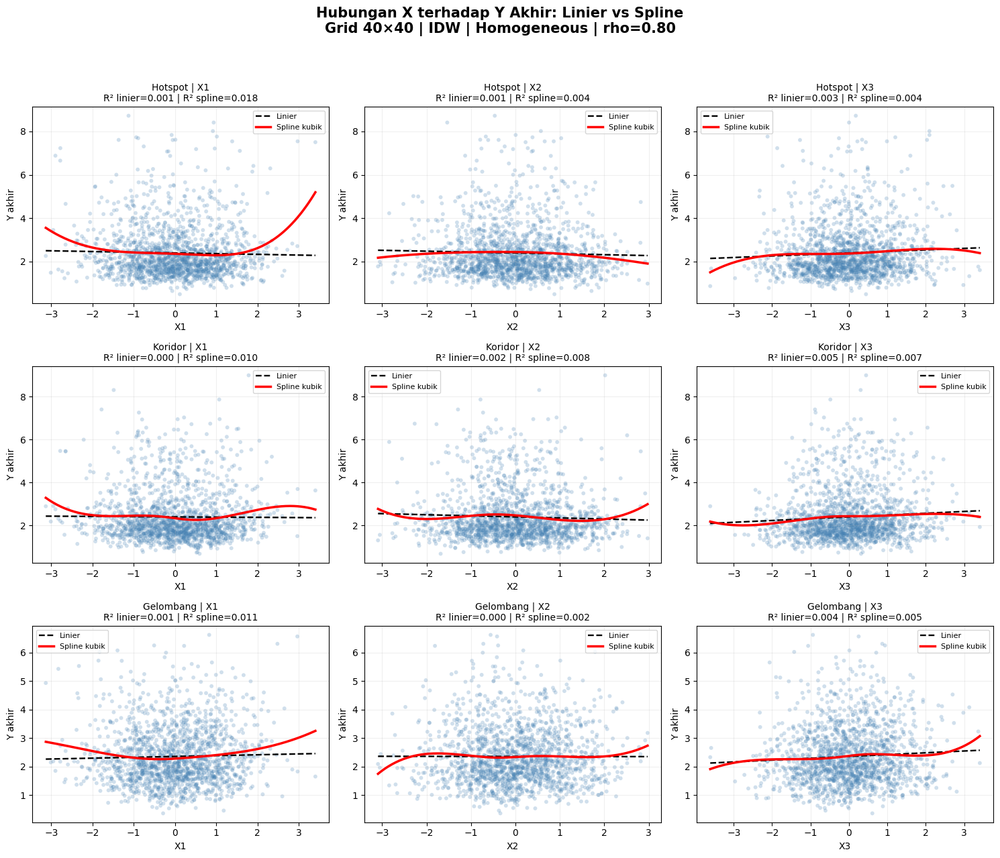

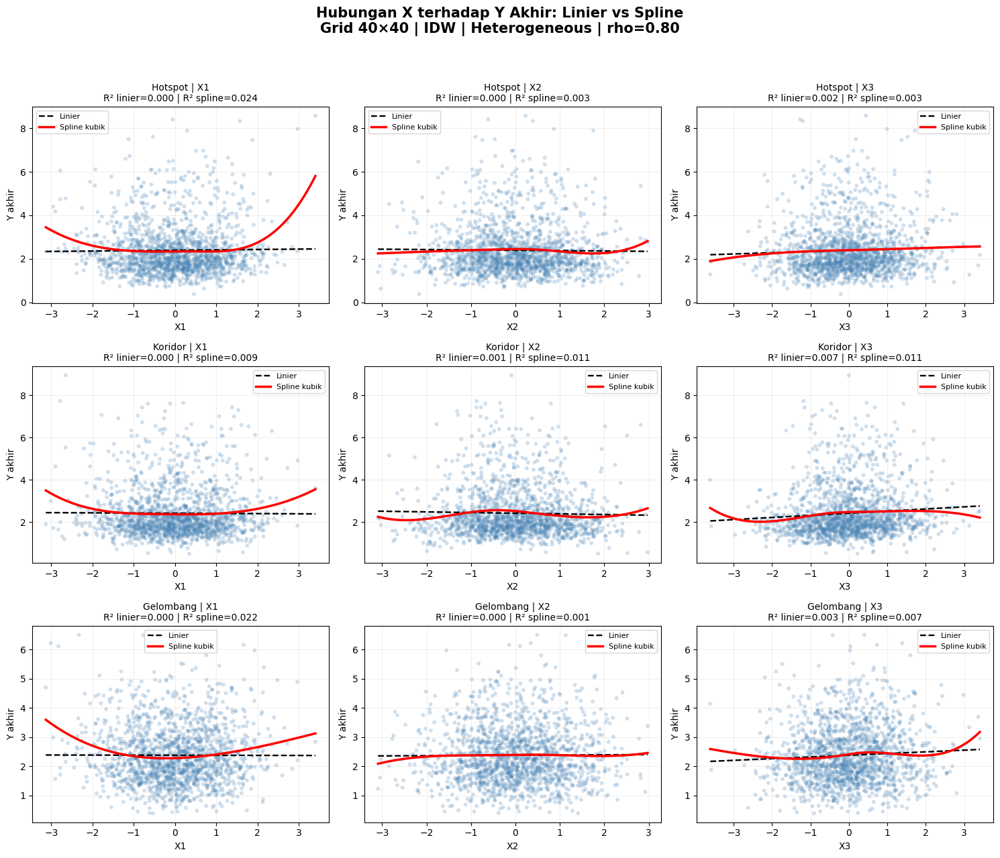

✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI


CEK BREUSCH-PAGAN — GRID 40×40 — STRONG rho=0.80:
  Pattern W_Method Error_Structure    BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 136.809

In [5]:
# ================================================================
# STRONG rho = 0.80
# GRID 40×40
# ================================================================

STRONG_GRID40 = run_strong_grid(
    40
)



STRONG SPATIAL DEPENDENCE — rho=0.80
GRID 50 × 50
N = 2500

✅ A. GRID / KOORDINAT BERHASIL


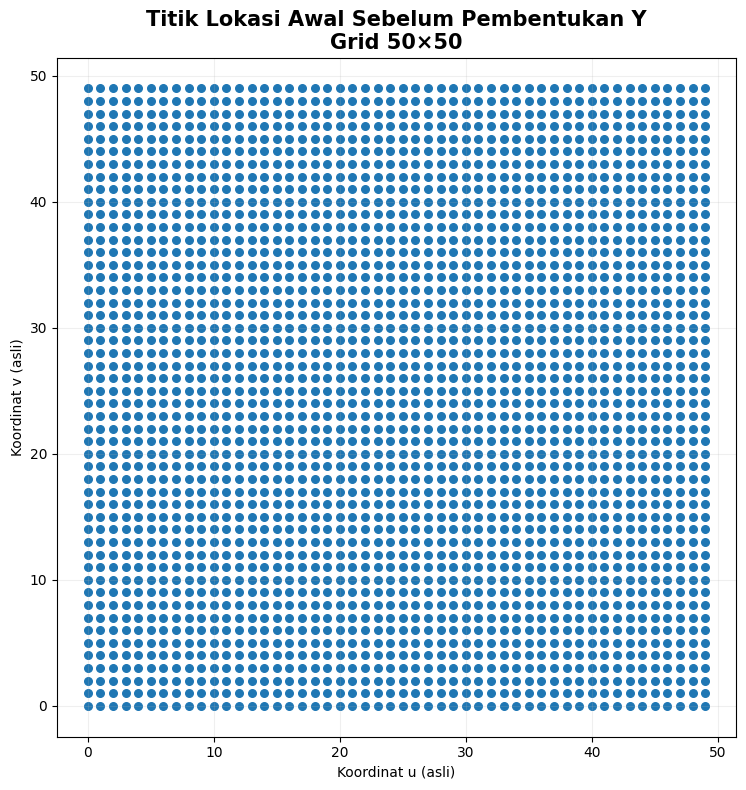

✅ B. Z(s) SELESAI


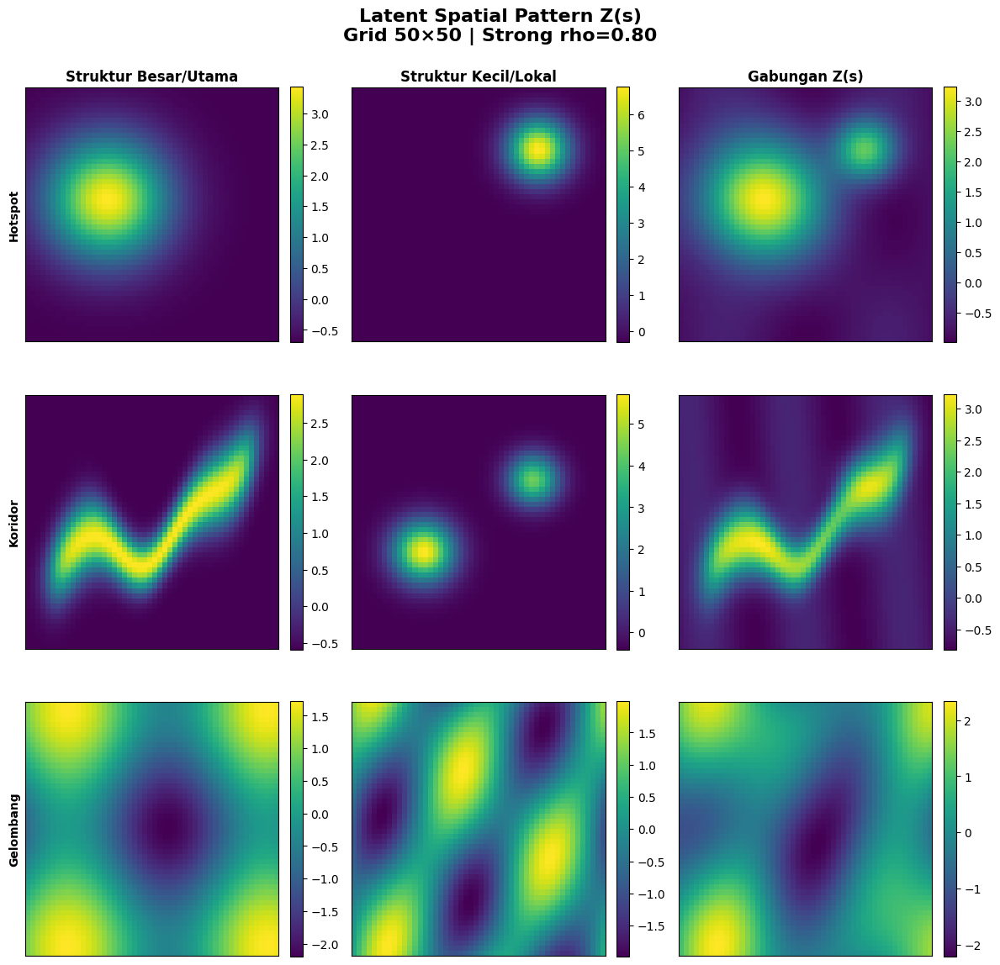


DIAGNOSTIK GRID 50x50
Beta 1 = 1.9778
Beta 2 = -0.4720
Beta 3 = 1.3086

Simpangan baku kontribusi:
X1 kuadratik = 1.9778
X2 kuadratik = 0.4720
X3 sinus     = 1.3086
✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000

CEK MULTIKOLINEARITAS PREDIKTOR UTAMA:


,Grid,Predictor,VIF,Tolerance,Status
0,50x50,X1,1.0001,0.9999,RENDAH
1,50x50,X2,1.0002,0.9998,RENDAH
2,50x50,X3,1.0002,0.9998,RENDAH


Matriks korelasi Pearson:


,X1,X2,X3
X1,1.0000,0.0051,-0.0058
X2,0.0051,1.0000,-0.0133
X3,-0.0058,-0.0133,1.0000


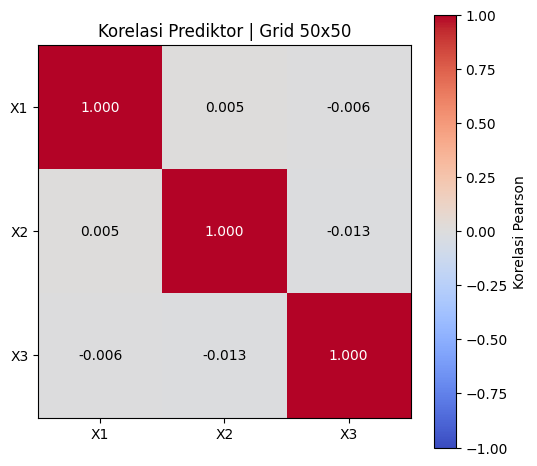

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,50x50,KNN5,5,5.00,5
1,50x50,DISTANCE,3,7.76,8
2,50x50,IDW,7,19.13,20


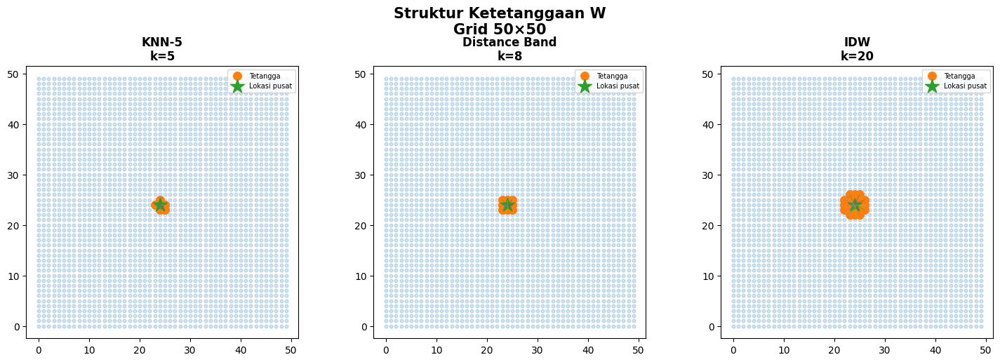

✅ E. 18 SKENARIO Y TWEEDIE SELESAI
   Y minimum = 0.220777
   Proporsi nol = 0.00%


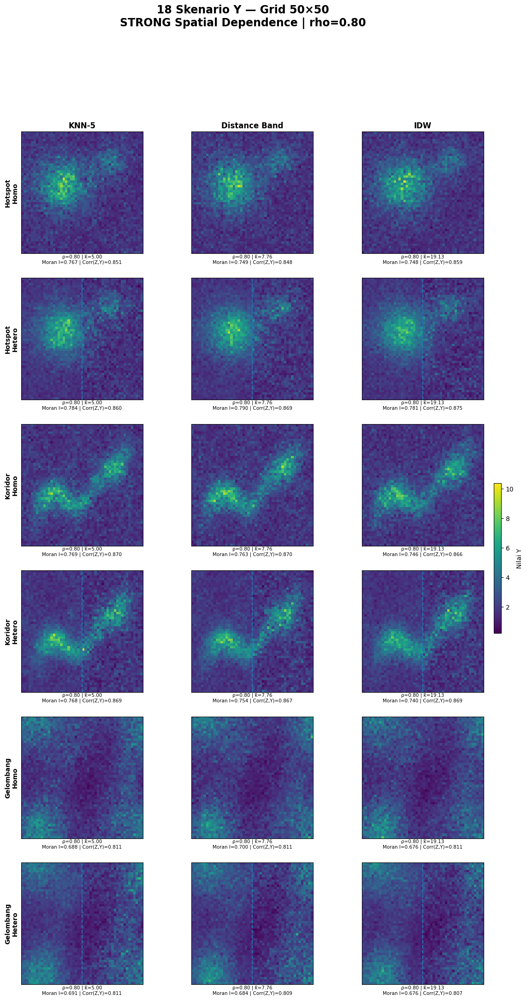

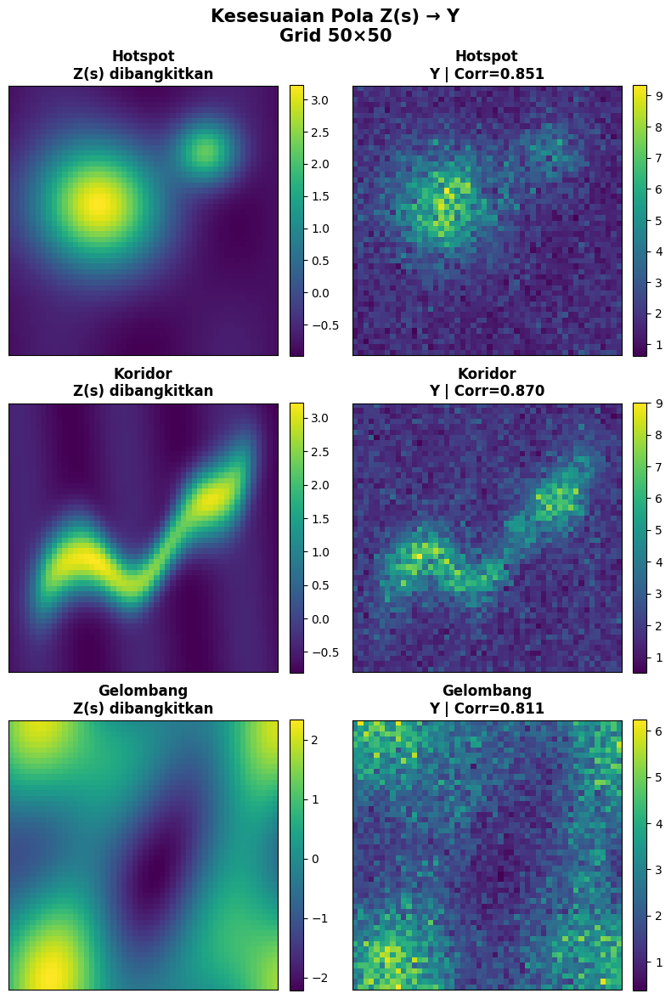

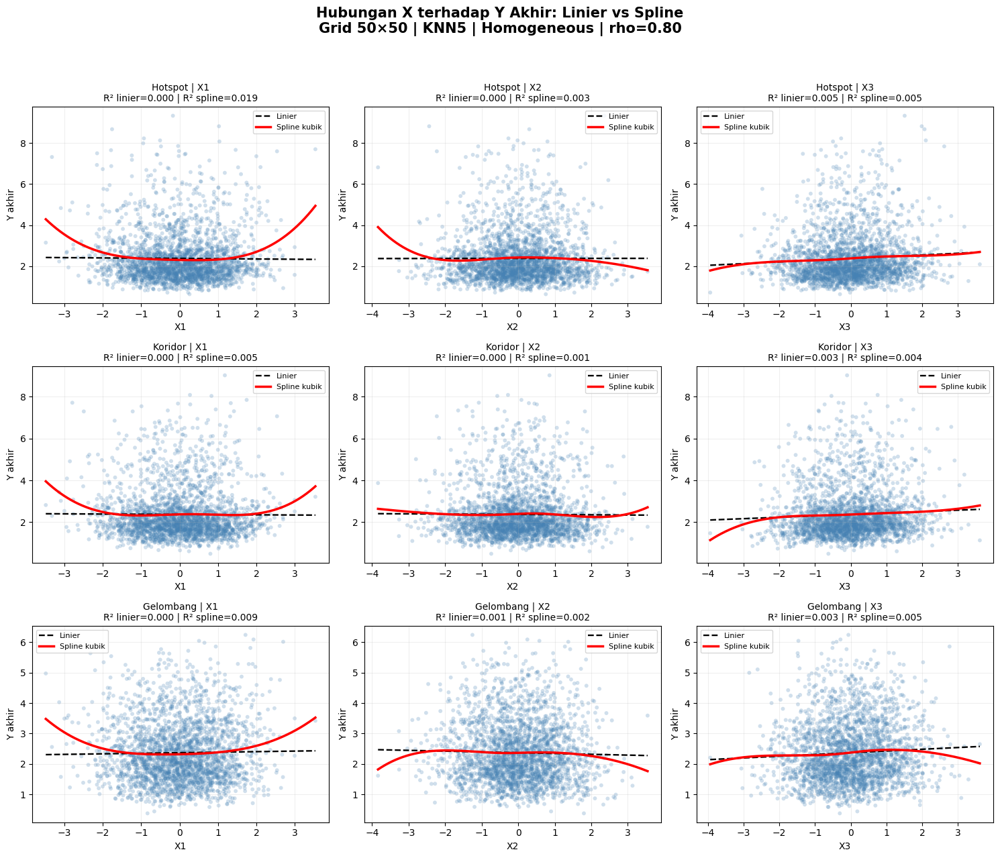

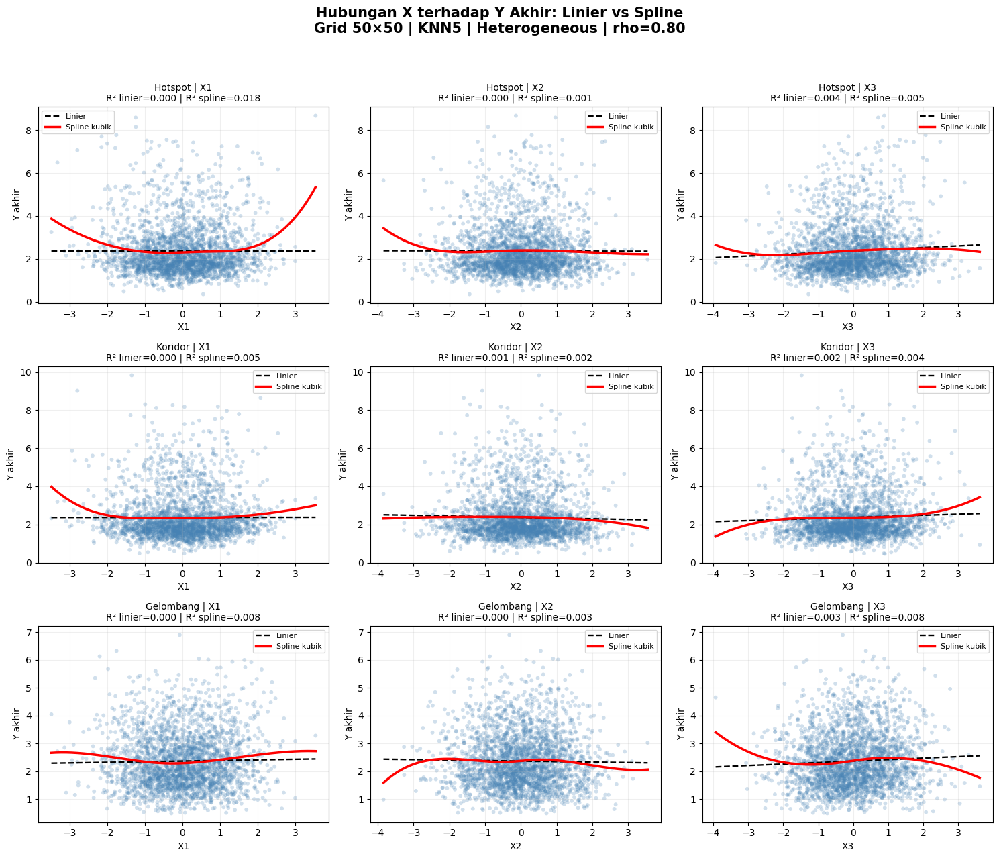

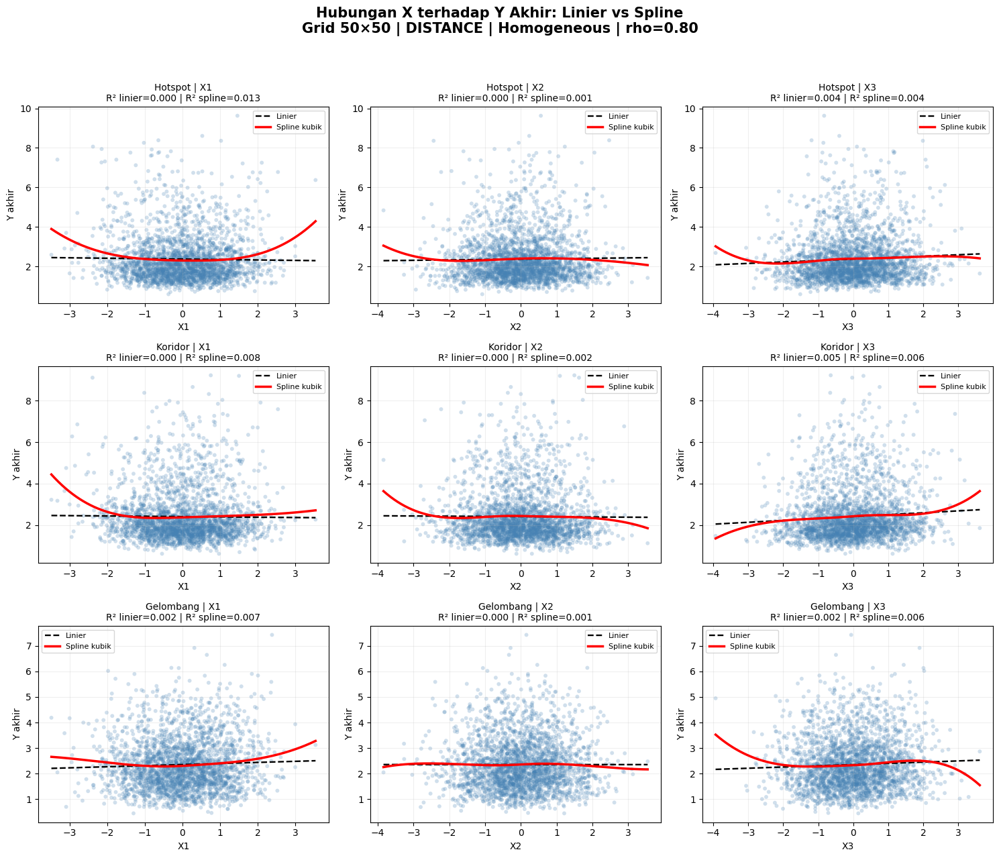

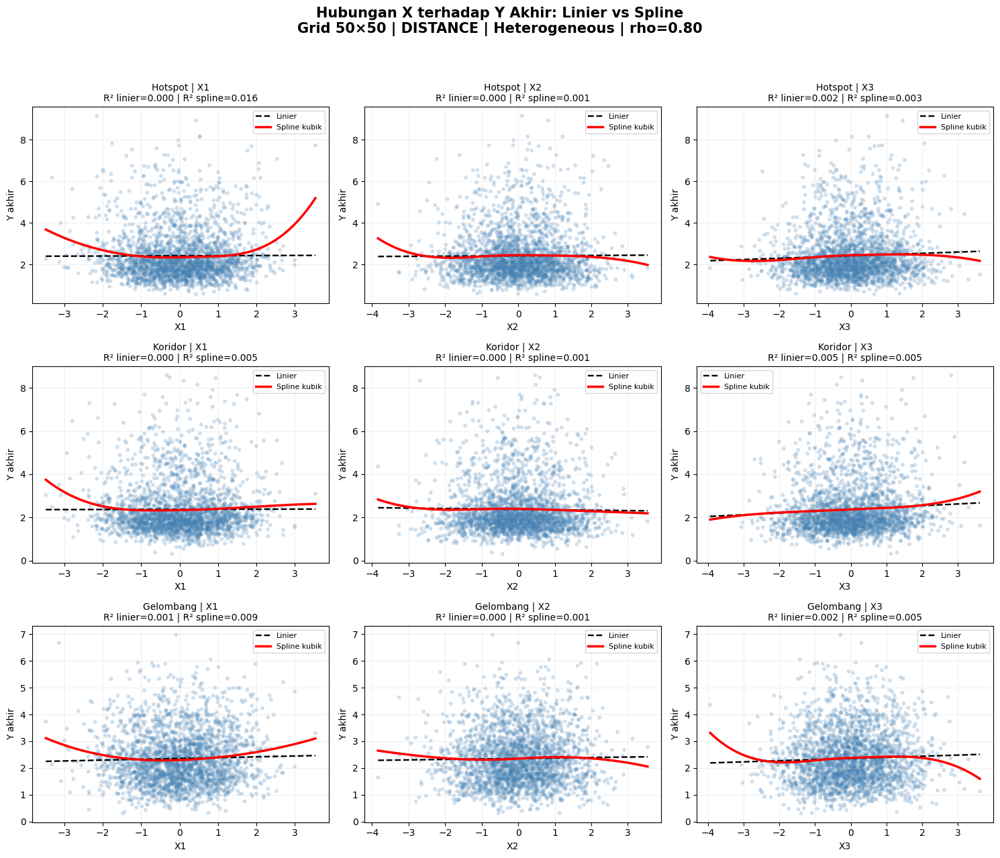

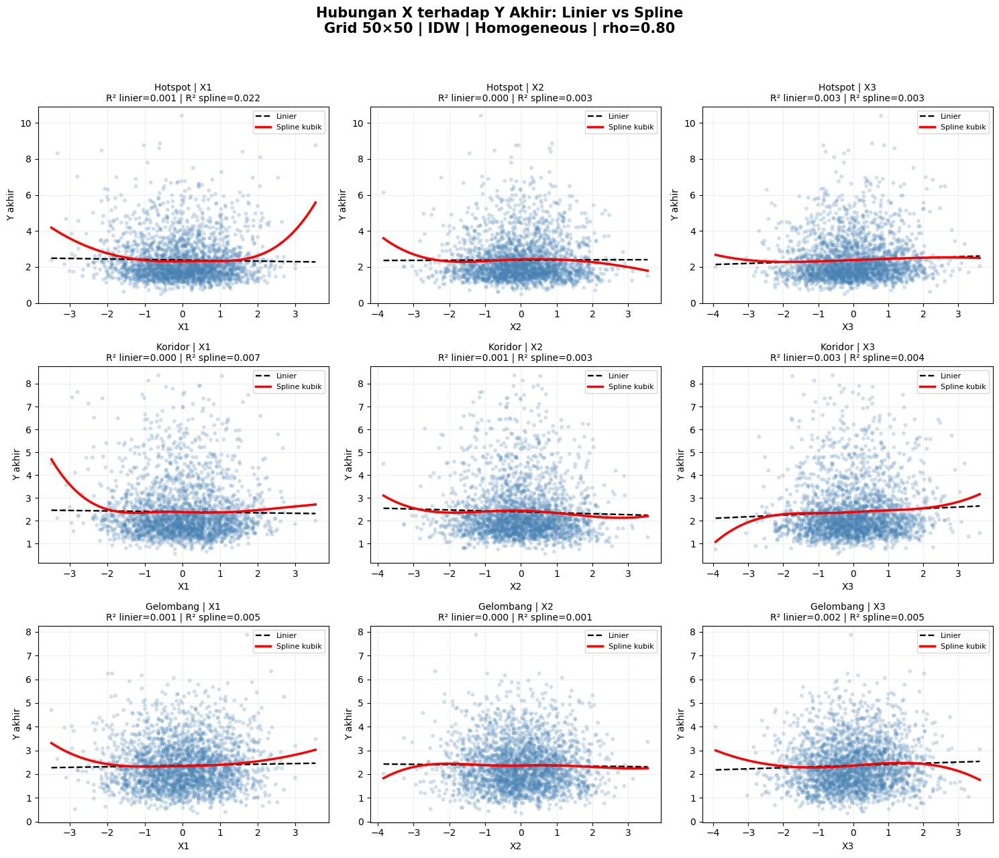

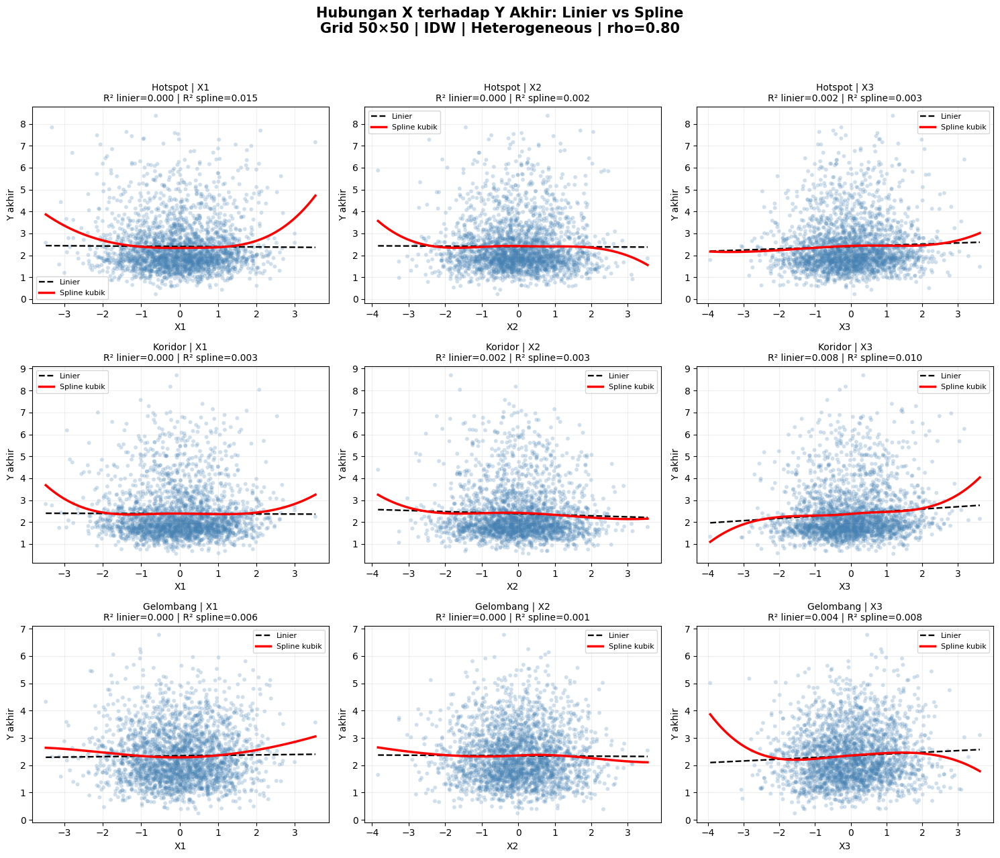

✅ VISUAL 6 — LINIER VS SPLINE X DAN Y AKHIR SELESAI


CEK BREUSCH-PAGAN — GRID 50×50 — STRONG rho=0.80:
  Pattern W_Method Error_Structure    BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 207.320

In [6]:
# ================================================================
# STRONG rho = 0.80
# GRID 50×50
# ================================================================

STRONG_GRID50 = run_strong_grid(
    50
)

In [7]:
# ================================================================
# GABUNG SUMMARY GRID10 - GRID50 — STRONG
# ================================================================

SUMMARY_STRONG_ALL = pd.concat(

    [
        STRONG_GRID10["summary"],
        STRONG_GRID20["summary"],
        STRONG_GRID30["summary"],
        STRONG_GRID40["summary"],
        STRONG_GRID50["summary"]
    ],

    ignore_index=True

)


print("\n")
print("=" * 160)

print(
    "SUMMARY STRONG rho=0.80 — SEMUA GRID"
)

print("=" * 160)


print(

    SUMMARY_STRONG_ALL

    .round({

        "Rho": 2,

        "BP_Homo_LM": 4,
        "BP_Homo_p": 6,

        "BP_Hetero_LM": 4,
        "BP_Hetero_p": 6,

        "Homo_Var_Ratio": 4,
        "Hetero_Var_Ratio": 4,

        "Mean_Moran_I": 4,
        "Min_Moran_I": 4,
        "Max_Moran_I": 4,

        "Mean_Corr_Z_Y": 4,
        "Min_Corr_Z_Y": 4,
        "Max_Corr_Z_Y": 4

    })

    .to_string(
        index=False
    )

)


# ================================================================
# GABUNG BP SEMUA GRID — STRONG
# ================================================================

BP_STRONG_ALL = pd.concat(

    [
        STRONG_GRID10["bp"].assign(Grid="10x10"),
        STRONG_GRID20["bp"].assign(Grid="20x20"),
        STRONG_GRID30["bp"].assign(Grid="30x30"),
        STRONG_GRID40["bp"].assign(Grid="40x40"),
        STRONG_GRID50["bp"].assign(Grid="50x50")
    ],

    ignore_index=True

)


print("\n")
print("=" * 160)

print(
    "CEK BREUSCH-PAGAN — SEMUA GRID STRONG:"
)

print("=" * 160)


print(

    BP_STRONG_ALL[

        [
            "Grid",
            "Pattern",
            "W_Method",
            "Error_Structure",
            "BP_LM",
            "BP_LM_pvalue",
            "BP_F",
            "BP_F_pvalue",
            "BP_Expected",
            "BP_Decision",
            "BP_Status"
        ]

    ]

    .round({

        "BP_LM": 4,
        "BP_LM_pvalue": 6,
        "BP_F": 4,
        "BP_F_pvalue": 6

    })

    .to_string(
        index=False
    )

)


# ================================================================
# SAVE SUMMARY SEMUA GRID — STRONG
# ================================================================

SUMMARY_STRONG_ALL.to_csv(

    BASE_OUTPUT_STRONG
    /
    "SUMMARY_STRONG_ALL_GRID.csv",

    index=False

)


BP_STRONG_ALL.to_csv(

    BASE_OUTPUT_STRONG
    /
    "BREUSCH_PAGAN_STRONG_ALL_GRID.csv",

    index=False

)


# ================================================================
# ZIP SELURUH STRONG
# ================================================================

ZIP_STRONG = Path(

    "/content/"
    "STRONG_RHO080_ALL_GRID.zip"

)


with zipfile.ZipFile(

    ZIP_STRONG,

    "w",

    compression=zipfile.ZIP_DEFLATED

) as zipf:

    for file_path in (
        BASE_OUTPUT_STRONG.rglob("*")
    ):

        if file_path.is_file():

            zipf.write(

                file_path,

                arcname=file_path.relative_to(
                    BASE_OUTPUT_STRONG.parent
                )

            )


print("\n")
print("=" * 100)

print(
    "🎉 STRONG rho=0.80 — GRID10 SAMPAI GRID50 SELESAI"
)

print("=" * 100)

print("\n📦 ZIP:")
print(ZIP_STRONG)



SUMMARY STRONG rho=0.80 — SEMUA GRID
 Grid    N  Rho  Scenario    Beta1     Beta2    Beta3  BP_Homo_LM  BP_Homo_p BP_Homo_Decision  BP_Hetero_LM  BP_Hetero_p BP_Hetero_Decision  Homo_Var_Ratio  Hetero_Var_Ratio  Mean_Moran_I  Min_Moran_I  Max_Moran_I  Mean_Corr_Z_Y  Min_Corr_Z_Y  Max_Corr_Z_Y  BP_All_PASS  Variance_All_PASS  Moran_All_PASS  Pattern_All_PASS
10x10  100  0.8        18 1.977831 -0.471961 1.308592      3.0051   0.083002    Homoskedastik       18.8247     0.000014    Heteroskedastik          1.6199            4.8596        0.5252       0.3608       0.6449         0.7792        0.7219        0.8512         True               True            True              True
20x20  400  0.8        18 1.977831 -0.471961 1.308592      1.1785   0.277655    Homoskedastik       50.3429     0.000000    Heteroskedastik          1.1534            3.4601        0.6654       0.5889       0.7337         0.8292        0.7785        0.8706         True               True            True           

In [10]:

# ================================================================
# SAVE ZIP STRONG RHO = 0.80 KE GOOGLE DRIVE
# VERSI SEIMBANG_MULTIKOL
# SELURUH DATA, GAMBAR, MATRIKS W, DAN DIAGNOSTIK
# TANPA MENJALANKAN ULANG SIMULASI
# ================================================================

from google.colab import drive
from pathlib import Path
import shutil
import zipfile
import hashlib
import pandas as pd
from IPython.display import display

# ================================================================
# 1. HUBUNGKAN GOOGLE DRIVE
# ================================================================

drive.mount("/content/drive")

# ================================================================
# 2. KONFIGURASI
# ================================================================

TINGKAT = "STRONG"
RHO = 0.80
RHO_KODE = "080"

GRID_LIST = [10, 20, 30, 40, 50]

folder_sumber = Path(
    f"/content/SIMULASI_{TINGKAT}_RHO{RHO_KODE}_SEIMBANG_MULTIKOL"
)

file_zip = Path(
    f"/content/{TINGKAT}_RHO{RHO_KODE}_SEIMBANG_MULTIKOL_ALL_GRID.zip"
)

folder_drive = Path(
    "/content/drive/MyDrive/HASIL_SIMULASI_TWEEDIE_baru"
)

folder_drive.mkdir(
    parents=True,
    exist_ok=True
)

# ================================================================
# 3. PASTIKAN FOLDER SUMBER TERSEDIA
# ================================================================

if not folder_sumber.is_dir():

    raise FileNotFoundError(
        f"Folder simulasi tidak ditemukan:\n"
        f"{folder_sumber}\n"
        "Pastikan seluruh pembangkitan data sudah dijalankan."
    )

print("=" * 100)
print(f"PENYIMPANAN HASIL {TINGKAT} | RHO = {RHO:.2f}")
print("=" * 100)

print("\nFolder sumber:")
print(folder_sumber)

# ================================================================
# 4. PERIKSA KELENGKAPAN SELURUH GRID
# ================================================================

CHECK_ROWS = []
MISSING_FILES = []

for grid in GRID_LIST:

    folder_grid = folder_sumber / f"GRID{grid}"

    file_wajib = [

        f"DATA_{TINGKAT}_GRID{grid}_RHO{RHO_KODE}.csv",

        f"VALIDASI_{TINGKAT}_GRID{grid}_RHO{RHO_KODE}.csv",

        f"SUMMARY_{TINGKAT}_GRID{grid}.csv",

        f"KOORDINAT_UV_GRID{grid}.csv",

        f"BREUSCH_PAGAN_GRID{grid}.csv",

        f"INFO_W_GRID{grid}.csv",

        f"W_GRID{grid}_KNN5.npz",

        f"W_GRID{grid}_DISTANCE.npz",

        f"W_GRID{grid}_IDW.npz",

        "00_TITIK_LOKASI_AWAL.png",

        "01_LATENT_PATTERN.png",

        "03_STRUKTUR_W.png",

        "04_Y_18_SKENARIO.png",

        "05_Z_VS_Y.png"

    ]

    if folder_grid.is_dir():

        semua_file = [
            f for f in folder_grid.rglob("*")
            if f.is_file()
        ]

        jumlah_csv = sum(
            f.suffix.lower() == ".csv"
            for f in semua_file
        )

        jumlah_png = sum(
            f.suffix.lower() == ".png"
            for f in semua_file
        )

        jumlah_npz = sum(
            f.suffix.lower() == ".npz"
            for f in semua_file
        )

        belum_ada = [
            nama for nama in file_wajib
            if not (folder_grid / nama).is_file()
        ]

        for nama in belum_ada:

            MISSING_FILES.append(
                f"GRID{grid}/{nama}"
            )

        status = (
            "PASS"
            if len(belum_ada) == 0
            else "CHECK"
        )

        CHECK_ROWS.append({

            "Grid": f"{grid}x{grid}",

            "N": grid**2,

            "Folder": "Ada",

            "CSV": jumlah_csv,

            "PNG": jumlah_png,

            "NPZ": jumlah_npz,

            "Total_File": len(semua_file),

            "File_Wajib_Hilang": len(belum_ada),

            "Status": status

        })

    else:

        MISSING_FILES.append(f"GRID{grid}")

        CHECK_ROWS.append({

            "Grid": f"{grid}x{grid}",

            "N": grid**2,

            "Folder": "Belum ada",

            "CSV": 0,

            "PNG": 0,

            "NPZ": 0,

            "Total_File": 0,

            "File_Wajib_Hilang": len(file_wajib),

            "Status": "CHECK"

        })

CHECK_GRID = pd.DataFrame(CHECK_ROWS)

print("\nKELENGKAPAN HASIL SELURUH GRID")

display(CHECK_GRID)

# ================================================================
# 5. PERIKSA DIAGNOSTIK TERAKHIR GRID 50
# ================================================================

folder_grid50 = folder_sumber / "GRID50"

FILE_DIAGNOSTIK = [

    "CEK_RHO_DAN_W_GRID50.csv",

    "CEK_INFO_W_GRID50.csv",

    "CEK_RINGKASAN_W_GRID50.csv",

    "CEK_Y_GLOBAL_Homogeneous_GRID50.png",

    "CEK_Y_GLOBAL_Heterogeneous_GRID50.png",

    "CEK_Y_PER_POLA_Homogeneous_GRID50.png",

    "CEK_Y_PER_POLA_Heterogeneous_GRID50.png",

    "CEK_MORAN_GRID50.png",

    "CEK_KORELASI_POLA_GRID50.png"

]

DIAGNOSTIK_ROWS = []

for nama in FILE_DIAGNOSTIK:

    tersedia = (folder_grid50 / nama).is_file()

    DIAGNOSTIK_ROWS.append({

        "File_Diagnostik": nama,

        "Status": (
            "PASS"
            if tersedia
            else "CHECK"
        )

    })

    if not tersedia:

        MISSING_FILES.append(
            f"GRID50/{nama}"
        )

CHECK_DIAGNOSTIK = pd.DataFrame(
    DIAGNOSTIK_ROWS
)

print("\nKELENGKAPAN DIAGNOSTIK GRID 50")

display(CHECK_DIAGNOSTIK)

# ================================================================
# 6. CEK APAKAH ADA FILE YANG BELUM TERSEDIA
# ================================================================

if MISSING_FILES:

    print("\nPERINGATAN — FILE BELUM LENGKAP:")

    for nama in MISSING_FILES:

        print(" -", nama)

    raise RuntimeError(
        "Penyimpanan dihentikan karena hasil belum lengkap. "
        "Periksa file yang belum tersedia sebelum membuat ZIP."
    )

print("\n✅ Seluruh file wajib tersedia.")

# ================================================================
# 7. INVENTARIS SELURUH FILE
# TERMASUK SPLINE, VIF, HEATMAP, DAN DIAGNOSTIK
# ================================================================

INVENTARIS_ROWS = []

for file in sorted(folder_sumber.rglob("*")):

    if file.is_file():

        if file.name == "INVENTARIS_FILE.csv":
            continue

        INVENTARIS_ROWS.append({

            "File": str(
                file.relative_to(folder_sumber)
            ),

            "Format": file.suffix.lower(),

            "Ukuran_Byte": file.stat().st_size,

            "Ukuran_KB": round(
                file.stat().st_size / 1024,
                2
            )

        })

INVENTARIS = pd.DataFrame(INVENTARIS_ROWS)

INVENTARIS.to_csv(

    folder_sumber / "INVENTARIS_FILE.csv",

    index=False

)

print("\nRINGKASAN SELURUH FILE YANG AKAN DISIMPAN")

RINGKASAN_FILE = (

    INVENTARIS.groupby("Format")

    .agg(

        Jumlah_File=("File", "count"),

        Total_Byte=("Ukuran_Byte", "sum")

    )

    .reset_index()

)

RINGKASAN_FILE["Total_MB"] = (

    RINGKASAN_FILE["Total_Byte"]

    / (1024**2)

).round(2)

display(RINGKASAN_FILE)

# ================================================================
# 8. BUAT ZIP SELURUH FOLDER
# ================================================================

print("\n📦 Membuat ZIP seluruh hasil simulasi...")

shutil.make_archive(

    str(file_zip.with_suffix("")),

    "zip",

    root_dir=str(folder_sumber.parent),

    base_dir=folder_sumber.name

)

# ================================================================
# 9. PERIKSA INTEGRITAS DAN KELENGKAPAN ZIP
# ================================================================

with zipfile.ZipFile(file_zip, "r") as z:

    file_rusak = z.testzip()

    if file_rusak is not None:

        raise RuntimeError(
            f"ZIP bermasalah: {file_rusak}"
        )

    daftar_file_zip = {

        item.filename

        for item in z.infolist()

        if not item.is_dir()

    }

    daftar_file_sumber = {

        f"{folder_sumber.name}/"
        f"{f.relative_to(folder_sumber).as_posix()}"

        for f in folder_sumber.rglob("*")

        if f.is_file()

    }

    file_tidak_masuk = (
        daftar_file_sumber - daftar_file_zip
    )

    if file_tidak_masuk:

        raise RuntimeError(
            f"Ada file yang tidak masuk ZIP: "
            f"{file_tidak_masuk}"
        )

    print("\n✅ Integritas ZIP: PASS")

    print("✅ Seluruh file sumber masuk ZIP.")

    print("Jumlah file:", len(daftar_file_zip))

# ================================================================
# 10. SALIN ZIP KE GOOGLE DRIVE
# ================================================================

tujuan = folder_drive / file_zip.name

print("\n📁 Menyalin ZIP ke Google Drive...")

shutil.copy2(

    file_zip,

    tujuan

)

# ================================================================
# 11. VERIFIKASI SALINAN GOOGLE DRIVE
# ================================================================

def hitung_sha256(path):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            sha.update(chunk)

    return sha.hexdigest()


assert tujuan.is_file(), (
    "ZIP belum tersedia di Google Drive."
)

assert hitung_sha256(file_zip) == hitung_sha256(tujuan), (
    "Salinan ZIP di Google Drive berbeda dari file sumber."
)

print("\n✅ Integritas salinan Google Drive: PASS")

# ================================================================
# 12. RINGKASAN AKHIR
# ================================================================

print("\n" + "=" * 100)

print("🎉 PENYIMPANAN HASIL SIMULASI BERHASIL")

print("=" * 100)

print("Tingkat dependensi :", TINGKAT)

print("Rho                :", RHO)

print("Jumlah grid        :", len(GRID_LIST))

print("Rancangan skenario :", len(GRID_LIST) * 18)

print("Jumlah file ZIP    :", len(daftar_file_zip))

print(

    "Ukuran ZIP         :",

    round(
        tujuan.stat().st_size / (1024**2),
        2
    ),

    "MB"

)

print("\n📁 Lokasi Google Drive:")

print(tujuan)

print("\n✅ SELURUH FILE YANG TERSEDIA TELAH DISIMPAN")

print("✅ Data CSV")

print("✅ Seluruh gambar PNG")

print("✅ Matriks W NPZ")

print("✅ Hasil multikolinearitas yang tersedia")

print("✅ Grafik spline yang tersedia")

print("✅ Hasil validasi")

print("✅ Hasil diagnostik rho dan W")

print("✅ Inventaris file")

print("\nTIDAK ADA PEMBANGKITAN ULANG DATA.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PENYIMPANAN HASIL STRONG | RHO = 0.80

Folder sumber:
/content/SIMULASI_STRONG_RHO080_SEIMBANG_MULTIKOL

KELENGKAPAN HASIL SELURUH GRID


,Grid,N,Folder,CSV,PNG,NPZ,Total_File,File_Wajib_Hilang,Status
0,10x10,100,Ada,8,12,3,23,0,PASS
1,20x20,400,Ada,8,12,3,23,0,PASS
2,30x30,900,Ada,8,12,3,23,0,PASS
3,40x40,1600,Ada,8,12,3,23,0,PASS
4,50x50,2500,Ada,11,18,3,32,0,PASS



KELENGKAPAN DIAGNOSTIK GRID 50


,File_Diagnostik,Status
0,CEK_RHO_DAN_W_GRID50.csv,PASS
1,CEK_INFO_W_GRID50.csv,PASS
2,CEK_RINGKASAN_W_GRID50.csv,PASS
3,CEK_Y_GLOBAL_Homogeneous_GRID50.png,PASS
4,CEK_Y_GLOBAL_Heterogeneous_GRID50.png,PASS
5,CEK_Y_PER_POLA_Homogeneous_GRID50.png,PASS
6,CEK_Y_PER_POLA_Heterogeneous_GRID50.png,PASS
7,CEK_MORAN_GRID50.png,PASS
8,CEK_KORELASI_POLA_GRID50.png,PASS



✅ Seluruh file wajib tersedia.

RINGKASAN SELURUH FILE YANG AKAN DISIMPAN


,Format,Jumlah_File,Total_Byte,Total_MB
0,.csv,45,53499015,51.02
1,.npz,15,186021,0.18
2,.png,66,44119889,42.08



📦 Membuat ZIP seluruh hasil simulasi...

✅ Integritas ZIP: PASS
✅ Seluruh file sumber masuk ZIP.
Jumlah file: 127

📁 Menyalin ZIP ke Google Drive...

✅ Integritas salinan Google Drive: PASS

🎉 PENYIMPANAN HASIL SIMULASI BERHASIL
Tingkat dependensi : STRONG
Rho                : 0.8
Jumlah grid        : 5
Rancangan skenario : 90
Jumlah file ZIP    : 127
Ukuran ZIP         : 53.81 MB

📁 Lokasi Google Drive:
/content/drive/MyDrive/HASIL_SIMULASI_TWEEDIE_baru/STRONG_RHO080_SEIMBANG_MULTIKOL_ALL_GRID.zip

✅ SELURUH FILE YANG TERSEDIA TELAH DISIMPAN
✅ Data CSV
✅ Seluruh gambar PNG
✅ Matriks W NPZ
✅ Hasil multikolinearitas yang tersedia
✅ Grafik spline yang tersedia
✅ Hasil validasi
✅ Hasil diagnostik rho dan W
✅ Inventaris file

TIDAK ADA PEMBANGKITAN ULANG DATA.


Data berhasil dibaca:
/content/SIMULASI_STRONG_RHO080_SEIMBANG_MULTIKOL/GRID50/DATA_STRONG_GRID50_RHO080.csv

VALIDASI STRUKTUR DATA: BERHASIL
Jumlah observasi : 45000
Jumlah skenario  : 18
Y minimum        : 0.2207774839989803
Jumlah Y negatif : 0
Proporsi nol     : 0.00%

PEMERIKSAAN MATRIKS W


,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Row_Standardized,Status
0,KNN5,5,5.0000,5,True,PASS
1,DISTANCE,3,7.7616,8,True,PASS
2,IDW,7,19.1280,20,True,PASS



DIAGNOSTIK STRONG | rho=0.80 | GRID 50x50

A. RATA-RATA MENURUT MATRIKS W


,Mean_neighbors,Moran_Y,Moran_Mu,Moran_SAR_Signal,Corr_Z_Y,Corr_Z_Mu
W_Method,,,,,,
DISTANCE,7.7616,0.7399,0.9700,0.9718,0.8456,0.9701
IDW,19.1280,0.7279,0.9567,0.9604,0.8479,0.9710
KNN5,5.0000,0.7444,0.9742,0.9754,0.8452,0.9664



B. RATA-RATA MENURUT POLA SPASIAL


,Moran_Y,Moran_Mu,Moran_SAR_Signal,Corr_Z_Y,Corr_Z_Mu
Pattern,,,,,
Gelombang,0.6857,0.9712,0.9742,0.8101,0.9639
Hotspot,0.7698,0.9735,0.9747,0.8603,0.9668
Koridor,0.7566,0.9562,0.9588,0.8684,0.9769


... (2 outputs left out)


D. DETAIL SELURUH 18 SKENARIO


,Rho,Grid,Pattern,Error,W_Method,Moran_Y,Moran_Mu,Moran_SAR_Signal,Corr_Z_Y,Corr_Z_Mu,Y_min,Y_max,Y_mean,Y_sd,Zero_pct,Mean_neighbors,Moran_Status,Pattern_Status
0,0.8,50x50,Gelombang,Heterogeneous,DISTANCE,0.6838,0.9734,0.9762,0.8094,0.9646,0.3046,6.9739,2.3550,1.0028,0.0,7.7616,PASS,PASS
1,0.8,50x50,Gelombang,Heterogeneous,IDW,0.6756,0.9645,0.9675,0.8075,0.9659,0.2374,6.7754,2.3461,0.9983,0.0,19.1280,PASS,PASS
2,0.8,50x50,Gelombang,Heterogeneous,KNN5,0.6908,0.9759,0.9788,0.8115,0.9613,0.4945,6.8970,2.3678,1.0000,0.0,5.0000,PASS,PASS
3,0.8,50x50,Gelombang,Homogeneous,DISTANCE,0.7003,0.9733,0.9762,0.8107,0.9645,0.4446,7.4315,2.3537,1.0123,0.0,7.7616,PASS,PASS
4,0.8,50x50,Gelombang,Homogeneous,IDW,0.6759,0.9644,0.9675,0.8109,0.9659,0.3428,7.8719,2.3629,0.9989,0.0,19.1280,PASS,PASS
5,0.8,50x50,Gelombang,Homogeneous,KNN5,0.6879,0.9759,0.9788,0.8106,0.9612,0.3763,6.2427,2.3685,1.0104,0.0,5.0000,PASS,PASS
6,0.8,50x50,Hotspot,Heterogeneous,DISTANCE,0.7903,0.9757,0.9767,0.8687,0.9675,0.5683,9.1485,2.4150,1.1956,0.0,7.7616,PASS,PASS
7,0.8,50x50,Hotspot,Heterogeneous,IDW,0.7811,0.9652,0.9678,0.8755,0.9699,0.2208,8.3739,2.4007,1.1785,0.0,19.1280,PASS,PASS
8,0.8,50x50,Hotspot,Heterogeneous,KNN5,0.7839,0.9796,0.9794,0.8596,0.9628,0.3497,8.6755,2.3706,1.1825,0.0,5.0000,PASS,PASS
9,0.8,50x50,Hotspot,Homogeneous,DISTANCE,0.7485,0.9757,0.9767,0.8477,0.9675,0.6018,9.6259,2.3772,1.2047,0.0,7.7616,PASS,PASS



E. KESESUAIAN POLA SPASIAL Z(s) TERHADAP Y


,Pattern,Error,W_Method,Corr_Z_Y,Corr_Z_Mu,Pattern_Status
0,Gelombang,Heterogeneous,DISTANCE,0.8094,0.9646,PASS
1,Gelombang,Heterogeneous,IDW,0.8075,0.9659,PASS
2,Gelombang,Heterogeneous,KNN5,0.8115,0.9613,PASS
3,Gelombang,Homogeneous,DISTANCE,0.8107,0.9645,PASS
4,Gelombang,Homogeneous,IDW,0.8109,0.9659,PASS
5,Gelombang,Homogeneous,KNN5,0.8106,0.9612,PASS
6,Hotspot,Heterogeneous,DISTANCE,0.8687,0.9675,PASS
7,Hotspot,Heterogeneous,IDW,0.8755,0.9699,PASS
8,Hotspot,Heterogeneous,KNN5,0.8596,0.9628,PASS
9,Hotspot,Homogeneous,DISTANCE,0.8477,0.9675,PASS


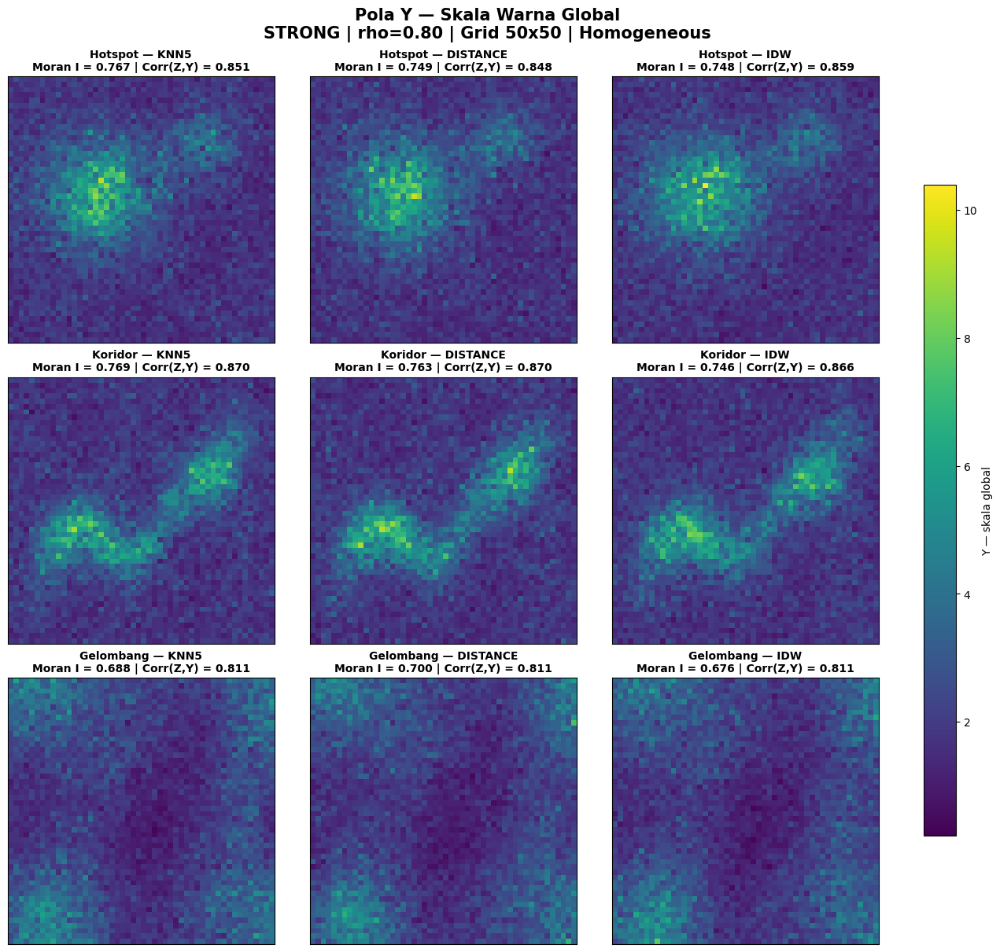

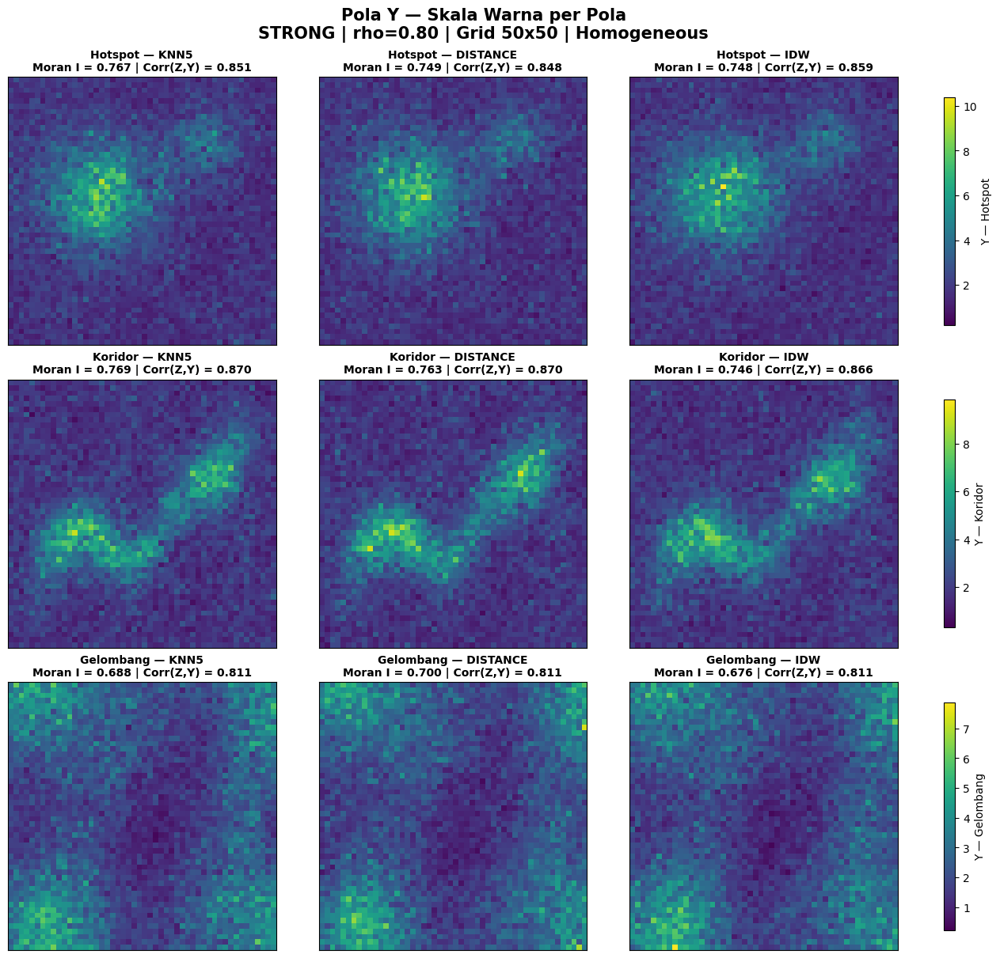

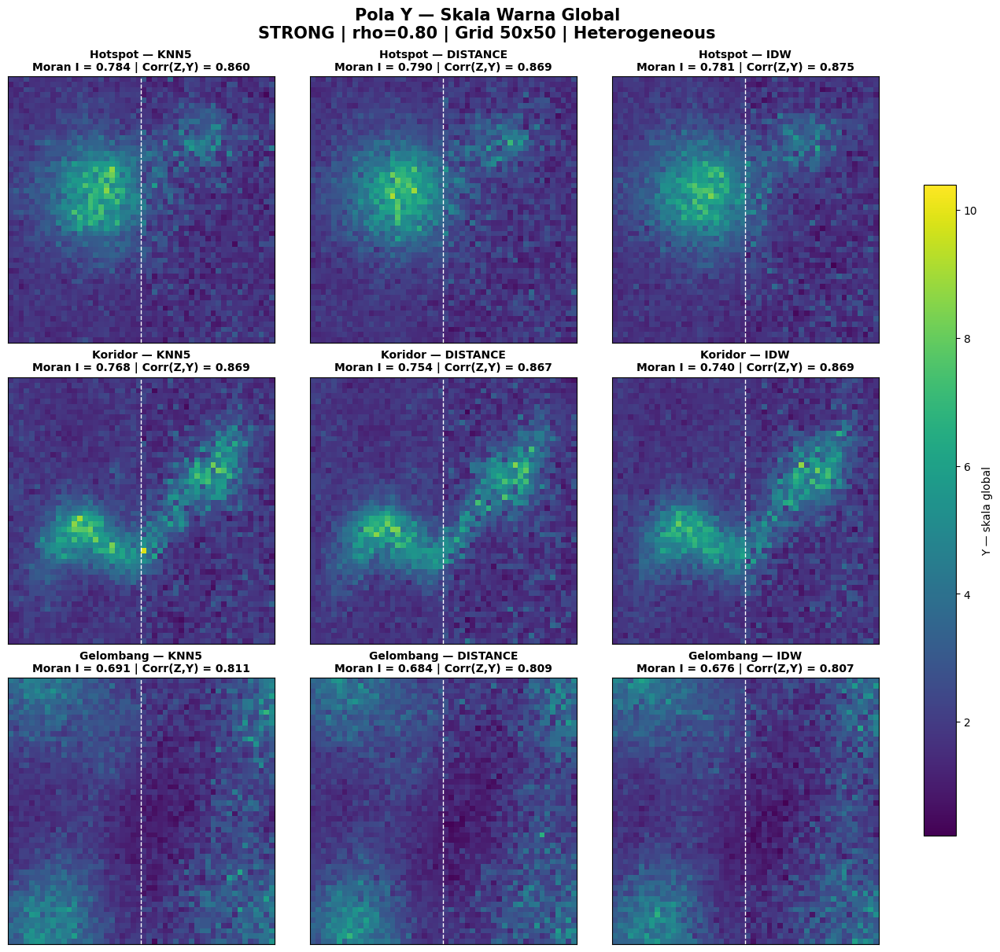

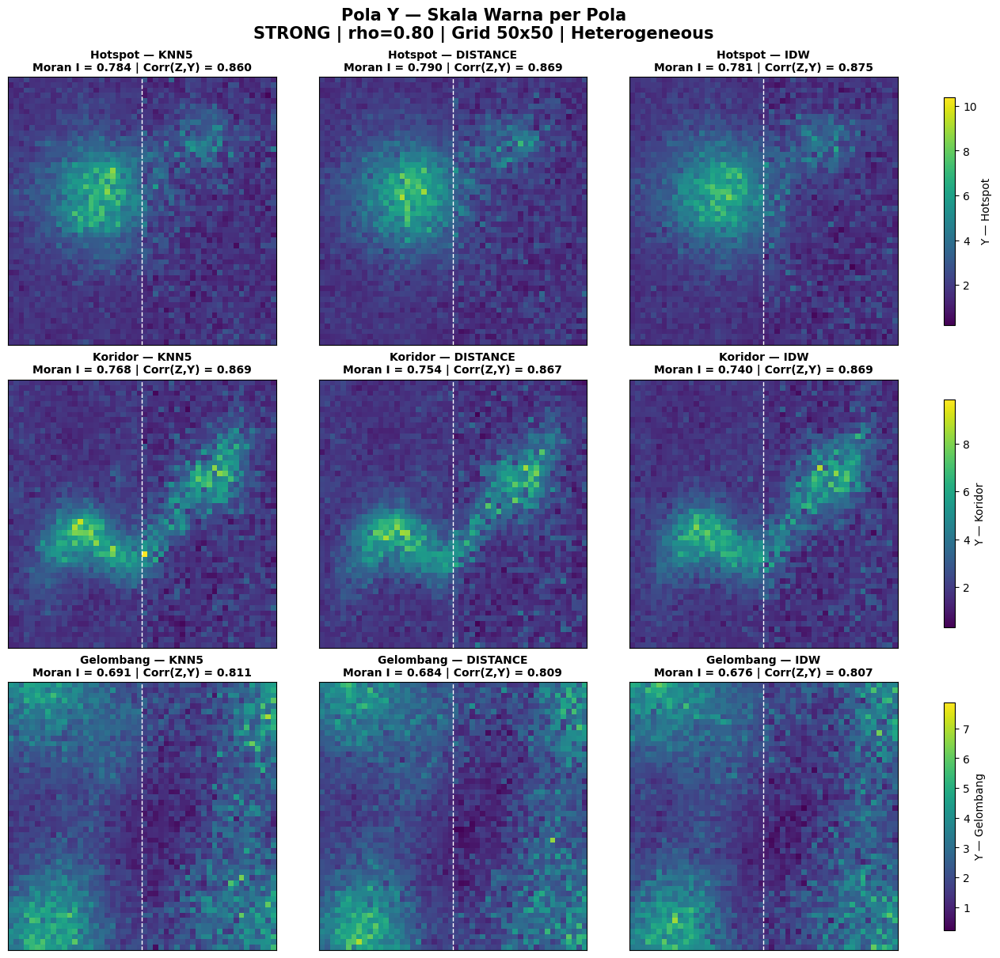

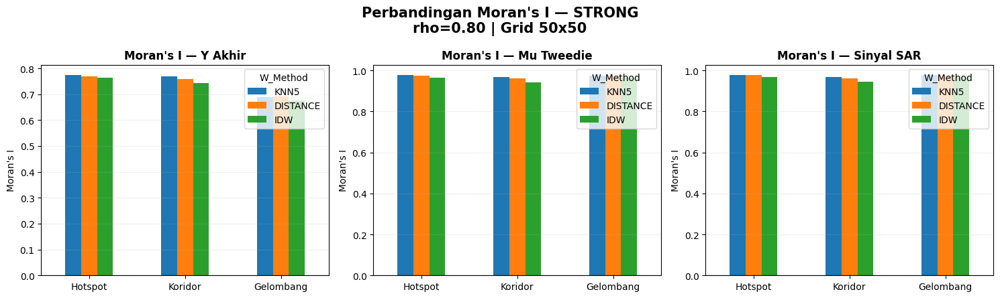

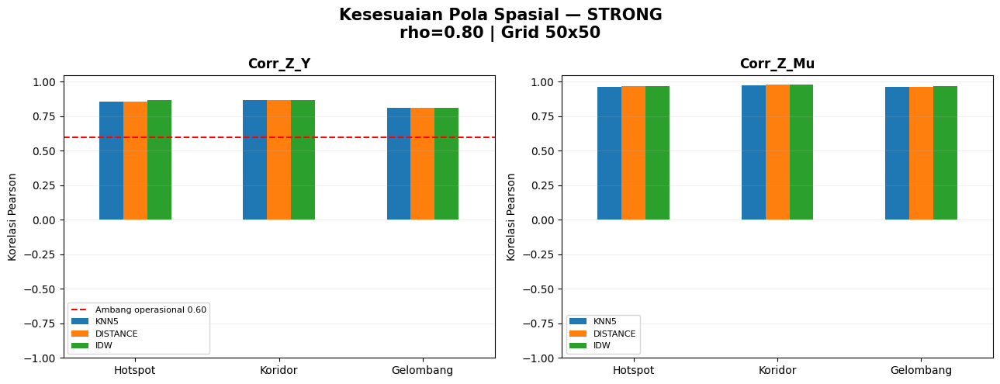


DIAGNOSTIK SELESAI
Tingkat dependensi : STRONG
Rho                : 0.8
Ukuran grid        : 50
Jumlah observasi   : 45000
Jumlah skenario    : 18
Rata-rata Moran Y  : 0.7374
Rata-rata Moran Mu : 0.967
Rata-rata Moran SAR: 0.9692
Rata-rata Corr Z,Y : 0.8462
Rata-rata Corr Z,Mu: 0.9692
Moran PASS         : 18 / 18
Pola spasial PASS  : 18 / 18
Matriks W          : PASS

Hasil tersimpan di:
/content/SIMULASI_STRONG_RHO080_SEIMBANG_MULTIKOL/GRID50

File diagnostik utama:
/content/SIMULASI_STRONG_RHO080_SEIMBANG_MULTIKOL/GRID50/CEK_RHO_DAN_W_GRID50.csv

CATATAN 1: Moran's I Y tidak wajib sama dengan rho.
CATATAN 2: Bandingkan tingkat rho pada pola, W, grid, dan struktur galat yang sama.
CATATAN 3: Ambang korelasi 0.60 merupakan kriteria operasional simulasi, bukan batas baku.
CATATAN 4: Moran's I menggunakan W masing-masing. Perbandingan antarjenis W perlu dilakukan hati-hati.

DIAGNOSTIK STRONG RHO 0.80 SELESAI


In [9]:

# ================================================================
# CELL TERAKHIR — DIAGNOSTIK RHO, W, DAN POLA Y
# STRONG — RHO = 0.80
# VERSI SEIMBANG_MULTIKOL
# Tidak membangkitkan ulang data
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

# ================================================================
# 1. KONFIGURASI
# ================================================================

TINGKAT = "STRONG"
GRID_SIZE = 50

KONFIG = {
    "WEAK": (0.20, "020"),
    "MODERATE": (0.50, "050"),
    "STRONG": (0.80, "080")
}

rho, rho_kode = KONFIG[TINGKAT]

BASE_DIR = Path(
    f"/content/SIMULASI_{TINGKAT}_RHO{rho_kode}_SEIMBANG_MULTIKOL"
)

DIREKTORI = BASE_DIR / f"GRID{GRID_SIZE}"

FILE_DATA = DIREKTORI / (
    f"DATA_{TINGKAT}_GRID{GRID_SIZE}_RHO{rho_kode}.csv"
)

metode_W = ["KNN5", "DISTANCE", "IDW"]

pola_spasial = [
    "Hotspot",
    "Koridor",
    "Gelombang"
]

struktur_error = [
    "Homogeneous",
    "Heterogeneous"
]

# ================================================================
# 2. MEMBACA DATA
# ================================================================

if not FILE_DATA.exists():

    raise FileNotFoundError(
        f"Data tidak ditemukan:\n{FILE_DATA}\n"
        "Pastikan pembangkitan GRID sudah selesai "
        "dan menggunakan versi SEIMBANG_MULTIKOL."
    )

DATA_CEK = pd.read_csv(FILE_DATA)

print("Data berhasil dibaca:")
print(FILE_DATA)

# ================================================================
# 3. VALIDASI STRUKTUR DATA
# ================================================================

KOLOM_WAJIB = [
    "Scenario_ID",
    "Location_ID",
    "Rho",
    "Pattern",
    "Error_Structure",
    "W_Method",
    "Y",
    "Mu_Tweedie",
    "Z_spatial_latent",
    "SAR_Signal"
]

for kolom in KOLOM_WAJIB:

    assert kolom in DATA_CEK.columns, (
        f"Kolom {kolom} tidak ditemukan."
    )

assert DATA_CEK["Scenario_ID"].nunique() == 18, (
    "Jumlah skenario bukan 18."
)

assert DATA_CEK.groupby("Scenario_ID").size().eq(
    GRID_SIZE**2
).all(), "Jumlah lokasi per skenario keliru."

assert np.allclose(
    DATA_CEK["Rho"], rho
), "Rho tersimpan tidak sesuai."

assert np.isfinite(DATA_CEK["Y"]).all()
assert (DATA_CEK["Y"] >= 0).all()

assert np.isfinite(DATA_CEK["Mu_Tweedie"]).all()
assert (DATA_CEK["Mu_Tweedie"] > 0).all()

for scenario_id, d in DATA_CEK.groupby("Scenario_ID"):

    assert np.array_equal(
        np.sort(d["Location_ID"].to_numpy()),
        np.arange(1, GRID_SIZE**2 + 1)
    ), f"Location_ID tidak sesuai: {scenario_id}"

print("\nVALIDASI STRUKTUR DATA: BERHASIL")
print("Jumlah observasi :", len(DATA_CEK))
print("Jumlah skenario  :", DATA_CEK["Scenario_ID"].nunique())
print("Y minimum        :", DATA_CEK["Y"].min())
print("Jumlah Y negatif :", (DATA_CEK["Y"] < 0).sum())
print("Proporsi nol     :", f"{(DATA_CEK['Y'] == 0).mean():.2%}")

# ================================================================
# 4. MEMBACA DAN MEMERIKSA MATRIKS W
# ================================================================

W_SIMPAN = {}
INFO_W_ROWS = []

for w in metode_W:

    file_w = DIREKTORI / (
        f"W_GRID{GRID_SIZE}_{w}.npz"
    )

    if not file_w.exists():

        raise FileNotFoundError(
            f"Matriks W tidak ditemukan:\n{file_w}"
        )

    W = sp.load_npz(file_w).tocsr()

    assert W.shape == (
        GRID_SIZE**2,
        GRID_SIZE**2
    ), f"Ukuran W {w} tidak sesuai."

    assert np.isfinite(W.data).all()
    assert (W.data >= 0).all()

    assert np.allclose(
        W.diagonal(), 0
    ), f"Diagonal W {w} tidak nol."

    assert np.allclose(
        np.asarray(W.sum(axis=1)).ravel(),
        1
    ), f"W {w} belum terstandardisasi."

    W_SIMPAN[w] = W

    counts = np.diff(W.indptr)

    INFO_W_ROWS.append({

        "W_Method": w,
        "Min_Neighbor": int(counts.min()),
        "Mean_Neighbor": float(counts.mean()),
        "Max_Neighbor": int(counts.max()),
        "Row_Standardized": True,
        "Status": "PASS"

    })

INFO_W_CEK = pd.DataFrame(INFO_W_ROWS)

print("\nPEMERIKSAAN MATRIKS W")

display(INFO_W_CEK.round(4))

# ================================================================
# 5. FUNGSI MORAN'S I
# ================================================================

def hitung_moran(x, W):

    z = np.asarray(x, dtype=float)

    z = z - z.mean()

    denominator = float(z @ z)

    S0 = float(W.sum())

    if denominator <= 0 or S0 <= 0:

        return np.nan

    return float(
        (len(z) / S0)
        * (z @ (W @ z))
        / denominator
    )

# ================================================================
# 6. DIAGNOSTIK SELURUH 18 SKENARIO
# ================================================================

catatan = []

for (pola, err, w), d in DATA_CEK.groupby(
    ["Pattern", "Error_Structure", "W_Method"]
):

    d = d.sort_values("Location_ID")

    W = W_SIMPAN[w]

    y = d["Y"].to_numpy()
    mu = d["Mu_Tweedie"].to_numpy()
    z = d["Z_spatial_latent"].to_numpy()
    sar = d["SAR_Signal"].to_numpy()

    corr_zy = float(
        np.corrcoef(z, y)[0, 1]
    )

    corr_zmu = float(
        np.corrcoef(z, mu)[0, 1]
    )

    moran_y = hitung_moran(y, W)
    moran_mu = hitung_moran(mu, W)
    moran_sar = hitung_moran(sar, W)

    catatan.append({

        "Rho": rho,

        "Grid": f"{GRID_SIZE}x{GRID_SIZE}",

        "Pattern": pola,

        "Error": err,

        "W_Method": w,

        "Moran_Y": moran_y,

        "Moran_Mu": moran_mu,

        "Moran_SAR_Signal": moran_sar,

        "Corr_Z_Y": corr_zy,

        "Corr_Z_Mu": corr_zmu,

        "Y_min": float(y.min()),

        "Y_max": float(y.max()),

        "Y_mean": float(y.mean()),

        "Y_sd": float(y.std(ddof=1)),

        "Zero_pct": float(
            (y == 0).mean() * 100
        ),

        "Mean_neighbors": float(
            np.diff(W.indptr).mean()
        ),

        "Moran_Status": (
            "PASS"
            if moran_y > 0
            else "CHECK"
        ),

        "Pattern_Status": (
            "PASS"
            if corr_zy >= 0.60
            else "CHECK"
        )

    })

RINGKASAN_CEK = pd.DataFrame(catatan)

assert len(RINGKASAN_CEK) == 18

# ================================================================
# 7. TABEL HASIL DIAGNOSTIK
# ================================================================

print("\n" + "=" * 100)

print(
    f"DIAGNOSTIK {TINGKAT} | "
    f"rho={rho:.2f} | "
    f"GRID {GRID_SIZE}x{GRID_SIZE}"
)

print("=" * 100)

# ------------------------------------------------
# A. RATA-RATA MENURUT MATRIKS W
# ------------------------------------------------

print("\nA. RATA-RATA MENURUT MATRIKS W")

display(

    RINGKASAN_CEK.groupby("W_Method")[

        [
            "Mean_neighbors",
            "Moran_Y",
            "Moran_Mu",
            "Moran_SAR_Signal",
            "Corr_Z_Y",
            "Corr_Z_Mu"
        ]

    ].mean().round(4)

)

# ------------------------------------------------
# B. RATA-RATA MENURUT POLA SPASIAL
# ------------------------------------------------

print("\nB. RATA-RATA MENURUT POLA SPASIAL")

display(

    RINGKASAN_CEK.groupby("Pattern")[

        [
            "Moran_Y",
            "Moran_Mu",
            "Moran_SAR_Signal",
            "Corr_Z_Y",
            "Corr_Z_Mu"
        ]

    ].mean().round(4)

)

# ------------------------------------------------
# C. RATA-RATA MENURUT STRUKTUR GALAT
# ------------------------------------------------

print("\nC. RATA-RATA MENURUT STRUKTUR GALAT")

display(

    RINGKASAN_CEK.groupby("Error")[

        [
            "Moran_Y",
            "Moran_Mu",
            "Corr_Z_Y",
            "Y_mean",
            "Y_sd",
            "Zero_pct"
        ]

    ].mean().round(4)

)

# ------------------------------------------------
# D. DETAIL SELURUH 18 SKENARIO
# ------------------------------------------------

print("\nD. DETAIL SELURUH 18 SKENARIO")

display(

    RINGKASAN_CEK.sort_values(

        [
            "Pattern",
            "Error",
            "W_Method"
        ]

    ).round(4)

)

# ------------------------------------------------
# E. KESESUAIAN POLA SPASIAL
# ------------------------------------------------

print("\nE. KESESUAIAN POLA SPASIAL Z(s) TERHADAP Y")

display(

    RINGKASAN_CEK[

        [
            "Pattern",
            "Error",
            "W_Method",
            "Corr_Z_Y",
            "Corr_Z_Mu",
            "Pattern_Status"
        ]

    ].round(4)

)

# ================================================================
# 8. VISUALISASI PETA Y
# SKALA WARNA GLOBAL DAN PER POLA
# ================================================================

for err in struktur_error:

    peta = {}

    for i, pola in enumerate(pola_spasial):

        for j, w in enumerate(metode_W):

            d = DATA_CEK[

                (DATA_CEK["Pattern"] == pola)

                &

                (DATA_CEK["Error_Structure"] == err)

                &

                (DATA_CEK["W_Method"] == w)

            ].sort_values("Location_ID")

            assert len(d) == GRID_SIZE**2

            peta[(i, j)] = (

                d["Y"]
                .to_numpy()
                .reshape(GRID_SIZE, GRID_SIZE)

            )

    # ============================================================
    # VISUAL A — SKALA WARNA GLOBAL
    # ============================================================

    vmin = float(DATA_CEK["Y"].min())
    vmax = float(DATA_CEK["Y"].max())

    fig, axes = plt.subplots(

        3,
        3,

        figsize=(13, 12),

        constrained_layout=True

    )

    for i, pola in enumerate(pola_spasial):

        for j, w in enumerate(metode_W):

            ax = axes[i, j]

            im = ax.imshow(

                peta[(i, j)],

                origin="lower",

                cmap="viridis",

                vmin=vmin,

                vmax=vmax,

                interpolation="nearest"

            )

            hasil = RINGKASAN_CEK[

                (RINGKASAN_CEK["Pattern"] == pola)

                &

                (RINGKASAN_CEK["Error"] == err)

                &

                (RINGKASAN_CEK["W_Method"] == w)

            ].iloc[0]

            ax.set_title(

                f"{pola} — {w}\n"

                f"Moran I = {hasil['Moran_Y']:.3f} | "

                f"Corr(Z,Y) = {hasil['Corr_Z_Y']:.3f}",

                fontsize=10,

                fontweight="bold"

            )

            if err == "Heterogeneous":

                ax.axvline(

                    GRID_SIZE / 2 - 0.5,

                    linestyle="--",

                    color="white",

                    linewidth=1

                )

            ax.set_xticks([])
            ax.set_yticks([])

    fig.colorbar(

        im,

        ax=axes,

        label="Y — skala global",

        shrink=0.75

    )

    fig.suptitle(

        f"Pola Y — Skala Warna Global\n"

        f"{TINGKAT} | rho={rho:.2f} | "

        f"Grid {GRID_SIZE}x{GRID_SIZE} | {err}",

        fontsize=15,

        fontweight="bold"

    )

    plt.savefig(

        DIREKTORI /

        f"CEK_Y_GLOBAL_{err}_GRID{GRID_SIZE}.png",

        dpi=200,

        bbox_inches="tight"

    )

    plt.show()
    plt.close(fig)

    # ============================================================
    # VISUAL B — SKALA WARNA KHUSUS SETIAP POLA
    # Sama antar-W dan struktur galat pada pola yang sama
    # ============================================================

    fig, axes = plt.subplots(

        3,
        3,

        figsize=(13, 12),

        constrained_layout=True

    )

    for i, pola in enumerate(pola_spasial):

        data_pola = DATA_CEK[

            DATA_CEK["Pattern"] == pola

        ]["Y"]

        vmin_pola = float(data_pola.min())
        vmax_pola = float(data_pola.max())

        for j, w in enumerate(metode_W):

            ax = axes[i, j]

            im = ax.imshow(

                peta[(i, j)],

                origin="lower",

                cmap="viridis",

                vmin=vmin_pola,

                vmax=vmax_pola,

                interpolation="nearest"

            )

            hasil = RINGKASAN_CEK[

                (RINGKASAN_CEK["Pattern"] == pola)

                &

                (RINGKASAN_CEK["Error"] == err)

                &

                (RINGKASAN_CEK["W_Method"] == w)

            ].iloc[0]

            ax.set_title(

                f"{pola} — {w}\n"

                f"Moran I = {hasil['Moran_Y']:.3f} | "

                f"Corr(Z,Y) = {hasil['Corr_Z_Y']:.3f}",

                fontsize=10,

                fontweight="bold"

            )

            if err == "Heterogeneous":

                ax.axvline(

                    GRID_SIZE / 2 - 0.5,

                    linestyle="--",

                    color="white",

                    linewidth=1

                )

            ax.set_xticks([])
            ax.set_yticks([])

        fig.colorbar(

            im,

            ax=axes[i, :],

            label=f"Y — {pola}",

            shrink=0.85

        )

    fig.suptitle(

        f"Pola Y — Skala Warna per Pola\n"

        f"{TINGKAT} | rho={rho:.2f} | "

        f"Grid {GRID_SIZE}x{GRID_SIZE} | {err}",

        fontsize=15,

        fontweight="bold"

    )

    plt.savefig(

        DIREKTORI /

        f"CEK_Y_PER_POLA_{err}_GRID{GRID_SIZE}.png",

        dpi=200,

        bbox_inches="tight"

    )

    plt.show()
    plt.close(fig)

# ================================================================
# 9. VISUALISASI PERBANDINGAN MORAN'S I
# ================================================================

fig, axes = plt.subplots(

    1,

    3,

    figsize=(15, 4.5)

)

indikator = [

    "Moran_Y",

    "Moran_Mu",

    "Moran_SAR_Signal"

]

judul_indikator = [

    "Moran's I — Y Akhir",

    "Moran's I — Mu Tweedie",

    "Moran's I — Sinyal SAR"

]

for ax, kolom, judul in zip(

    axes,

    indikator,

    judul_indikator

):

    tabel = RINGKASAN_CEK.pivot_table(

        index="Pattern",

        columns="W_Method",

        values=kolom,

        aggfunc="mean"

    )

    tabel = tabel.reindex(

        index=pola_spasial,

        columns=metode_W

    )

    tabel.plot(

        kind="bar",

        ax=ax,

        rot=0

    )

    ax.set_title(

        judul,

        fontweight="bold"

    )

    ax.set_ylabel("Moran's I")
    ax.set_xlabel("")

    ax.axhline(

        0,

        color="black",

        linewidth=0.8

    )

    ax.grid(

        axis="y",

        alpha=0.20

    )

fig.suptitle(

    f"Perbandingan Moran's I — {TINGKAT}\n"

    f"rho={rho:.2f} | Grid {GRID_SIZE}x{GRID_SIZE}",

    fontsize=15,

    fontweight="bold"

)

plt.tight_layout()

plt.savefig(

    DIREKTORI /

    f"CEK_MORAN_GRID{GRID_SIZE}.png",

    dpi=200,

    bbox_inches="tight"

)

plt.show()
plt.close(fig)

# ================================================================
# 10. VISUALISASI KESESUAIAN POLA SPASIAL
# ================================================================

fig, axes = plt.subplots(

    1,

    2,

    figsize=(13, 5)

)

for ax, kolom in zip(

    axes,

    ["Corr_Z_Y", "Corr_Z_Mu"]

):

    tabel = RINGKASAN_CEK.pivot_table(

        index="Pattern",

        columns="W_Method",

        values=kolom,

        aggfunc="mean"

    )

    tabel = tabel.reindex(

        index=pola_spasial,

        columns=metode_W

    )

    tabel.plot(

        kind="bar",

        ax=ax,

        rot=0

    )

    ax.set_title(

        kolom,

        fontweight="bold"

    )

    ax.set_ylabel("Korelasi Pearson")
    ax.set_xlabel("")
    ax.set_ylim(-1, 1.05)

    ax.grid(

        axis="y",

        alpha=0.20

    )

    if kolom == "Corr_Z_Y":

        ax.axhline(

            0.60,

            color="red",

            linestyle="--",

            linewidth=1.5,

            label="Ambang operasional 0.60"

        )

    ax.legend(fontsize=8)

fig.suptitle(

    f"Kesesuaian Pola Spasial — {TINGKAT}\n"

    f"rho={rho:.2f} | Grid {GRID_SIZE}x{GRID_SIZE}",

    fontsize=15,

    fontweight="bold"

)

plt.tight_layout()

plt.savefig(

    DIREKTORI /

    f"CEK_KORELASI_POLA_GRID{GRID_SIZE}.png",

    dpi=200,

    bbox_inches="tight"

)

plt.show()
plt.close(fig)

# ================================================================
# 11. SIMPAN HASIL DIAGNOSTIK
# ================================================================

OUTPUT_CEK = DIREKTORI / (

    f"CEK_RHO_DAN_W_GRID{GRID_SIZE}.csv"

)

RINGKASAN_CEK.to_csv(

    OUTPUT_CEK,

    index=False

)

INFO_W_CEK.to_csv(

    DIREKTORI /

    f"CEK_INFO_W_GRID{GRID_SIZE}.csv",

    index=False

)

RINGKASAN_CEK.groupby("W_Method")[

    [
        "Mean_neighbors",
        "Moran_Y",
        "Moran_Mu",
        "Moran_SAR_Signal",
        "Corr_Z_Y",
        "Corr_Z_Mu"
    ]

].mean().to_csv(

    DIREKTORI /

    f"CEK_RINGKASAN_W_GRID{GRID_SIZE}.csv"

)

# ================================================================
# 12. SUMMARY FINAL
# ================================================================

print("\n" + "=" * 100)
print("DIAGNOSTIK SELESAI")
print("=" * 100)

print("Tingkat dependensi :", TINGKAT)
print("Rho                :", rho)
print("Ukuran grid        :", GRID_SIZE)
print("Jumlah observasi   :", len(DATA_CEK))
print("Jumlah skenario    :", len(RINGKASAN_CEK))

print(

    "Rata-rata Moran Y  :",

    round(RINGKASAN_CEK["Moran_Y"].mean(), 4)

)

print(

    "Rata-rata Moran Mu :",

    round(RINGKASAN_CEK["Moran_Mu"].mean(), 4)

)

print(

    "Rata-rata Moran SAR:",

    round(
        RINGKASAN_CEK["Moran_SAR_Signal"].mean(),
        4
    )

)

print(

    "Rata-rata Corr Z,Y :",

    round(RINGKASAN_CEK["Corr_Z_Y"].mean(), 4)

)

print(

    "Rata-rata Corr Z,Mu:",

    round(RINGKASAN_CEK["Corr_Z_Mu"].mean(), 4)

)

print(

    "Moran PASS         :",

    (RINGKASAN_CEK["Moran_Status"] == "PASS").sum(),

    "/ 18"

)

print(

    "Pola spasial PASS  :",

    (RINGKASAN_CEK["Pattern_Status"] == "PASS").sum(),

    "/ 18"

)

print("Matriks W          : PASS")

print("\nHasil tersimpan di:")
print(DIREKTORI)

print("\nFile diagnostik utama:")
print(OUTPUT_CEK)

print(

    "\nCATATAN 1: Moran's I Y tidak wajib sama dengan rho."

)

print(

    "CATATAN 2: Bandingkan tingkat rho pada pola, W, "

    "grid, dan struktur galat yang sama."

)

print(

    "CATATAN 3: Ambang korelasi 0.60 merupakan "

    "kriteria operasional simulasi, bukan batas baku."

)

print(

    "CATATAN 4: Moran's I menggunakan W masing-masing. "

    "Perbandingan antarjenis W perlu dilakukan hati-hati."

)

print("\nDIAGNOSTIK STRONG RHO 0.80 SELESAI")
